# Parte 1 — Mascarando dados

## 1.1. Importando pandas e re

- **pandas**: manipulação de dados
- **re**: usada para fazer expressões regulares

In [ ]:
import pandas as pd
import re

In [ ]:
# Semente única para todos os processos aleatórios do notebook (K-means, validação cruzada, modelos)
SEMENTE = 42

## 1.2. Leitura dos exports do Clockify

Dados vem do clockfy advindos de apontamentos de chamados

Assert verifica se os dois arquivos tem a mesma quantidade de colunas e na mesma ordem


In [ ]:
df_2025 = pd.read_csv("Clockify_Time_Report_Detailed_01_01_2025-31_12_2025.csv")
df_2026 = pd.read_csv("Clockify_Time_Report_Detailed_01_01_2026-31_12_2026.csv")

#Compara se os dois dataframes tem as mesmas colunas, se não retorna erro
assert list(df_2025.columns) == list(df_2026.columns), "Colunas diferentes entre os arquivos!"

## 1.3. União dos dois exports

Os dois df são concatenados em somente um usando a função concat e ignora os index dos sf de origem com o ignore_index=True

Assert verifica se a soma dos dois df é igual ao novo df

In [ ]:
#Concatena os dois dataframes, ignore_index ignora indices originais e recria-os
df = pd.concat([df_2025, df_2026], ignore_index=True)
#Verifica se o tamanho do df novo bate com a soma dos dois originais
assert len(df) == len(df_2025) + len(df_2026), "Tamanho do dataframe final não bate com a soma dos dois originais!"

#Resumo da base unificada: volume, período coberto e colunas disponíveis
datas = pd.to_datetime(df['Start Date'], format='%d/%m/%Y')
print(f'2025: {len(df_2025)} sessões | 2026: {len(df_2026)} sessões | total: {len(df)}')
print(f'Período: {datas.min():%d/%m/%Y} a {datas.max():%d/%m/%Y}')
print('Colunas:')
for i in range(0, len(df.columns), 6):
    print('  ' + ', '.join(df.columns[i:i + 6]))

2025: 471 sessões | 2026: 1449 sessões | total: 1920
Período: 01/10/2025 a 29/09/2026
Colunas:
  Project, Client, Description, Task, User, Group
  Email, Tags, Billable, Start Date, Start Time, End Date
  End Time, Duration (h), Duration (decimal), Date of creation


In [ ]:
#Data e hora do primeiro registro da base unificada
inicio = pd.to_datetime(df['Start Date'] + ' ' + df['Start Time'], format='%d/%m/%Y %H:%M:%S')
print(f'Primeiro registro: {inicio.min():%d/%m/%Y %H:%M:%S}')

Primeiro registro: 01/10/2025 09:00:00


## 1.4. Filtro de sessões fora do escopo

O estudo trata de demandas de BI passíveis de orçamentação. Duas categorias de sessão não se enquadram e são removidas:

- **`Suporte` e `Reunião`**: atendimentos pontuais e reuniões não são demandas de desenvolvimento entregáveis, não passam por estimativa de esforço.
- **Sessões sem tag** (`Tags` nula): apontamentos sem classificação, sem informação suficiente para caracterizar o tipo de trabalho.

O `reset_index(drop=True)` renumera as linhas remanescentes e descarta o índice antigo, evitando lacunas na numeração após o filtro.

In [ ]:
# Número do chamado: seis dígitos entre 250000 e 329999, com '#' opcional.
# \b exige que o número esteja isolado, sem fazer parte de um número maior.
_NUM_CHAMADO = r'2[5-9]\d{4}|3[0-2]\d{4}'
PADRAO_CHAMADO = rf'#?\b({_NUM_CHAMADO})\b'     # com captura, usado na extração (1.5)
TEM_CHAMADO    = rf'#?\b(?:{_NUM_CHAMADO})\b'   # sem captura, usado no filtro abaixo

# Registra sessões e horas de cada etapa, para exibir o funil ao final
etapas = [('Sessões exportadas', len(df), df['Duration (decimal)'].sum())]

# Regra 1: remove sessões de suporte, de reunião e sem etiqueta
tags_fora_escopo = ['Suporte', 'Reunião']
fora_escopo = df['Tags'].isna() | df['Tags'].isin(tags_fora_escopo)
detalhe_regra1 = df.loc[fora_escopo, 'Tags'].fillna('(sem etiqueta)').value_counts()

df = df[~fora_escopo].reset_index(drop=True)
etapas.append(('Após remover suporte e reuniões', len(df), df['Duration (decimal)'].sum()))

# Regra 2: remove sessões sem número de chamado na descrição
tem_chamado = df['Description'].str.contains(TEM_CHAMADO, na=False, regex=True)
horas_sem = df.loc[~tem_chamado, 'Duration (decimal)'].sum()
horas_antes = df['Duration (decimal)'].sum()

df = df[tem_chamado].reset_index(drop=True)
etapas.append(('Após remover sessões sem chamado', len(df), df['Duration (decimal)'].sum()))

# Exibição do funil
print(f'{"Etapa":<36}{"Sessões":>9}{"Removidas":>11}{"Horas":>10}')
print('-' * 66)
for i, (nome, sessoes, horas) in enumerate(etapas):
    removidas = '' if i == 0 else f'{etapas[i - 1][1] - sessoes}'
    print(f'{nome:<36}{sessoes:>9}{removidas:>11}{horas:>10.1f}')

print('\nRegra 1 — sessões removidas por etiqueta:')
for etiqueta, qtd in detalhe_regra1.items():
    print(f'  {etiqueta:<20}{qtd:>5}')

print(f'\nRegra 2 — sessões sem chamado: {horas_sem:.1f} h de {horas_antes:.1f} h '
      f'({horas_sem / horas_antes:.1%} do esforço)')

Etapa                                 Sessões  Removidas     Horas
------------------------------------------------------------------
Sessões exportadas                       1920               1675.7
Após remover suporte e reuniões          1588        332    1429.4
Após remover sessões sem chamado         1243        345    1022.0

Regra 1 — sessões removidas por etiqueta:
  (sem etiqueta)        239
  Suporte                69
  Reunião                24

Regra 2 — sessões sem chamado: 407.4 h de 1429.4 h (28.5% do esforço)


## 1.5. Extração do número do chamado

A convenção de apontamento registra o chamado no início da descrição, no formato `#300111 Implantação PowerBi ...`. A expressão regular `#(\d+)` captura a sequência de dígitos que segue o `#`, e o resultado vira a coluna `numero_chamado`.

Esse número é o que permite agrupar sessões em demandas: sessões diferentes que compartilham o mesmo número de chamado são apontamentos da **mesma** demanda. É também a chave que liga as duas fontes de dados — o mesmo identificador é usado, na célula 1.10, para trazer os atributos do chamado vindos do Movidesk.

Sessões sem `#` na descrição resultam em valor nulo na coluna, tratadas na célula seguinte.


In [ ]:
# Extrai o número do chamado da descrição e verifica que nenhuma sessão ficou sem ele
df['numero_chamado'] = df['Description'].str.extract(PADRAO_CHAMADO, expand=False)
assert df['numero_chamado'].notna().all(), 'Sessão sem chamado após o filtro'

In [ ]:
#Demonstração da extração do número do chamado com descrições fictícias
# Cada exemplo ilustra um caso tratado pela expressão regular
exemplos = pd.Series([
    '#298252 Ajuste no relatório de vendas',          # formato padrão, com '#'
    '305541 Criação de painel financeiro',            # sem '#', ainda reconhecido
    'Correção de filtro no chamado #311020',          # número no meio da descrição
    'Ajuste no relatório 1824',                       # 4 dígitos: código de relatório
    'Revisão da tela 5137 do módulo de estoque',      # 4 dígitos: código de tela
    'Importação do pedido 150321',                    # 6 dígitos fora da faixa
    'Conferência do valor 12982529',                  # número maior que contém a faixa
    'Reunião de alinhamento',                         # sem número algum
])

demonstracao = pd.DataFrame({
    'Descrição da sessão': exemplos,
    'Número identificado': exemplos.str.extract(PADRAO_CHAMADO, expand=False).fillna('—'),
})

print(demonstracao.to_string(index=False))

                      Descrição da sessão Número identificado
    #298252 Ajuste no relatório de vendas              298252
      305541 Criação de painel financeiro              305541
    Correção de filtro no chamado #311020              311020
                 Ajuste no relatório 1824                   —
Revisão da tela 5137 do módulo de estoque                   —
              Importação do pedido 150321                   —
            Conferência do valor 12982529                   —
                   Reunião de alinhamento                   —


## 1.6. Acesso à API do Movidesk

O Clockify registra **quanto tempo** cada demanda custou, mas quase nada sobre **o que ela era**. As três variáveis disponíveis até aqui — cliente, sistema e tag — não descrevem a natureza técnica do trabalho, e é essa carência que a Parte 7 encontra como teto de desempenho dos modelos.

O Movidesk é a segunda fonte. Cada demanda carrega o número do chamado, e o chamado tem categoria, urgência, tipo, origem, catálogo de serviço em três níveis e a organização do cliente — atributos que existem **no momento de orçar**, que é exatamente o cenário de uso do sistema proposto.

**Por que a extração entra aqui, e não ao final.** A chave de junção é o número **real** do chamado, que só existe no dataframe entre a célula 1.5, que o extrai da descrição, e a 1.11, que cria os mapas de mascaramento. Juntando neste ponto, uma única passada de mascaramento cobre as duas fontes: as células 1.14 e 1.15, que já limpam nomes reais do texto livre, passam a limpar também o assunto do chamado, sem nenhuma lógica nova de anonimização.

**Duas regras da API determinam o desenho desta célula:**

- O token **nunca** aparece no notebook. No Colab vem da aba *Secrets*, com a chave `MOVIDESK_TOKEN`; fora dele é digitado com `getpass` e não fica gravado no arquivo `.ipynb`.
- A API aceita **10 requisições por minuto**. Excedido o limite, ela responde `429` e bloqueia o token por 60 s, depois 120 s, depois 300 s, informando no cabeçalho `retry-after` quanto falta. A função `requisitar` concentra as duas regras: espaça as chamadas em 6,5 s e, ao receber `429`, dorme o tempo indicado antes de repetir.

Qualquer outro erro **interrompe a execução** em vez de devolver vazio. Falha silenciosa aqui produziria uma base incompleta sem aviso — o mesmo tipo de defeito que os `assert` do notebook existem para impedir.


In [ ]:
#Força a conexão do ambiente do colab ao google drive
try:
    from google.colab import drive
    #Solicita o acesso ao drive e cria o caminho
    drive.mount('/content/drive')
except ImportError:
    #caso der erro ou não conectar, segue normalmente
    pass

#Acesso à API do Movidesk: credencial e controle de vazão
#json: para transformar dados de json para df, formato do pandas
#time: para fazer calculo de tempo entre requisições
#hashlib: é para usar funções hash
import json, time, hashlib
#Path: usado para acessar pastas
from pathlib import Path
#requests: usado para fazer a requisição de api's
import requests

#Token fica nas senhas do colab, esse bloco de cód. serve para buscar esse token e dar um erro causo não encontrar
try:
    #essa biblioteca so existe dentro do colab
    from google.colab import userdata
    TOKEN = userdata.get('MOVIDESK_TOKEN')
#Caso import falhe, pode ser colocado o token via input
except ImportError:
    import getpass
    TOKEN = getpass.getpass('Token da API Movidesk: ')

BASE_URL = 'https://api.movidesk.com/public/v1'
# a API aceita 10 req/min; 6,5 s entre chamadas dá margem de segurança
INTERVALO = 6.5

# No Colab o disco é efêmero: se o Drive estiver montado, o cache sobrevive à sessão
# Seleciona o diretorio do cache das respostas do movides, se não teria que refazer 30 requisições todas as vezes
if Path('/content/drive/MyDrive').exists():
    CACHE_DIR = Path('/content/drive/MyDrive/tcc_cache_movidesk')
else:
    CACHE_DIR = Path('cache_movidesk')

#Crias as pastas do caminho caso não existirem
CACHE_DIR.mkdir(parents=True, exist_ok=True)

#Guarda a sessão, para não precisar abrir uma sessão a cada requisição
sessao = requests.Session()
#Momento da última requisição; 0.0 faz a primeira sair sem espera
_ultima_chamada = 0.0

#Faz uma chamada à API do Movidesk já com o token anexado,
#respeitando o limite de 10 requisições por minuto e reinsistindo quando a API bloquear, e devolve a resposta em JSON.
def requisitar(path, params, tentativas=3):
    #Traz a variavel de fora da função
    global _ultima_chamada

    for tentativa in range(1, tentativas + 1):
        #calcula o tempo de esperada
        espera = INTERVALO - (time.monotonic() - _ultima_chamada)
        if espera > 0:
            #Espera o tempo determinado até a prox. requisição
            time.sleep(espera)

        #Faz a requissão get, passando os seguintes paramentros:
        #BASE_URL + path: Url padrao e concatena com o path passado nos paramentros da função
        #params: junta o token (global) com os parâmetros recebidos pela função,**params abre o dicionário recebido e copia todas as suas chaves e valores para dentro do novo.
        resposta = sessao.get(BASE_URL + path, params={'token': TOKEN, **params})
        #Guarda o tempo atual depois da chamada da api
        _ultima_chamada = time.monotonic()

        #Essa condição aplica em tempo de espera quando termos uma resposta 429 na requisição(qaundo fizemos muitas requisições)
        if resposta.status_code == 429:
            # 'retry-after' traz quantos segundos faltam para o token ser desbloqueado
            pausa = int(resposta.headers.get('retry-after', 60))
            print(f'429 - bloqueado por {pausa}s (tentativa {tentativa}/{tentativas})')
            time.sleep(pausa)
            continue
        #raise_for_status retorna erro quando a resposta do servidor for diferente de 200,201...
        resposta.raise_for_status()
        return resposta.json()

    # Esgotadas as tentativas, interrompe a execução em vez de devolver dado incompleto
    raise RuntimeError(f'{path}: bloqueado pela API apos {tentativas} tentativas')


print(f'Cache em {CACHE_DIR.resolve()}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cache em /content/drive/MyDrive/tcc_cache_movidesk


## 1.7. Diagnóstico da rota e da forma de filtro

Esta célula gasta **quatro requisições** para responder duas perguntas cuja resposta não pode ser assumida, e que determinam o funcionamento da célula seguinte.

**Qual rota devolve os chamados.** A rota `/tickets` só retorna chamados cuja última atualização tem menos de cerca de 90 dias; os mais antigos migram para a base histórica, acessível em `/tickets/past`. Como o período de coleta vai de outubro de 2025 a agosto de 2026, a maior parte dos chamados provavelmente já saiu da rota corrente — mas isso depende da data em que o notebook é executado, e por isso é medido, não presumido.

**Se o operador `in` funciona.** É a diferença entre 7 requisições e 323. Buscando um chamado por vez, o limite de 10 por minuto imporia mais de meia hora de espera, e qualquer falha derrubaria o token; com `id in (...)`, cabem 50 chamados por requisição e a extração inteira leva menos de um minuto. A ordem de tentativa vai do mais eficiente ao menos: `id in (...)`, depois `id eq A or id eq B`, depois uma requisição por chamado.

As sondas usam o `id` mais antigo e o mais recente da base, e capturam a exceção em vez de propagá-la: um erro aqui é **resultado da medição**, não interrupção. O resultado fica em `ROTA` e `MODO_FILTRO`, consumidos pela célula seguinte.


In [ ]:
#Diagnóstico: o que a API aceita, e o que isso impõe ao desenho da extração
ID_ANTIGO, ID_RECENTE = 254089, 310941
EXPAND_SONDA = 'clients($expand=organization),owner($select=id)'

#Função para testar requisições, caso falhe traz o erro
def _sondar(rota, params):
    """Quantos registros a API devolveu, ou o erro — sem interromper o diagnóstico."""
    try:
        return len(requisitar(rota, {'$top': 10, **params}))
    except Exception as erro:
        return f'{type(erro).__name__}: {str(erro)[:55]}'

#Testa filtro com or, dentro de um range passado nos parametros
def _or(n, inicio=900000):
    """Filtro com n termos 'or'. Usa ids inexistentes: mede a forma da requisição,
    não os dados — resposta vazia significa aceita, 400 significa recusada."""
    return ' or '.join(f'id eq {i}' for i in range(inicio, inicio + n))


sondas = {
    'id recente em /tickets':      _sondar('/tickets', {'$select': 'id', '$filter': f'id eq {ID_RECENTE}'}),
    'id antigo em /tickets':       _sondar('/tickets', {'$select': 'id', '$filter': f'id eq {ID_ANTIGO}'}),
    'id antigo em /tickets/past':  _sondar('/tickets/past', {'$select': 'id', '$filter': f'id eq {ID_ANTIGO}'}),
    'operador in':                 _sondar('/tickets', {'$select': 'id', '$filter': f'id in ({ID_ANTIGO},272331)'}),
    'expand na base histórica':    _sondar('/tickets/past', {'$select': 'id', '$expand': EXPAND_SONDA,
                                                             '$filter': f'id eq {ID_ANTIGO}'}),
    'filtro com 20 termos or':     _sondar('/tickets/past', {'$select': 'id', '$filter': _or(20)}),
    'filtro com 25 termos or':     _sondar('/tickets/past', {'$select': 'id', '$filter': _or(25)}),
}

for sonda, resultado in sondas.items():
    print(f'  {sonda:<28} -> {resultado}')

# As duas rotas são complementares, não alternativas: a corrente só guarda os últimos
# ~90 dias, e o período de coleta atravessa esse corte
ROTAS = ['/tickets/past', '/tickets']

if sondas['operador in'] == 2:
    MODO_FILTRO = 'in'
else:
    MODO_FILTRO = 'or'

#Qtde de chamados por requisição
# As sondas mediram o limite entre 20 e 25 termos usando '$select=id' apenas.
# A coleta real leva 18 campos e um '$expand', então a URL é bem maior para o
# mesmo número de termos — 15 é margem de segurança sobre o limite medido.
TAMANHO_LOTE = 15

print(f'\nROTAS = {ROTAS}')
print(f'MODO_FILTRO = {MODO_FILTRO} | TAMANHO_LOTE = {TAMANHO_LOTE}')

  id recente em /tickets       -> 1
  id antigo em /tickets        -> 0
  id antigo em /tickets/past   -> 1
  operador in                  -> HTTPError: 400 Client Error: Bad Request for url: https://api.movi
  expand na base histórica     -> 1
  filtro com 20 termos or      -> 0
  filtro com 25 termos or      -> HTTPError: 400 Client Error: Bad Request for url: https://api.movi

ROTAS = ['/tickets/past', '/tickets']
MODO_FILTRO = or | TAMANHO_LOTE = 15


## 1.8. Extração em lote dos chamados

A lista de chamados a buscar sai do próprio dataframe: são os `numero_chamado` puramente numéricos, isto é, os que vieram de um `#` na descrição, e não os identificadores sintéticos `S####` criados na célula 1.6. Não depende de ler nenhum arquivo — a chave real ainda está em memória.

**Campos requisitados.** O `$select` é declarado em duas listas, e a separação é decisão de método, não organização de código:

- `CAMPOS_PRE` — o que se conhece **ao orçar**: assunto, categoria, urgência, tipo, origem, catálogo de serviço e prazo de SLA. É deste grupo que sairão os preditores.
- `CAMPOS_POS` — o que só existe **depois de executar**: tempo útil, número de ações, datas de resolução e fechamento, status. Entram na base para análise descritiva e para o controle de vazamento da Parte 7, mas **nunca** como preditores: no momento de orçar, nenhum deles existe.

`customFieldValues` não é solicitado. O único campo adicional de interesse seria `Pontos`, deliberadamente excluído deste trabalho, e `Obs`, `Sistema` e `Operador` são redundantes com o que o Clockify já fornece.

**O cache é o que torna aceitável ter rede no meio da Parte 1.** Cada resposta é gravada em disco **antes** de qualquer interpretação, indexada pelo conteúdo do lote; a célula pula lotes já baixados. Reexecutar o notebook — por causa de um erro em uma célula adiante, por exemplo — não custa outra rodada contra um token limitado a 10 requisições por minuto, e o resultado da extração passa a ser reproduzível sem rede.

**Chamados que a API não devolve são um achado, não um erro.** Podem ter sido mesclados, excluídos ou estar em outra rota. O número é impresso ao final e vale registro na metodologia.


In [ ]:
#Extração em lote dos chamados, com cache em disco
CAMPOS_PRE = ['id', 'subject', 'category', 'urgency', 'type', 'origin', 'createdDate',
              'serviceFirstLevelId', 'serviceFirstLevel', 'serviceSecondLevel',
              'serviceThirdLevel', 'slaSolutionTime']

# Só existem depois da execução — extraídos para análise, jamais usados como preditores
CAMPOS_POS = ['status', 'baseStatus', 'resolvedIn', 'closedIn',
              'lifeTimeWorkingTime', 'actionCount']

#Concatena os campos pre e pos para montar a requisição
SELECT = ','.join(CAMPOS_PRE + CAMPOS_POS)
#Traz detalhes de cliente e responsavel do chamado
EXPAND = 'clients($expand=organization),owner($select=id),customFieldValues($expand=items)'

# ROTAS, MODO_FILTRO e TAMANHO_LOTE vêm medidos da célula 1.8 — não são escolha, são
# o que a API aceitou no dia da coleta
# Após a regra de escopo da 1.6, toda sessão tem chamado real: resta remover duplicatas
# e ordenar, para que o lote seja o mesmo a cada execução e o cache se mantenha válido
ids_movidesk = sorted({int(v) for v in df['numero_chamado'].unique()})

#Calcula a quantidade de lotes que serao enviados
lotes_previstos = -(-len(ids_movidesk) // TAMANHO_LOTE)
print(f'{len(ids_movidesk)} chamados com número real a buscar '
      f'({lotes_previstos} lotes de até {TAMANHO_LOTE}, ~{lotes_previstos * 6.5 / 60:.1f} min '
      f'na primeira execução)')

def buscar(rota, ids):
    """Busca uma lista de chamados em uma rota, em lotes, usando o cache quando existir."""
    encontrados = []

    # Percorre os chamados em lotes de TAMANHO_LOTE
    for inicio in range(0, len(ids), TAMANHO_LOTE):
        lote = ids[inicio:inicio + TAMANHO_LOTE]

        # Chave do cache: rota, campos expandidos e lote identificam a consulta
        chave = hashlib.md5(f'{rota}|{EXPAND}|{lote}'.encode()).hexdigest()
        arquivo = CACHE_DIR / f'{chave}.json'

        # Lote já consultado: lê a resposta gravada, sem nova requisição
        if arquivo.exists():
            encontrados += json.loads(arquivo.read_text(encoding='utf-8'))
            continue

        # Lote novo: consulta a API e grava a resposta bruta antes de usá-la
        dados = requisitar(rota, {'$select': SELECT, '$expand': EXPAND,
                                  '$filter': _filtro(lote), '$top': 1000})
        arquivo.write_text(json.dumps(dados, ensure_ascii=False), encoding='utf-8')
        encontrados += dados

    return encontrados


tickets = []
pendentes = list(ids_movidesk)

#For busca todos os tickets, usando as funções acima
for rota in ROTAS:
    #Se não houver pendentes para de executar
    if not pendentes:
        break
    #Variavel é preenchida usando a função buscar, passando a rota e os tickets não executados ainda
    achados = buscar(rota, pendentes)
    tickets += achados

    recebidos = {t['id'] for t in achados}
    pendentes = [i for i in pendentes if i not in recebidos]
    print(f'  {rota:<14} devolveu {len(achados):>3} chamados | {len(pendentes):>3} pendentes')

print(f'\n{len({t["id"] for t in tickets})} chamados recebidos de {len(ids_movidesk)} pedidos '
      f'({len(pendentes)} não retornados por nenhuma rota)')

print(f'Chamados não retornados por nenhuma rota: {pendentes}')

373 chamados com número real a buscar (25 lotes de até 15, ~2.7 min na primeira execução)
  /tickets/past  devolveu 366 chamados |   7 pendentes
  /tickets       devolveu   5 chamados |   2 pendentes

371 chamados recebidos de 373 pedidos (2 não retornados por nenhuma rota)
Chamados não retornados por nenhuma rota: [299033, 306683]


## 1.9 Chamados mesclados

Dois chamados não foram devolvidos por nenhuma das duas rotas. A causa é a mescla:
quando um chamado é unificado a outro no Movidesk, ele deixa de existir como registro
autônomo, mas o número continua apontado nas sessões do Clockify.

A rota `/tickets/merged` trata esse caso. A busca por `id` responde "quem foi mesclado
neste?", direção inversa à necessária — consultar o chamado que sumiu retorna 404. A
busca por intervalo de datas resolve: devolve todos os chamados que receberam mesclas
no período, cada um com a lista de ids absorvidos, e basta procurar os pendentes ali.

**A correção não é só recuperar atributos.** Se as sessões apontam para o chamado
filho e para o pai, a mesma demanda viraria duas linhas no agrupamento da Parte 2,
cada uma com esforço parcial — a mesma contaminação que a Regra 4 evita na censura
temporal. Reescrever o número do filho para o do pai antes da junção consolida as
sessões na demanda a que de fato pertencem.

Esta rota não usa OData: os parâmetros são `startDate`, `endDate` e `page`.

In [ ]:
#Chamados mesclados: recupera o destino dos que nenhuma rota devolveu
INICIO_MESCLAS = '2025-01-01'   # margem antes do início da coleta

#Dicionario que guarda os pais e filhos
destinos = {}

if pendentes:
    # Resposta bruta das mesclas guardada no Drive, como os lotes da célula anterior.
    # A base está encerrada, então a lista não muda. Para atualizar, apague o arquivo
    arquivo_mesclas = CACHE_DIR / f'mesclas_desde_{INICIO_MESCLAS}.json'

    if arquivo_mesclas.exists():
        mesclas = json.loads(arquivo_mesclas.read_text(encoding='utf-8'))
        origem_mesclas = 'cache'
    else:
        mesclas, pagina = [], 1
        while True:
            resposta = requisitar('/tickets/merged',
                                  {'startDate': INICIO_MESCLAS, 'page': pagina})
            #adiciona na lista a resposta da api
            mesclas += resposta.get('mergedTickets', [])

            #Quebra o 'pageNumber' ('3 of 12') em página atual e total, ignorando o separador
            atual, _, total = str(resposta.get('pageNumber', '1 of 1')).partition(' of ')
            if int(atual) >= int(total or 1):
                break
            pagina += 1

        # Grava só depois de percorrer todas as páginas, para nunca guardar lista incompleta
        arquivo_mesclas.write_text(json.dumps(mesclas, ensure_ascii=False), encoding='utf-8')
        origem_mesclas = 'API'

    print(f'{len(mesclas)} chamados receberam mesclas desde {INICIO_MESCLAS} '
          f'(lidos do {origem_mesclas})\n')

    # 'mergedTicketsIds' lista os ids absorvidos, separados por ponto e vírgula
    #for verifica qual foi o ticket mesclado que bate com o pendente
    for m in mesclas:
        absorvidos = [i.strip() for i in str(m.get('mergedTicketsIds', '')).split(';')]
        for pendente in pendentes:
            if str(pendente) in absorvidos:
                destinos[pendente] = int(m['ticketId'])


    #Conta quantas sessões tem o pai e o filho
    for filho, pai in destinos.items():
        n_filho = (df['numero_chamado'] == str(filho)).sum()
        n_pai = (df['numero_chamado'] == str(pai)).sum()
        print(f'  {filho} -> mesclado em {pai} | {n_filho} sessões no filho, {n_pai} no pai')

    nao_explicados = [p for p in pendentes if p not in destinos]
    if nao_explicados:
        print(f'  Sem mescla registrada: {nao_explicados}')


# A sessão passa a apontar para o chamado que absorveu a demanda
if destinos:
    # Converte os pares de destinos para texto: a coluna numero_chamado é string, e
    # comparar com inteiro não substituiria nada — sem erro, apenas sem efeito
    df['numero_chamado'] = df['numero_chamado'].replace(
        {str(filho): str(pai) for filho, pai in destinos.items()}
    )

    # Dos chamados-pai, tira os que já vieram na coleta: sobra o que ainda falta buscar.
    # Os dois lados precisam ser int — comparar com string não removeria nada
    faltam = sorted(set(destinos.values()) - {t['id'] for t in tickets})
    for rota in ROTAS:
        if not faltam:
            break
        achados = buscar(rota, faltam)
        tickets += achados
        recebidos = {t['id'] for t in achados}
        faltam = [i for i in faltam if i not in recebidos]

    print(f'\n{len({t["id"] for t in tickets})} chamados disponíveis para a junção')

590 chamados receberam mesclas desde 2025-01-01 (lidos do cache)

  299033 -> mesclado em 298991 | 3 sessões no filho, 8 no pai
  306683 -> mesclado em 306115 | 2 sessões no filho, 0 no pai

372 chamados disponíveis para a junção


## 1.10. Junção das duas fontes

O JSON aninhado é achatado com `pd.json_normalize` e reduzido a uma linha por chamado.

**`clients` é uma lista.** Um chamado pode ter mais de um cliente vinculado; a consulta equivalente no Power BI resolve o mesmo caso com `Table.Distinct`, mantendo o primeiro. Aqui a escolha é a mesma, mas **explícita**: a quantidade de chamados afetados é contada e impressa, porque é informação sobre a qualidade da base, e não detalhe de implementação.

**A junção é `LEFT`, não `INNER`.** As sessões cujo chamado é sintético — trabalho sem chamado formal aberto — permanecem na base, com os campos do Movidesk nulos. Um `INNER` as descartaria silenciosamente, alterando o funil da Parte 4 e quebrando o `assert` de conservação de horas da célula 2.5. A ausência de chamado é informação sobre o regime de trabalho, tratada como categoria própria na Parte 4, não como linha a excluir.

O `assert` sobre o número de linhas é a verificação que importa: um chamado duplicado no lado direito multiplicaria sessões e inflaria o esforço total sem nenhum sinal de erro.

As colunas são renomeadas já para o vocabulário em português do notebook, e `assunto_mascarado` nasce como cópia do assunto original — é a coluna que as células 1.14 e 1.15 vão limpar junto com a descrição.


In [ ]:
#Junção Clockify x Movidesk pelo número do chamado
#Transforma a resposta do movidesk em um dataframe
mv = pd.json_normalize(tickets)

multiplos = 0

#Lista quantidade de tickets com mais de um cliente vinculado
for t in tickets:
    clientes = t.get('clients') or []
    if len(clientes) > 1:
        multiplos += 1

print(f'{multiplos} chamados com mais de um cliente vinculado - mantido apenas o primeiro')

def extrair_organizacao(ticket):
    """Nome da organização do primeiro cliente, ou None se não houver."""
    clientes = ticket.get('clients') or [{}]
    organizacao = clientes[0].get('organization') or {}
    return organizacao.get('businessName')

mv['organizacao'] = [extrair_organizacao(t) for t in tickets]

mv['responsavel'] = [(t.get('owner') or {}).get('id') for t in tickets]

ID_CAMPO_SISTEMA = 27632   # campo personalizado 'Sistema' do Movidesk

def extrair_sistema(ticket):
    """ERP vinculado ao chamado (Volcan ERP ou Sisfatura), ou None se não preenchido."""
    for campo in ticket.get('customFieldValues') or []:
        if campo.get('customFieldId') == ID_CAMPO_SISTEMA:
            itens = campo.get('items') or []
            return itens[0].get('customFieldItem') if itens else None
    return None

mv['sistema_erp'] = [extrair_sistema(t) for t in tickets]

RENOMEAR = {
    'subject': 'assunto', 'category': 'categoria_ticket', 'urgency': 'urgencia',
    'type': 'tipo_ticket', 'origin': 'origem', 'createdDate': 'data_criacao_ticket',
    'serviceFirstLevelId': 'id_servico', 'serviceFirstLevel': 'servico_nv1',
    'serviceSecondLevel': 'servico_nv2', 'serviceThirdLevel': 'servico_nv3',
    'slaSolutionTime': 'sla_horas',
    'status': 'status_ticket', 'baseStatus': 'status_base', 'resolvedIn': 'data_resolvido',
    'closedIn': 'data_fechado', 'lifeTimeWorkingTime': 'tempo_util_ticket',
    'actionCount': 'qtd_acoes_ticket',
}

COLUNAS_MOVIDESK = ['assunto', 'categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
                    'data_criacao_ticket', 'id_servico', 'servico_nv1', 'servico_nv2',
                    'servico_nv3', 'sla_horas', 'organizacao', 'responsavel',
                    'status_ticket', 'status_base', 'data_resolvido', 'data_fechado',
                    'tempo_util_ticket', 'qtd_acoes_ticket','sistema_erp']

mv = mv.rename(columns=RENOMEAR)
#Remove colunas que não estão na variavel
mv = mv[['id'] + [c for c in COLUNAS_MOVIDESK if c in mv.columns]].drop_duplicates('id')
# LEFT mantido como proteção: após a regra da 1.4 toda sessão tem chamado real,
# e o assert abaixo confirma que a junção não duplicou nem perdeu sessões
mv['id'] = mv['id'].astype(str)
df['numero_chamado'] = df['numero_chamado'].astype(str)

antes = len(df)
#Faz a junção de dados do clockfy com o movidesk
df = df.merge(mv, how='left', left_on='numero_chamado', right_on='id')
assert len(df) == antes, 'A junção duplicou sessões - há chamado repetido no lado do Movidesk'

df['assunto_mascarado'] = df['assunto']

# lifeTimeWorkingTime vem em segundos; convertido para horas, unidade do restante do estudo
df['tempo_util_ticket'] = df['tempo_util_ticket'] / 3600

print(f"{df['id'].notna().sum()} de {len(df)} sessões receberam dados do Movidesk")


8 chamados com mais de um cliente vinculado - mantido apenas o primeiro
1243 de 1243 sessões receberam dados do Movidesk


## 1.11. Construção dos mapas de mascaramento

Os dados vêm de uma empresa real e contêm nomes de clientes, sistemas e números de chamado que não podem ser publicados no TCC. A função `montar_mapa` gera um dicionário que traduz cada valor real em um código anônimo.

Como funciona: extrai os valores distintos da coluna (`dropna().unique()`), ordena-os e numera sequencialmente no formato `Prefixo_001`. A ordenação torna o processo **determinístico** — reexecutar o notebook sobre os mesmos dados produz sempre os mesmos códigos, o que é essencial para que os resultados sejam reproduzíveis e comparáveis entre execuções.

São gerados cinco mapas: clientes, sistemas (projetos) e chamados, vindos do Clockify, mais organizações e técnicos responsáveis, vindos do Movidesk. O mascaramento preserva a estrutura relacional dos dados — o mesmo cliente continua sendo o mesmo em todas as suas linhas —, portanto não afeta a modelagem.

**As organizações exigem um cuidado a mais.** A organização registrada no chamado é, quase sempre, a mesma empresa que o Clockify traz na coluna `Client`, escrita do mesmo jeito. Gerar um código novo para ela produziria dois códigos distintos para a mesma empresa — `Cliente_012` no Clockify e um `Organizacao_007` no Movidesk —, e é exatamente a estrutura relacional que o mascaramento se propõe a preservar que se perderia. Por isso o mapa de organizações **reaproveita o código do cliente** sempre que os nomes coincidem, comparados sem diferença de caixa ou espaços nas bordas, e só cria código próprio para o que sobra. A célula imprime a divisão entre os dois casos.

In [ ]:
#Cria a mascara para os clientes, sistemas, chamados, organizações e técnicos
# unicodedata: usado para remover acentos e comparar nomes escritos de formas diferentes
import unicodedata

# Gera um código sequencial por valor distinto, em ordem alfabética
def montar_mapa(serie, prefixo):
    valores_unicos = sorted(serie.dropna().unique())
    return {valor: f"{prefixo}_{i+1:03d}" for i, valor in enumerate(valores_unicos)}


def _nucleo(nome):
    """O nome da empresa sem os adornos de cadastro do Movidesk.
    '0046 - Metalúrgica Andrade - Matriz' -> 'Metalúrgica Andrade'.
    Preserva acentos e caixa, porque este é o texto a ser procurado no assunto."""

    # str() protege contra valor numérico ou nulo vindo do cadastro;
    # strip() remove espaços das pontas
    texto = str(nome).strip()

    # Remove o código de cadastro do início: '0046 - ' vira ''
    # ^\d+      → um ou mais dígitos, obrigatoriamente no começo
    # \s*[-–]\s* → o traço, com espaços opcionais dos dois lados
    texto = re.sub(r'^\d+\s*[-–]\s*', '', texto)

    # Remove o sufixo de unidade do fim: ' - Matriz' ou ' - Filial Joinville'
    # $           → só no final da string
    # filial\b.*  → 'Filial' seguido do que vier depois (nome da cidade)
    # flags=re.I  → ignora maiúsculas e minúsculas
    texto = re.sub(r'\s*[-–]\s*(matriz|filial\b.*)$', '', texto, flags=re.I)

    # strip() final: se sobrou espaço após as remoções
    return texto.strip()


def _chave(nome):
    """Forma comparável entre as duas fontes: sem adornos, sem acento, sem caixa.
    O Clockify grava 'Comercio Sao Jose' e o Movidesk 'Comércio São José' — sem isso,
    não casam."""
    texto = unicodedata.normalize('NFKD', _nucleo(nome))
    return ''.join(c for c in texto if not unicodedata.combining(c)).casefold()


mapa_clientes  = montar_mapa(df['Client'], 'Cliente')
mapa_sistemas  = montar_mapa(df['Project'], 'Sistema')
mapa_chamados  = montar_mapa(df['numero_chamado'], 'Chamado')

# A organização do Movidesk costuma ser a mesma empresa que o Clockify traz em 'Client'.
# Quando as chaves normalizadas batem, reaproveita o código já atribuído: o mesmo cliente
# precisa ter um único código nas duas fontes, ou a estrutura relacional se perde.
_clientes_por_chave = {_chave(nome): codigo for nome, codigo in mapa_clientes.items()}

mapa_organizacoes = {}
sem_correspondencia = []

# Cada organização do Movidesk herda o código do cliente equivalente no Clockify;
# as que não têm par entram na lista para receber código próprio em seguida
for nome in sorted(df['organizacao'].dropna().unique()):
    codigo = _clientes_por_chave.get(_chave(nome))
    if codigo is None:
        sem_correspondencia.append(nome)
    else:
        mapa_organizacoes[nome] = codigo

reaproveitadas = len(mapa_organizacoes)
mapa_organizacoes.update(
    montar_mapa(pd.Series(sem_correspondencia, dtype='object'), 'Organizacao')
)

# No texto livre a empresa aparece pelo nome curto ('Göedert'), não pelo cadastro
# completo. O núcleo entra no mapa apontando para o mesmo código, senão a substituição
# do assunto, na célula 1.14, não o alcança.
for nome, codigo in list(mapa_organizacoes.items()):
    nucleo = _nucleo(nome)
    if len(nucleo) >= 4 and nucleo not in mapa_organizacoes:
        mapa_organizacoes[nucleo] = codigo

mapa_tecnicos = montar_mapa(df['responsavel'], 'Tecnico')

#Resumo do mascaramento: quantidade de valores distintos por tipo de dado
# Organizações contam códigos distintos, e não entradas do dicionário: o mapa inclui
# também os nomes curtos, que apontam para o mesmo código e não são entidades novas
resumo = [
    ('Clientes',     'Clockify', len(mapa_clientes)),
    ('Sistemas',     'Clockify', len(mapa_sistemas)),
    ('Chamados',     'Clockify', len(mapa_chamados)),
    ('Organizações', 'Movidesk', len(set(mapa_organizacoes.values()))),
    ('Técnicos',     'Movidesk', len(mapa_tecnicos)),
]

print(f'{"Tipo de dado":<14}{"Origem":<11}{"Valores mascarados":>18}')
print('-' * 43)
for tipo, origem, quantidade in resumo:
    print(f'{tipo:<14}{origem:<11}{quantidade:>18}')

print(f'\n{reaproveitadas} organizações reaproveitaram o código de um cliente do Clockify; '
      f'{len(sem_correspondencia)} ganharam código próprio')

Tipo de dado  Origem     Valores mascarados
-------------------------------------------
Clientes      Clockify                   30
Sistemas      Clockify                    5
Chamados      Clockify                  372
Organizações  Movidesk                   70
Técnicos      Movidesk                   15

11 organizações reaproveitaram o código de um cliente do Clockify; 59 ganharam código próprio


## 1.12. Aplicação das máscaras

Os dicionários da célula anterior são aplicados com `map`, criando cinco novas colunas com os valores anonimizados — três do Clockify e duas do Movidesk. As colunas originais permanecem no dataframe por enquanto — ainda são necessárias para mascarar o texto livre das descrições — e só são descartadas ao final do notebook.

Valores nulos (clientes ou projetos em branco) não constam nos mapas e permanecem nulos, sendo tratados nas etapas posteriores da limpeza.


In [ ]:
#Cria o dataframe mascarado com as colunas originais e as mascaradas
df['cliente_mascarado'] = df['Client'].map(mapa_clientes)
df['sistema_mascarado'] = df['Project'].map(mapa_sistemas)
df['chamado_mascarado'] = df['numero_chamado'].map(mapa_chamados)

df['organizacao_mascarada'] = df['organizacao'].map(mapa_organizacoes)
df['responsavel_mascarado'] = df['responsavel'].map(mapa_tecnicos)


## 1.13. Remoção das colunas originais

Concluído o mascaramento, as colunas com dados sensíveis são descartadas. Elas se dividem em dois grupos:

- **Dados identificáveis, já substituídos**: `Client`, `Project`, `Description`e `numero_chamado`, do Clockify; `id`, `assunto`, `organizacao` e `responsavel`, do Movidesk — cada uma tem sua versão mascarada equivalente no dataframe.
- **Colunas sem utilidade para o estudo**: `Email`, `Task` e `Group` — vazias ou constantes em toda a base (todos os apontamentos são de um único usuário), portanto sem poder explicativo para a estimativa de esforço.

O resultado é atribuído a um novo dataframe (`df_mascarado`), preservando `df` intacto para as verificações finais.

In [ ]:
#Dropa as colunas originais e as que não vão ser úteis
df_mascarado = df.drop(columns=[
    # Clockify: substituídas pelas versões mascaradas
    'Client', 'Project', 'Description', 'numero_chamado',
    # Clockify: vazias ou constantes em toda a base
    'Email', 'Task', 'Group',
    # Movidesk: substituídas pelas versões mascaradas
    'id', 'assunto', 'assunto_mascarado', 'organizacao', 'responsavel',
])


## 1.14. Exportação dos dados mascarados

O dataframe anonimizado é gravado em `clockify_unificado_mascarado.csv` — **1319 sessões**, resultado final desta etapa.

Como o processamento segue no mesmo notebook, o arquivo funciona como **checkpoint**: permite retomar a análise a partir daqui sem reexecutar o mascaramento, e é a versão dos dados que pode ser publicada junto ao trabalho — os CSVs brutos do Clockify contêm dados sensíveis e ficam fora do controle de versão.

O `index=False` evita gravar o índice do pandas como coluna extra sem significado.

In [ ]:
# Cria o csv com os dados mascarados
df_mascarado.to_csv("clockify_unificado_mascarado.csv", index=False)

df_mascarado

,User,Tags,Billable,Start Date,Start Time,End Date,End Time,Duration (h),Duration (decimal),Date of creation,...,data_resolvido,data_fechado,tempo_util_ticket,qtd_acoes_ticket,sistema_erp,cliente_mascarado,sistema_mascarado,chamado_mascarado,organizacao_mascarada,responsavel_mascarado
0,Gustavo Borgonha,Nova Funcionalidade,No,30/12/2025,16:53:57,30/12/2025,17:52:15,00:58:18,0.97,30/12/2025,...,2026-04-16T12:17:23.9436774,2026-04-23T12:18:21.8325014,11.643889,5,Sisfatura,Cliente_012,Sistema_002,Chamado_109,Organizacao_004,Tecnico_009
1,Gustavo Borgonha,Alteração,Yes,30/12/2025,15:17:38,30/12/2025,16:50:04,01:32:26,1.54,30/12/2025,...,2026-04-16T12:26:10.6969987,2026-04-23T12:28:40.2780374,100.541111,38,Volcan ERP,Cliente_011,Sistema_005,Chamado_001,Cliente_011,Tecnico_004
2,Gustavo Borgonha,Alteração,Yes,30/12/2025,13:42:45,30/12/2025,15:01:26,01:18:41,1.31,30/12/2025,...,2026-04-16T12:26:10.6969987,2026-04-23T12:28:40.2780374,100.541111,38,Volcan ERP,Cliente_011,Sistema_005,Chamado_001,Cliente_011,Tecnico_004
3,Gustavo Borgonha,Nova Funcionalidade,Yes,30/12/2025,13:19:57,30/12/2025,13:41:19,00:21:22,0.36,30/12/2025,...,2026-01-21T10:57:39.044039,2026-01-28T11:03:52.8971444,10.893611,15,Volcan ERP,Cliente_027,Sistema_005,Chamado_051,Organizacao_012,Tecnico_009
4,Gustavo Borgonha,Nova Funcionalidade,Yes,30/12/2025,10:17:22,30/12/2025,12:01:12,01:43:50,1.73,30/12/2025,...,2026-01-21T10:57:39.044039,2026-01-28T11:03:52.8971444,10.893611,15,Volcan ERP,Cliente_027,Sistema_005,Chamado_051,Organizacao_012,Tecnico_009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1238,Gustavo Borgonha,Nova Funcionalidade,No,05/01/2026,08:01:02,05/01/2026,09:00:10,00:59:08,0.99,05/01/2026,...,2026-04-16T12:17:23.9436774,2026-04-23T12:18:21.8325014,11.643889,5,Sisfatura,Cliente_012,Sistema_002,Chamado_109,Organizacao_004,Tecnico_009
1239,Gustavo Borgonha,Nova Funcionalidade,Yes,02/01/2026,14:00:37,02/01/2026,18:05:59,04:05:22,4.09,02/01/2026,...,2026-03-19T17:40:52.0614913,2026-03-26T17:43:23.7940119,20.874167,4,Volcan ERP,Cliente_011,Sistema_005,Chamado_032,Cliente_011,Tecnico_013
1240,Gustavo Borgonha,Nova Funcionalidade,No,02/01/2026,14:00:11,02/01/2026,14:00:35,00:00:24,0.01,02/01/2026,...,2026-04-16T12:17:23.9436774,2026-04-23T12:18:21.8325014,11.643889,5,Sisfatura,Cliente_012,Sistema_002,Chamado_109,Organizacao_004,Tecnico_009
1241,Gustavo Borgonha,Nova Funcionalidade,Yes,02/01/2026,13:42:07,02/01/2026,14:00:08,00:18:01,0.30,02/01/2026,...,2026-03-19T17:40:52.0614913,2026-03-26T17:43:23.7940119,20.874167,4,Volcan ERP,Cliente_011,Sistema_005,Chamado_032,Cliente_011,Tecnico_013


## 1.15. Tabela de correspondência (uso privado)

Os seis dicionários de mascaramento são convertidos em dataframes e empilhados em uma tabela única, com três colunas: `valor_real`, `valor_mascarado` e `tipo` (cliente, sistema, chamado, empresa, organização ou técnico). O `.assign(tipo=...)` marca a origem de cada linha, já que os seis mapas se misturam no mesmo arquivo.

**Para que serve:** o mascaramento torna os resultados publicáveis, mas também ilegíveis para quem conhece o negócio. Esta tabela é a chave de leitura reversa — permite, durante a análise, identificar qual cliente real está por trás de `Cliente_012` ou qual demanda gerou um outlier, sem o que seria impossível interpretar os achados.

**Restrição:** `mapeamento_privado.csv` contém exatamente os dados que o mascaramento se propôs a proteger. O arquivo está no `.gitignore`, nunca é versionado e não acompanha a publicação do trabalho — permanece apenas no ambiente local do autor.


In [ ]:
# Cria o csv com um mapa de dados privados para referência
mapa_df = pd.concat([
    pd.DataFrame(mapa_clientes.items(), columns=['valor_real', 'valor_mascarado']).assign(tipo='cliente'),
    pd.DataFrame(mapa_sistemas.items(), columns=['valor_real', 'valor_mascarado']).assign(tipo='sistema'),
    pd.DataFrame(mapa_chamados.items(), columns=['valor_real', 'valor_mascarado']).assign(tipo='chamado'),
    pd.DataFrame(mapa_organizacoes.items(), columns=['valor_real', 'valor_mascarado']).assign(tipo='organizacao'),
    pd.DataFrame(mapa_tecnicos.items(), columns=['valor_real', 'valor_mascarado']).assign(tipo='tecnico'),
], ignore_index=True)

mapa_df.to_csv("mapeamento_privado.csv", index=False)

mapa_df

,valor_real,valor_mascarado,tipo
0,Adesul,Cliente_001,cliente
1,Altopiano,Cliente_002,cliente
2,ApOeste,Cliente_003,cliente
3,Auto Center Avenida,Cliente_004,cliente
4,Auto Fix,Cliente_005,cliente
...,...,...,...
557,92439655,Tecnico_011,tecnico
558,AUSU24,Tecnico_012,tecnico
559,AUSU27,Tecnico_013,tecnico
560,AUSU34,Tecnico_014,tecnico


## 1.16. Verificação do mascaramento

Auditoria automática do arquivo que será publicado, em duas partes.

**Varredura por nome conhecido.** Para cada nome real dos mapas de clientes e organizações, conta quantas linhas das colunas mascaradas ainda contêm aquele termo. Qualquer ocorrência é impressa como alerta. **Saída vazia é o resultado esperado.**

**Varredura por padrão numérico.** As colunas de identificação não podem conter sequências de seis dígitos isoladas, que é o formato dos números de chamado do Movidesk. Diferente da varredura anterior, esta não depende de uma lista prévia: pega qualquer número de chamado, inclusive um que nunca tenha entrado nos mapas. Aqui a checagem é `assert`, não alerta — um identificador real no arquivo publicável é falha que precisa interromper a execução, não gerar aviso a ser ignorado.

**Por que o risco é baixo nesta versão.** As colunas de texto livre — descrição da sessão e assunto do chamado — foram descartadas da base. O que resta são identificadores codificados e variáveis categóricas tratadas pelos mapas, onde nome real não tem como aparecer. O risco foi eliminado na origem, e não por substituição de padrão no texto, que seria sujeita a falhas de ordem de aplicação, caracteres especiais e variações de grafia. A verificação permanece para confirmar que a operação de fato ocorreu, em vez de assumir que sim.

**Limitação:** a primeira varredura cobre apenas os termos que já estão nos mapas, e a segunda alcança somente o caso específico dos números de chamado.

In [ ]:
#Verifica se ainda tem dados privados
COLUNAS_AUDITADAS = ['chamado_mascarado', 'cliente_mascarado',
                     'sistema_mascarado', 'organizacao_mascarada']

# Nenhum nome real de cliente ou organização pode sobreviver nas colunas anonimizadas
vazamentos = []
for real in list(mapa_clientes) + list(mapa_organizacoes):
    for coluna in COLUNAS_AUDITADAS:
        qtd = df_mascarado[coluna].astype(str).str.contains(
            re.escape(str(real)), case=False, na=False).sum()
        if qtd > 0:
            vazamentos.append(f"'{real}' em {qtd} linhas de {coluna}")
assert not vazamentos, f'Dados reais sobreviveram ao mascaramento: {vazamentos[:3]}'

# Nenhum identificador de seis dígitos pode sobreviver no arquivo que será publicado
for coluna in COLUNAS_AUDITADAS:
    residuo = df_mascarado[coluna].astype(str).str.contains(r'\b\d{6}\b', na=False)
    assert not residuo.any(), (
        f'{residuo.sum()} números de 6 dígitos sobreviveram em {coluna}: '
        f'{df_mascarado.loc[residuo, coluna].head(3).tolist()}'
    )

assert df_mascarado['chamado_mascarado'].notna().all(), 'Sessão sem chamado mascarado'
print('Mascaramento verificado.')

Mascaramento verificado.


In [ ]:
#Amostra da base anonimizada, apenas com as colunas relevantes
amostra = df_mascarado[['chamado_mascarado', 'cliente_mascarado', 'sistema_mascarado',
                        'Tags', 'Start Date', 'Duration (decimal)']].sample(8, random_state=42)
print(amostra.to_string(index=False))

chamado_mascarado cliente_mascarado sistema_mascarado                Tags Start Date  Duration (decimal)
      Chamado_211       Cliente_028       Sistema_005           Alteração 22/04/2026                1.17
      Chamado_142       Cliente_012       Sistema_002 Nova Funcionalidade 05/03/2026                0.32
      Chamado_278       Cliente_026       Sistema_005 Nova Funcionalidade 10/07/2026                0.98
      Chamado_287       Cliente_026       Sistema_002           Alteração 20/07/2026                2.19
      Chamado_142       Cliente_012       Sistema_002 Nova Funcionalidade 09/04/2026                1.17
      Chamado_172       Cliente_025       Sistema_005           Orçamento 06/03/2026                0.54
      Chamado_182       Cliente_012       Sistema_002 Nova Funcionalidade 26/06/2026                0.60
      Chamado_206       Cliente_012       Sistema_005           Alteração 07/04/2026                0.16


# Parte 2 — Agrupamento das sessões em demandas

## 2.1. Carga do checkpoint e inspeção da estrutura

Releitura do CSV gerado na etapa anterior. Em um notebook único o dataframe já estaria em memória, mas a releitura mantém as etapas independentes: é possível retomar a análise a partir daqui sem reexecutar todo o mascaramento.

O `df.info()` mostra o número de linhas, as colunas e o tipo de dado de cada uma. A inspeção é necessária justamente por causa do ida-e-volta pelo CSV: o formato não guarda tipos, então tudo o que era data ou número volta como texto (`object`). Confirmar isso aqui é o que motiva a conversão de tipos na célula seguinte — operar com datas em formato textual produziria comparações e ordenações erradas, sem gerar erro.

In [ ]:
df = pd.read_csv('clockify_unificado_mascarado.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   User                   1243 non-null   object 
 1   Tags                   1243 non-null   object 
 2   Billable               1243 non-null   object 
 3   Start Date             1243 non-null   object 
 4   Start Time             1243 non-null   object 
 5   End Date               1243 non-null   object 
 6   End Time               1243 non-null   object 
 7   Duration (h)           1243 non-null   object 
 8   Duration (decimal)     1243 non-null   float64
 9   Date of creation       1243 non-null   object 
 10  categoria_ticket       1243 non-null   object 
 11  urgencia               1243 non-null   object 
 12  tipo_ticket            1243 non-null   int64  
 13  origem                 1243 non-null   int64  
 14  data_criacao_ticket    1243 non-null   object 
 15  id_s

## 2.2. Conversão de datas para `datetime`

O Clockify exporta data e hora em colunas separadas e em formato textual. Aqui elas são concatenadas e convertidas em `datetime`, gerando `inicio` e `fim` para cada sessão.

Por que converter: como texto, `'02/01/2026'` seria ordenado alfabeticamente — comparações e ordenações cronológicas retornariam resultados errados sem lançar erro. Como `datetime`, tornam-se possíveis as operações que as etapas seguintes exigem: identificar a primeira e a última sessão de cada demanda, e aplicar o corte por censura temporal.

A data de criação do chamado, vinda do Movidesk, recebe tratamento próprio: a API a devolve em UTC, e as três horas de diferença mudariam o mês, o dia da semana e a hora de qualquer chamado aberto de madrugada. A conversão explícita para `America/Sao_Paulo` reproduz o mesmo ajuste que a consulta do Power BI faz manualmente, e o `tz_localize(None)` devolve um `datetime` sem fuso, comparável às demais colunas do dataframe.

O parâmetro `format='%d/%m/%Y %H:%M:%S'` declara explicitamente o padrão brasileiro de data. Sem ele, o pandas tentaria inferir o formato e poderia interpretar `02/01/2026` como 1º de fevereiro em vez de 2 de janeiro — nas datas com dia menor ou igual a 12 a ambiguidade é silenciosa. A declaração explícita elimina o risco e ainda faz a conversão falhar de imediato caso algum registro fuja do padrão.


In [ ]:
#Criando colunas com data de inicio e fim da demanda
df['inicio'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Time'], format='%d/%m/%Y %H:%M:%S')
df['fim'] = pd.to_datetime(df['End Date'] + ' ' + df['End Time'], format='%d/%m/%Y %H:%M:%S')

# A API do Movidesk devolve a data de criação em UTC; o horário local muda a hora e o
# dia da semana dos chamados abertos de madrugada, que viram atributos na Parte 5
df['data_criacao_ticket'] = (
    # coerce transforma em NaT (Not a Time)
    pd.to_datetime(df['data_criacao_ticket'], errors='coerce', utc=True)
      .dt.tz_convert('America/Sao_Paulo')
      #remove fuso
      .dt.tz_localize(None)
)


## 2.3. Remoção das colunas de data originais

As quatro colunas textuais de data e hora são descartadas, já que o conteúdo delas está integralmente representado em `inicio` e `fim`, agora em formato `datetime`.

Além de reduzir a largura da tabela, a remoção evita que uma etapa posterior use por engano a versão textual — que ordena alfabeticamente e produziria resultado incorreto sem sinalizar erro.

O `axis=1` indica que os rótulos informados são **colunas**, não linhas.


In [ ]:
df = df.drop(['Start Date', 'Start Time', 'End Date', 'End Time'], axis=1)

## 2.4. Agrupamento das sessões em demandas

Esta é a transformação central da etapa: a unidade de análise deixa de ser a **sessão de cronômetro** e passa a ser a **demanda**. Todas as sessões que compartilham o mesmo `chamado_mascarado` são consolidadas em uma única linha.

Cada coluna do resultado usa a função de agregação adequada ao que representa:

| Coluna | Agregação | Justificativa |
|---|---|---|
| `esforco_horas` | soma | esforço total investido na demanda — a **variável-alvo** do estudo |
| `qtd_sessoes` | contagem | quantas vezes o cronômetro foi acionado |
| `data_inicio` | mínimo | primeiro momento de trabalho na demanda |
| `data_fim` | máximo | último momento de trabalho |
| `cliente`, `sistema`, `descricao`, `tag`, `billable` | primeiro valor | atributos que deveriam ser constantes entre as sessões |
| atributos do chamado (`categoria_ticket`, `urgencia`, `servico_nv1`...) | primeiro valor | pertencem ao chamado, não à sessão — constantes por construção |

**A ordenação prévia é o ponto decisivo.** O `first` retorna o valor da primeira linha de cada grupo, o que só é bem definido se a ordem for controlada. Como o dataframe é ordenado por duração decrescente antes do `groupby`, esses atributos vêm sempre da **sessão mais longa** da demanda. O critério resolve os poucos casos em que sessões do mesmo chamado receberam cliente ou tag divergentes: prevalece o registro da sessão de maior peso.

**Distinção a preservar no texto:** `esforco_horas` é a soma das durações apontadas, e não se confunde com o tempo decorrido (`data_fim - data_inicio`), que inclui noites, fins de semana e trabalho em outras demandas.

**Os atributos vindos do Movidesk são um caso diferente dos demais.** Cliente e tag são preenchidos sessão a sessão e podem divergir dentro de um mesmo chamado — é para isso que existe o critério da sessão mais longa. Já categoria, urgência e catálogo de serviço são atributos **do chamado**: a junção da célula 1.10 replicou o mesmo valor em todas as sessões daquele chamado, então `first` não é escolha entre alternativas, e sim leitura do valor único. O `assert` ao final da célula prova essa constância em vez de assumi-la — se algum dia a junção passar a duplicar chamados, é ali que o erro aparece.

O `reset_index()` traz `chamado_mascarado` de volta como coluna comum, em vez de índice do dataframe.


In [ ]:
#Agrupando demandas
df_ordenado = df.sort_values('Duration (decimal)', ascending=False)

# Atributos do chamado, não da sessão: a junção replicou o mesmo valor em todas as
# sessões do chamado, então 'first' lê um valor único em vez de escolher entre vários
ATRIBUTOS_TICKET = ['categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
                    'servico_nv1', 'servico_nv2', 'servico_nv3',
                    'data_criacao_ticket', 'tempo_util_ticket', 'qtd_acoes_ticket']

for coluna in ATRIBUTOS_TICKET:
    variacao = df.groupby('chamado_mascarado')[coluna].nunique(dropna=True)
    assert (variacao <= 1).all(), f'{coluna} varia entre sessões do mesmo chamado'

demandas = df_ordenado.groupby('chamado_mascarado').agg(
    cliente=('cliente_mascarado', 'first'),
    sistema=('sistema_mascarado', 'first'),
    tag=('Tags', 'first'),
    billable=('Billable', 'first'),
    data_inicio=('inicio', 'min'),
    data_fim=('fim', 'max'),
    esforco_horas=('Duration (decimal)', 'sum'),
    qtd_sessoes=('Duration (decimal)', 'size'),
    # Vindos do Movidesk
    categoria_ticket=('categoria_ticket', 'first'),
    urgencia=('urgencia', 'first'),
    tipo_ticket=('tipo_ticket', 'first'),
    origem=('origem', 'first'),
    servico_nv1=('servico_nv1', 'first'),
    servico_nv2=('servico_nv2', 'first'),
    servico_nv3=('servico_nv3', 'first'),
    organizacao=('organizacao_mascarada', 'first'),
    responsavel=('responsavel_mascarado', 'first'),
    data_criacao_ticket=('data_criacao_ticket', 'first'),
    tempo_util_ticket=('tempo_util_ticket', 'first'),
    qtd_acoes_ticket=('qtd_acoes_ticket', 'first'),
    sistema_erp=('sistema_erp', 'first'),
).reset_index()

demandas


,chamado_mascarado,cliente,sistema,tag,billable,data_inicio,data_fim,esforco_horas,qtd_sessoes,categoria_ticket,...,origem,servico_nv1,servico_nv2,servico_nv3,organizacao,responsavel,data_criacao_ticket,tempo_util_ticket,qtd_acoes_ticket,sistema_erp
0,Chamado_001,Cliente_011,Sistema_005,Alteração,Yes,2025-12-29 13:26:41,2025-12-30 16:50:04,9.26,8,Desenvolvimento,...,3,WBI,Relatórios,Suporte técnico,Cliente_011,Tecnico_004,2023-06-30 11:58:23.874288700,100.541111,38,Volcan ERP
1,Chamado_002,Cliente_001,Sistema_005,Alteração,Yes,2025-10-10 17:09:24,2025-10-28 09:49:45,11.54,7,Personalização,...,2,WBI,Relatórios,Suporte técnico,Cliente_001,Tecnico_009,2024-05-29 09:15:56.212474700,51.160000,19,Volcan ERP
2,Chamado_003,Cliente_011,Sistema_005,Análise de problema,No,2025-10-17 11:01:08,2025-11-24 16:51:21,19.08,19,Suporte,...,3,WBI,Relatórios,Suporte técnico,Cliente_011,Tecnico_003,2024-12-17 11:10:30.155399300,33.644167,9,Volcan ERP
3,Chamado_004,Cliente_012,Sistema_005,Alteração,No,2025-11-28 11:49:35,2025-12-02 10:01:09,3.04,6,Personalização,...,3,WBI,Relatórios,Suporte técnico,Organizacao_013,Tecnico_009,2025-01-08 09:10:20.558361500,32.513611,26,Sisfatura
4,Chamado_005,Cliente_008,Sistema_005,Análise de problema,No,2025-12-10 10:57:59,2025-12-10 11:06:00,0.13,1,Desenvolvimento,...,2,WBI,Relatórios,Suporte técnico,Cliente_008,Tecnico_015,2025-01-08 17:59:41.313571900,33.201944,10,Volcan ERP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367,Chamado_368,Cliente_025,Sistema_005,Análise de problema,No,2026-09-23 08:02:46,2026-09-23 08:22:04,0.32,1,Desenvolvimento,...,2,WBI,Relatórios,Suporte técnico,Organizacao_038,Tecnico_007,2026-09-22 10:37:30.903772400,0.446944,5,Volcan ERP
368,Chamado_369,Cliente_012,Sistema_005,Alteração,No,2026-09-24 08:06:19,2026-09-29 18:20:48,27.13,18,Personalização,...,2,WBI,Relatórios,Suporte técnico,Organizacao_023,Tecnico_004,2026-09-24 08:00:09.773254200,NaN,6,Volcan ERP
369,Chamado_370,Cliente_011,Sistema_005,Análise de problema,No,2026-09-24 16:56:10,2026-09-24 17:41:32,0.76,1,Desenvolvimento,...,3,WBI,Relatórios,Suporte técnico,Cliente_011,Tecnico_004,2026-09-24 15:50:20.759377300,0.107500,4,Volcan ERP
370,Chamado_371,Cliente_012,Sistema_005,Nova Funcionalidade,No,2026-09-28 08:07:00,2026-09-28 10:25:18,2.02,2,Desenvolvimento,...,2,Relatório nativo do sistema,Relatórios,Suporte técnico,Organizacao_022,Tecnico_010,2026-09-24 16:52:27.665399300,NaN,4,Sisfatura


## 2.5. Verificação da integridade do agrupamento

Confere se o total de horas se manteve após a consolidação: a soma do `esforco_horas` das demandas deve ser idêntica à soma das durações de todas as sessões.

O agrupamento é uma redistribuição, não uma alteração de valores — o total tem que ser preservado. Uma divergência indicaria sessão perdida por chave nula (linhas com `chamado_mascarado` vazio são descartadas silenciosamente pelo `groupby`) ou contagem duplicada.

O `round(..., 2)` na comparação trata o erro de arredondamento em ponto flutuante: somas de centenas de valores decimais raramente batem bit a bit, e a igualdade exata falharia por diferenças na casa decimal irrelevante.

Também é impresso o número de demandas resultantes, dando a dimensão da redução: cerca de **1319 sessões consolidadas em ~380 demandas**.


In [ ]:
#Verificação se a soma das horas mudou depois de agrupar
print(f'{len(demandas)} demandas formadas a partir de {len(df)} sessões')
print(f'Esforço das sessões: {df["Duration (decimal)"].sum():.2f} h | '
      f'esforço das demandas: {demandas["esforco_horas"].sum():.2f} h')
assert round(demandas['esforco_horas'].sum(), 2) == round(df['Duration (decimal)'].sum(), 2)

372 demandas formadas a partir de 1243 sessões
Esforço das sessões: 1021.96 h | esforço das demandas: 1021.96 h


## 2.6. Remoção de demandas sem cliente

Demandas cuja sessão mais longa não tinha cliente preenchido no Clockify são descartadas.

Justificativa: `cliente` é uma das variáveis preditoras previstas para o modelo. Sem ela, a demanda não pode compor o conjunto de treino nem receber estimativa — e a ausência do cliente indica, na prática, apontamento incompleto, cuja confiabilidade como registro de esforço já é questionável.

Vale notar que ausência de cliente não é o mesmo que trabalho interno: **`Cliente_012` (IBS Sistemas) é o agrupador dos clientes curva C**, que não são cadastrados individualmente no Clockify — são demandas reais e orçadas, e permanecem na base.

O `reset_index(drop=True)` renumera as linhas remanescentes, descartando o índice anterior.


In [ ]:
#Remove demandas sem cliente identificado
antes = len(demandas)
horas_perdidas = demandas.loc[demandas['cliente'].isna(), 'esforco_horas'].sum()

demandas = demandas[demandas['cliente'].notna()].reset_index(drop=True)

print(f'{antes - len(demandas)} demandas sem cliente removidas ({horas_perdidas:.2f}h) '
      f'| {len(demandas)} restantes')

0 demandas sem cliente removidas (0.00h) | 372 restantes


## 2.7. Arredondamento do esforço

O `esforco_horas` é arredondado para duas casas decimais.

A soma de várias durações em ponto flutuante gera resíduos irrelevantes (valores como `3.6900000000000004`), efeito da representação binária de decimais. O arredondamento elimina esse ruído visual sem afetar a análise: a precisão original do Clockify já é de duas casas, e a diferença descartada é da ordem de milissegundos.


In [ ]:
#Arredonda hora com mais de duas casas decimais
demandas['esforco_horas'] = demandas['esforco_horas'].round(2)

## 2.8. Exportação das demandas agrupadas

Grava `demandas.csv` — aproximadamente **380 demandas**, resultado desta etapa.

É o primeiro arquivo em que cada linha corresponde à unidade de análise do estudo: uma demanda de BI com seu esforço total consolidado. Serve de checkpoint para a análise exploratória da etapa seguinte, que investiga a distribuição do `esforco_horas` e fundamenta as regras de inclusão.

Ainda é a base **completa**: nenhuma regra de inclusão foi aplicada até aqui, o que é proposital — a exploratória precisa enxergar a base inteira para que os cortes sejam decididos com evidência, e não por suposição.

In [ ]:
#Cria um csv com as demandas agrupadas
demandas.to_csv("demandas.csv", index=False)

# Parte 3 — Análise exploratória dos dados

## 3.1. Biblioteca de visualização

Importa o **matplotlib.pyplot**, biblioteca padrão de visualização do ecossistema Python/Pandas, usada nesta etapa para o histograma da distribuição do esforço e para o boxplot de identificação de outliers.

O `pandas` já foi importado no início do notebook e não precisa ser recarregado — os imports valem para todas as células a partir de sua execução.

**Objetivo desta etapa:** compreender a distribuição da variável-alvo (`esforco_horas`) antes de qualquer decisão de modelagem. É o que fundamenta empiricamente a escolha das métricas de avaliação e os limiares das regras de inclusão da Parte 4 — os cortes precisam vir de evidência sobre os dados, não de suposição.

In [ ]:
import matplotlib.pyplot as plt

## 3.2. Carga das demandas agrupadas

Releitura do checkpoint gerado na Parte 2, com uma diferença em relação à carga anterior: o parâmetro `parse_dates` instrui o pandas a converter `data_inicio` e `data_fim` já na leitura.

Isso resolve na origem o problema apontado na Parte 2 — o CSV não guarda tipos, e sem essa instrução as datas voltariam como texto, exigindo conversão manual. Como as duas colunas foram gravadas no formato ISO padrão do pandas, a conversão automática é segura aqui.

O `info()` confirma o resultado: número de demandas, colunas presentes, tipos de dado e quantidade de valores não nulos em cada coluna — este último indicando de imediato onde há dados faltantes.


In [ ]:
demandas = pd.read_csv('demandas.csv', parse_dates=['data_inicio', 'data_fim'])
demandas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372 entries, 0 to 371
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   chamado_mascarado    372 non-null    object        
 1   cliente              372 non-null    object        
 2   sistema              372 non-null    object        
 3   tag                  372 non-null    object        
 4   billable             372 non-null    object        
 5   data_inicio          372 non-null    datetime64[ns]
 6   data_fim             372 non-null    datetime64[ns]
 7   esforco_horas        372 non-null    float64       
 8   qtd_sessoes          372 non-null    int64         
 9   categoria_ticket     372 non-null    object        
 10  urgencia             372 non-null    object        
 11  tipo_ticket          372 non-null    int64         
 12  origem               372 non-null    int64         
 13  servico_nv1          372 non-null  

## 3.3. Estatísticas descritivas da variável-alvo

Primeira caracterização quantitativa do `esforco_horas`. O `describe()` retorna contagem, média, desvio-padrão, mínimo, máximo e os quartis; a chamada seguinte detalha os quantis, com atenção à cauda superior (90%, 95%, 99%).

**O que os números revelam:** a distribuição é fortemente assimétrica à direita — mediana bem abaixo da média, desvio-padrão maior que o dobro da média, e máximo na casa das dezenas de horas. O formato é compatível com uma distribuição log-normal, padrão comum em dados de esforço de software.

Duas decisões do trabalho se apoiam diretamente nesta constatação:

1. **Escolha das métricas de avaliação.** MAE e RMSE seriam dominados pelas poucas demandas grandes, mascarando o desempenho do modelo na faixa onde está a maior parte dos casos. Daí a inclusão de métricas de erro **relativo** — MMRE, MdMRE e PRED(25) — ao lado delas.
2. **Transformação logarítmica da variável-alvo.** Justifica testar o treino sobre `log(esforço)`, com reversão na predição, como variante no motor de ML.

Os quantis altos também dimensionam a cauda, informação usada adiante no teste de sensibilidade dos limiares de corte.

In [ ]:
#Resumo estatistico da coluna de esforco_horas
print(demandas['esforco_horas'].describe())
print()
print(demandas['esforco_horas'].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

count    372.000000
mean       2.747204
std        5.243065
min        0.050000
25%        0.560000
50%        1.270000
75%        2.852500
max       69.860000
Name: esforco_horas, dtype: float64

0.10     0.3110
0.25     0.5600
0.50     1.2700
0.75     2.8525
0.90     6.1340
0.95     9.1500
0.99    20.9736
Name: esforco_horas, dtype: float64


## 3.4. Histograma em escala linear

Visualização direta da distribuição do esforço: o eixo horizontal é dividido em 50 faixas de mesma largura (`bins=50`) e o eixo vertical conta quantas demandas caem em cada faixa.

O gráfico confirma visualmente o que as estatísticas descritivas indicaram: quase todas as demandas se concentram nas primeiras barras, junto à origem, enquanto uma cauda longa e rasa se estende até as dezenas de horas.

**A limitação do gráfico é parte do achado.** Em escala linear, a concentração é tão acentuada que a faixa onde está a maior parte dos dados vira uma barra única — não é possível distinguir a distribuição interna das demandas pequenas, justamente o segmento mais relevante para o modelo. É esse problema de leitura que motiva a versão em escala logarítmica da célula seguinte.

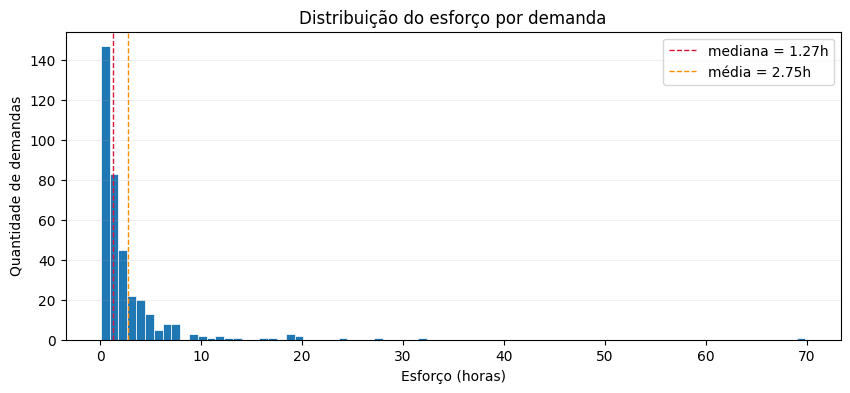

In [ ]:
plt.figure(figsize=(10, 4))
plt.hist(demandas['esforco_horas'], bins=80, edgecolor='white', linewidth=0.5)
plt.axvline(demandas['esforco_horas'].median(), color='crimson',
            linestyle='--', linewidth=1, label=f"mediana = {demandas['esforco_horas'].median():.2f}h")
plt.axvline(demandas['esforco_horas'].mean(), color='darkorange',
            linestyle='--', linewidth=1, label=f"média = {demandas['esforco_horas'].mean():.2f}h")
plt.xlabel('Esforço (horas)')
plt.ylabel('Quantidade de demandas')
plt.title('Distribuição do esforço por demanda')
plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.show()

## 3.5. Boxplot do esforço

Representação resumida da distribuição: a caixa cobre do 1º ao 3º quartil (a metade central das demandas), a linha interna marca a mediana, as hastes se estendem até 1,5 vez a amplitude interquartil e os pontos além delas são sinalizados como outliers.

Confirma a assimetria por outro ângulo — a caixa fica comprimida junto à origem e há uma quantidade expressiva de pontos à direita.

**Interpretação necessária:** esses pontos são outliers *estatísticos*, não erros de registro. São demandas grandes e legítimas, e a régua de 1,5·IQR pressupõe distribuição aproximadamente simétrica — premissa que os dados violam. Remover esses pontos apenas por estarem fora das hastes eliminaria justamente as demandas de maior valor orçamentário, que o sistema precisa saber estimar.

Por isso nenhuma regra de inclusão da Parte 4 usa o critério do boxplot: os cortes ali têm justificativa de negócio (meta-trabalho, produto interno, tarefa trivial), não estatística. O boxplot serve para **caracterizar** a distribuição e localizar os casos extremos, que são inspecionados individualmente mais adiante.


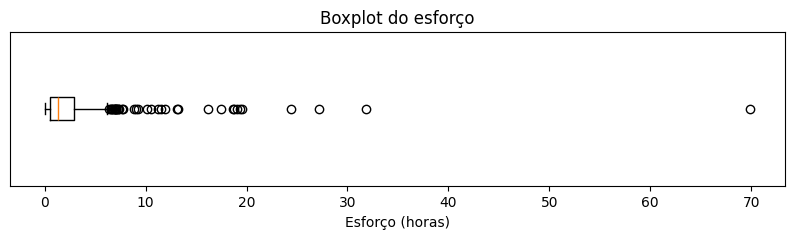

In [ ]:
plt.figure(figsize=(10, 2))
plt.boxplot(demandas['esforco_horas'], orientation='horizontal')
plt.yticks([])
plt.xlabel('Esforço (horas)')
plt.title('Boxplot do esforço')
plt.show()

## 3.6. Histograma em escala logarítmica

Reconstrução do histograma para tornar visível a faixa comprimida no gráfico linear. Aqui entra o **numpy**, biblioteca de operações numéricas que é a base sobre a qual o Pandas é construído.

**Como as faixas são construídas:** `np.logspace` gera 50 pontos igualmente espaçados no espaço logarítmico entre o menor e o maior esforço observado, e converte de volta para a escala original. O resultado são faixas de largura crescente — estreitas entre 0,25 e 1 hora, largas nas dezenas de horas. Cada faixa passa a cobrir a mesma *proporção* de crescimento, em vez do mesmo número de horas.

O `plt.xscale('log')` aplica a mesma escala ao eixo, para que as faixas apareçam com largura visual uniforme.

**Decisão metodológica a registrar:** a transformação é aplicada às **faixas do gráfico**, não aos dados. A alternativa comum — plotar `log1p(esforço)` — traria dois problemas: o eixo passaria a exibir valores logarítmicos em vez de horas, dificultando a leitura, e o `+1` distorceria desproporcionalmente a faixa abaixo de 1 hora, onde se concentra boa parte das demandas. A abordagem adotada preserva os rótulos em horas e não altera os valores.

**Resultado:** com a compressão desfeita, a distribuição assume formato aproximadamente simétrico em escala logarítmica — evidência visual da hipótese log-normal levantada nas estatísticas descritivas, e sustentação empírica para testar o treino sobre `log(esforço)` no motor de ML.


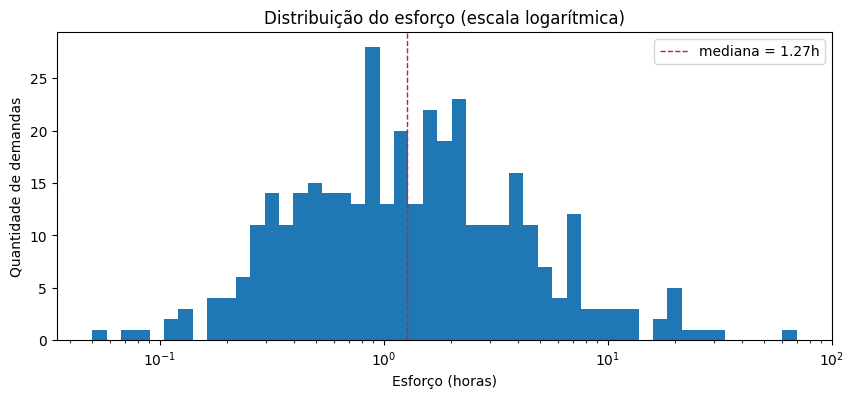

Assimetria na escala original:    7.23
Assimetria na escala logarítmica: 0.24


In [ ]:
#Distribuição usando log
import numpy as np

#Pega o esforço minimo e maximo e tranforma para log10, e gera 50 numero espaçado entre os os dois logs e eleva a 10
bins = np.logspace(np.log10(demandas['esforco_horas'].min()),
                   np.log10(demandas['esforco_horas'].max()), 50)

plt.figure(figsize=(10, 4))
#Cria um histograma com os dados e array bins
plt.hist(demandas['esforco_horas'], bins=bins)
#Cria uma regua logaritma abaixo
plt.xscale('log')
plt.xlabel('Esforço (horas)')
plt.ylabel('Quantidade de demandas')
plt.title('Distribuição do esforço (escala logarítmica)')
plt.axvline(demandas['esforco_horas'].median(), color='crimson', linestyle='--',
            linewidth=1, label=f"mediana = {demandas['esforco_horas'].median():.2f}h")
plt.legend()
plt.show()

#Assimetria do esforço antes e depois da transformação logarítmica
# 0 indica simetria; valores positivos indicam cauda longa à direita
print(102*'=')
print(f'Assimetria na escala original:    {demandas["esforco_horas"].skew():.2f}')
print(f'Assimetria na escala logarítmica: {np.log(demandas["esforco_horas"]).skew():.2f}')


## 3.7. Teste de sensibilidade do piso mínimo

Uma das regras de inclusão previstas descarta demandas triviais — trabalho de poucos minutos que nunca passaria por orçamentação e que, se mantido, ensinaria ao modelo um padrão irrelevante para o uso pretendido. A questão é onde cortar.

Esta célula quantifica o custo de cada candidato: para os pisos de 0,1 h, 0,25 h e 0,5 h, conta quantas demandas seriam removidas e que percentual da base isso representa.

**Por que testar em vez de arbitrar:** o limiar precisa equilibrar dois riscos opostos — cortar de menos mantém ruído no treino; cortar demais reduz uma base que já é pequena, comprometendo a divisão treino/teste e a capacidade de generalização do modelo.

**Resultado e decisão:** o corte em 0,5 h removeria cerca de um quinto da base, perda considerada alta demais. Adota-se **0,25 h (15 minutos)** como piso, aplicado na Parte 4.

Esta é uma das decisões que o CRISP-DM prevê como retroalimentação entre fases: uma constatação da fase de *entendimento dos dados* redefine um parâmetro da fase de *preparação*.

In [ ]:
#Faixas de demanda
for piso in [0.1, 0.25, 0.5]:
    n = (demandas['esforco_horas'] < piso).sum()
    print(f"Abaixo de {piso}: {n} demandas ({n / len(demandas) * 100:.1f}%)")

Abaixo de 0.1: 3 demandas (0.8%)
Abaixo de 0.25: 21 demandas (5.6%)
Abaixo de 0.5: 79 demandas (21.2%)


## 3.8. Distribuição das variáveis categóricas

Contagem de demandas por categoria em cada variável categórica candidata a preditora — as quatro vindas do Clockify (`cliente`, `sistema`, `tag`, `billable`) e as sete vindas do Movidesk (`categoria_ticket`, `urgencia`, `tipo_ticket`, `origem`, `servico_nv1`, `servico_nv2`, `servico_nv3`). O `dropna=False` inclui os valores nulos na contagem, evitando que dados faltantes passem despercebidos.

Três achados desta célula orientam decisões posteriores:

- **`Cliente_012` concentra 99 das 383 demandas.** Não é trabalho interno: é o agrupador dos clientes curva C, que não são cadastrados individualmente no Clockify. São demandas reais e orçadas, equivalentes a uma categoria "Outros" já pronta — e permanecem na base.
- **Categorias raras.** Várias tags aparecem pouquíssimas vezes. Categorias com frequência muito baixa não permitem aprendizado e criam um risco concreto na divisão treino/teste: se uma delas cair inteiramente no conjunto de teste, o modelo encontrará um valor nunca visto no treino. Isso motiva a regra de frequência mínima aplicada na Parte 4.
- **`Sistema_001`** aparece com volume relevante, mas é produto interno — investigado na célula seguinte.

A distribuição de `billable` também é verificada aqui, para avaliar se a variável tem variação suficiente para ser informativa.

**Duas leituras a mais, específicas das variáveis do Movidesk.** A primeira é a **cardinalidade**: uma variável com dezenas de categorias distribuídas em pouco mais de trezentas demandas produz células com uma ou duas observações e, depois do `OneHotEncoder`, dezenas de colunas — é o que decide se ela é utilizável, e o resumo impresso ao final da célula traz esse número. A segunda é a **cobertura**: os nulos não são falha de extração, e sim as demandas sem chamado formal, que a Parte 4 vai converter em categoria própria em vez de descartar.


In [ ]:
#Demandas por cliente e pelas variáveis vindas do chamado
CATEGORICAS = ['cliente', 'sistema', 'tag', 'billable',
               'categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
               'servico_nv1', 'servico_nv2', 'servico_nv3']

for col in CATEGORICAS:
    print(demandas[col].value_counts(dropna=False))
    print()

# Cardinalidade e cobertura decidem quais variáveis novas são utilizáveis
print(pd.DataFrame({
    'categorias': demandas[CATEGORICAS].nunique(),
    'nulos': demandas[CATEGORICAS].isna().sum(),
    'cobertura_%': (demandas[CATEGORICAS].notna().mean() * 100).round(1),
}).sort_values('categorias', ascending=False))

cliente
Cliente_012    74
Cliente_028    51
Cliente_011    38
Cliente_025    28
Cliente_001    24
Cliente_019    21
Cliente_005    18
Cliente_026    17
Cliente_027    16
Cliente_008    15
Cliente_021     9
Cliente_016     9
Cliente_009     9
Cliente_029     7
Cliente_018     6
Cliente_022     6
Cliente_007     5
Cliente_023     3
Cliente_014     3
Cliente_003     2
Cliente_015     2
Cliente_006     2
Cliente_030     1
Cliente_004     1
Cliente_002     1
Cliente_017     1
Cliente_013     1
Cliente_010     1
Cliente_020     1
Name: count, dtype: int64

sistema
Sistema_005    343
Sistema_002     26
Sistema_001      1
Sistema_004      1
Sistema_003      1
Name: count, dtype: int64

tag
Alteração                         179
Análise de problema                98
Nova Funcionalidade                82
Orçamento                           8
Analise de Ticket                   3
Alteração, Análise de problema      1
Sql/Update                          1
Name: count, dtype: int64

billable
No     

## 3.9. Esforço por categoria e teto de ruído

A célula anterior contou **quantas** demandas há em cada categoria; esta mostra **quanto esforço** cada uma consome.

**Por que média e mediana lado a lado.** Dada a assimetria da distribuição, a média de uma categoria pode ser inflada por uma única demanda grande. A coluna `media/mediana` mede o peso da cauda: próximo de 1 indica categoria homogênea; acima de 2, poucos casos dominam. A coluna `leitura` marca grupos com menos de cinco demandas, cuja estatística não sustenta conclusão — mas cuja raridade é informação sobre a base.

### Teto de ruído

A comparação entre medianas mostra se as categorias **se separam**, mas não quanto de incerteza sobra **dentro** de cada uma. O segundo bloco agrupa as demandas por tipo de tarefa e sistema e confronta o desvio-padrão dentro dos grupos com o do subconjunto — a decomposição da variância que fundamenta a análise de variância (ANOVA).

**A comparação é feita no mesmo subconjunto.** Confrontar o desvio interno com o da base completa seria enganoso: os grupos pequenos, descartados pelo filtro de dez ocorrências, concentram os casos extremos, e a redução viria do recorte, não das variáveis. O desvio interno é **agrupado**, com cada grupo ponderado por seus graus de liberdade; a média simples daria peso igual a grupos de tamanhos distintos. A razão entre os dois desvios fornece o **η²**, fração da variância atribuível às categorias.

**O que o η² estabelece.** Ele delimita o máximo de variância que um modelo restrito a esses preditores poderia explicar, mesmo em ajuste perfeito — teto que independe do algoritmo. É a referência contra a qual a Parte 7 deve ser lida: desempenho próximo desse limite indica que a restrição está na informação registrada, não na escolha dos modelos.

### Os três testes e o que cada um responde

**Kruskal-Wallis** — equivalente não paramétrico da ANOVA, dispensa os pressupostos de normalidade e homogeneidade de variâncias que a Parte 3 demonstrou não valerem aqui. Responde: as medianas dos grupos diferem por algo além do acaso?

**η²** — responde: de que **tamanho** é essa diferença? Com amostra suficiente, é comum um efeito pequeno ser estatisticamente significativo. Significância e relevância prática são distintas, e é a segunda que determina se a estimativa automática é viável.

**Teste de Dunn** — responde: **onde** está a diferença? O Kruskal-Wallis indica que ao menos um grupo difere, mas não qual. O Dunn compara os grupos par a par sobre os postos, com correção de Bonferroni para o acúmulo de erro em comparações múltiplas, e é o análogo não paramétrico do Tukey HSD. A distinção importa: se duas categorias não se separam estatisticamente, o modelo carrega duas colunas onde uma bastaria, e a entrada do sistema pode ser simplificada sem perda.

Esta é uma verificação exploratória. O poder preditivo de cada variável só se confirma na fase de modelagem.

In [ ]:
#Esforço por categoria e decomposição da variância
!pip install scikit-posthocs -q

from scipy.stats import kruskal
import scikit_posthocs as sp

N_MINIMO_LEITURA = 5   # abaixo disso a estatística do grupo não sustenta leitura

for col in ['sistema', 'tag', 'billable',
            'categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
            'servico_nv1', 'servico_nv2', 'servico_nv3']:

    tabela = (demandas.groupby(col)['esforco_horas']
              .agg(count='size', median='median', mean='mean', std='std')
              .sort_values('count', ascending=False)
              .round(3))

    # A média acima da mediana é a assinatura da cauda longa; explicitar evita
    # que o leitor interprete a média como valor típico do grupo
    tabela['media/mediana'] = (tabela['mean'] / tabela['median']).round(2)

    # Marca os grupos pequenos demais para sustentar leitura, em vez de omiti-los:
    # a raridade da categoria é informação sobre a base
    tabela['leitura'] = np.where(tabela['count'] >= N_MINIMO_LEITURA, '', 'n baixo')

    print(tabela.to_string())
    print()


# ---------------------------------------------------------------------------
# Decomposição da variância: os preditores do conjunto V1 reduzem a incerteza?
# ---------------------------------------------------------------------------
# A comparação é entre a dispersão do esforço DENTRO de cada combinação de
# categorias e a dispersão do subconjunto inteiro. Se a primeira não for
# sensivelmente menor, conhecer tag e sistema não informa sobre o esforço --
# e nenhum algoritmo extrai o que não está nos dados.

N_MINIMO_GRUPO = 10

grupos = demandas.groupby(['tag', 'sistema'])['esforco_horas']
grandes = grupos.size()[grupos.size() >= N_MINIMO_GRUPO].index

sub = demandas[demandas.set_index(['tag', 'sistema']).index.isin(grandes)]
g = sub.groupby(['tag', 'sistema'])['esforco_horas']

n, s = g.size(), g.std()

# Desvio agrupado (within): pondera cada grupo pelos seus graus de liberdade.
# A média simples dos desvios daria peso igual a grupos de tamanhos diferentes.
desvio_within = np.sqrt(((n - 1) * s ** 2).sum() / (n.sum() - len(n)))
desvio_total = sub['esforco_horas'].std()

# Fração da variância do esforço explicada pela combinação de categorias
eta2 = 1 - desvio_within ** 2 / desvio_total ** 2

print(f'{len(sub)} de {len(demandas)} demandas em {len(grandes)} grupos com '
      f'{N_MINIMO_GRUPO}+ ocorrências')
print(f'desvio dentro dos grupos (agrupado): {desvio_within:.2f} h')
print(f'desvio no subconjunto:               {desvio_total:.2f} h')
print(f'variância explicada pelos grupos (eta²): {eta2:.3f} '
      f'-> {eta2 * 100:.1f}% da variação do esforço')

# Kruskal-Wallis: as medianas dos grupos diferem entre si?
# Não paramétrico, apropriado à distribuição assimétrica do alvo
estatistica, p_valor = kruskal(*[valores.values for _, valores in g])
print(f'\nKruskal-Wallis: H = {estatistica:.2f}, p = {p_valor:.4f}')
print('Medianas diferem entre os grupos.' if p_valor < 0.05
      else 'Não há evidência de diferença entre as medianas dos grupos.')

# Medianas dos grupos analisados, para leitura junto do resultado acima
print()
print(g.agg(count='size', median='median', std='std').round(3).to_string())

# Post-hoc: quais pares de tipo de tarefa diferem entre si?
# O Kruskal-Wallis indica que há diferença; o teste de Dunn identifica onde ela
# está. Equivalente não paramétrico do Tukey HSD, com correção de Bonferroni
# para o acúmulo de erro em comparações múltiplas
dunn = sp.posthoc_dunn(demandas, val_col='esforco_horas',
                       group_col='tag', p_adjust='bonferroni')

print('\nValores-p por par de tipo de tarefa (abaixo de 0,05 indica diferença):')
print(dunn.round(4).to_string())

             count  median   mean     std  media/mediana  leitura
sistema                                                          
Sistema_005    343   1.190  2.358   3.631           1.98         
Sistema_002     26   3.635  8.084  13.978           2.22         
Sistema_001      1   0.070  0.070     NaN           1.00  n baixo
Sistema_003      1   0.490  0.490     NaN           1.00  n baixo
Sistema_004      1   2.250  2.250     NaN           1.00  n baixo

                                count  median   mean    std  media/mediana  leitura
tag                                                                                
Alteração                         179   1.050  2.011  3.127           1.92         
Análise de problema                98   0.910  1.742  2.939           1.91         
Nova Funcionalidade                82   3.625  5.816  9.024           1.60         
Orçamento                           8   0.840  0.864  0.502           1.03         
Analise de Ticket                

### 3.9.1. Exploração interativa: qual variável separa o esforço?

A célula anterior aplicou a decomposição da variância a `tag` e `sistema`. Esta estende o exame às demais candidatas a preditoras, com um seletor que permite percorrê-las uma a uma.

**O boxplot** mostra mediana, quartis e amplitude de cada categoria. O que importa é a **sobreposição** entre as caixas: caixas que se sobrepõem amplamente indicam que a variável não distingue o esforço, ainda que as medianas difiram. Os valores extremos são omitidos do desenho — permanecem nos dados e nos testes —, porque esticariam o eixo até 31,8 h e comprimiriam as caixas junto à base.

**O Kruskal-Wallis** testa se os grupos se separam além do acaso. O `H` mede o grau de separação, comparando as posições que cada grupo ocupa no ordenamento geral do esforço; grupos indistinguíveis produzem valor próximo de zero. O `p` converte isso em probabilidade: a chance de observar tal separação se os grupos fossem de fato iguais. Abaixo de 0,05 há diferença; acima, não há evidência suficiente. O `p` é comparável entre variáveis, o `H` não — este depende do número de grupos.

**O teste de Dunn** localiza a diferença. Um `p` significativo indica que ao menos um grupo difere, sem dizer qual; o Dunn compara os grupos par a par, com correção de Bonferroni para comparações múltiplas. Se uma variável de quatro categorias separa apenas um par, ela opera como binária, e o modelo carrega colunas que não discriminam.

**Nenhum dos testes mede o tamanho do efeito.** Com amostra suficiente, diferenças pequenas produzem `p` baixo. A leitura combina, portanto, o `p` com as medianas e com o η² da célula anterior: o primeiro indica se a diferença existe, os demais se ela é grande o bastante para sustentar uma estimativa.

Este exame é isolado por variável. A seção 3.12 mede a redundância entre elas, e a Parte 7 avalia o efeito conjunto sobre o desempenho — uma variável pode separar o esforço e ainda assim não contribuir, se sua informação já estiver presente em outra.

In [ ]:
#Aplicação interativa: distribuição do esforço e diferenças entre categorias
!pip install scikit-posthocs -q

import ipywidgets as widgets
import scikit_posthocs as sp
from scipy.stats import kruskal
from IPython.display import display, clear_output

CATEGORICAS_ANALISE = ['tag', 'sistema', 'categoria_ticket', 'urgencia',
                       'tipo_ticket', 'origem', 'servico_nv1', 'servico_nv2']

seletor = widgets.Dropdown(options=CATEGORICAS_ANALISE, value='tag',
                           description='Variável:', style={'description_width': 'auto'})
saida = widgets.Output()


def analisar(evento=None):
    variavel = seletor.value

    with saida:
        clear_output(wait=True)

        categorias = (demandas.groupby(variavel)['esforco_horas']
                      .size().sort_values(ascending=False).index)
        dados = [demandas.loc[demandas[variavel] == c, 'esforco_horas'].values
                 for c in categorias]

        # showfliers=False mantém as caixas legíveis: os valores extremos
        # esticariam o eixo até 31,8 h e comprimiriam as caixas junto à base.
        # Eles permanecem nos dados e nos testes estatísticos abaixo
        fig, eixo = plt.subplots(figsize=(8, 4.5))
        eixo.boxplot(dados, labels=[str(c) for c in categorias], showfliers=False)
        eixo.set_ylabel('Esforço (h)')
        eixo.set_xlabel(variavel.replace('_', ' '))
        eixo.set_title(f'Distribuição do esforço por {variavel.replace("_", " ")}')
        eixo.grid(axis='y', alpha=0.3)
        plt.setp(eixo.get_xticklabels(), rotation=20, ha='right')
        plt.tight_layout()
        plt.show()

        print(demandas.groupby(variavel)['esforco_horas']
              .agg(demandas='size', mediana='median', desvio='std')
              .sort_values('demandas', ascending=False).round(3).to_string())

        # Kruskal-Wallis: equivalente não paramétrico da ANOVA, dispensa os
        # pressupostos de normalidade violados por esta distribuição
        grupos = [v.values for _, v in demandas.groupby(variavel)['esforco_horas']
                  if len(v) >= 2]

        if len(grupos) < 2:
            print('\nMenos de dois grupos com tamanho suficiente para o teste.')
            return

        h, p = kruskal(*grupos)
        print(f'\nKruskal-Wallis: H = {h:.2f}, p = {p:.4f} — '
              f'{"as medianas diferem" if p < 0.05 else "sem evidência de diferença"}')

        # Dunn: identifica QUAIS pares diferem, com correção de Bonferroni para
        # o acúmulo de erro em comparações múltiplas
        if p < 0.05:
            print('\nTeste de Dunn (p < 0,05 indica que o par se separa):')
            print(sp.posthoc_dunn(demandas, val_col='esforco_horas',
                                  group_col=variavel, p_adjust='bonferroni')
                  .round(4).to_string())


seletor.observe(analisar, names='value')
display(seletor, saida)
analisar()

Dropdown(description='Variável:', options=('tag', 'sistema', 'categoria_ticket', 'urgencia', 'tipo_ticket', 'o…

Output()

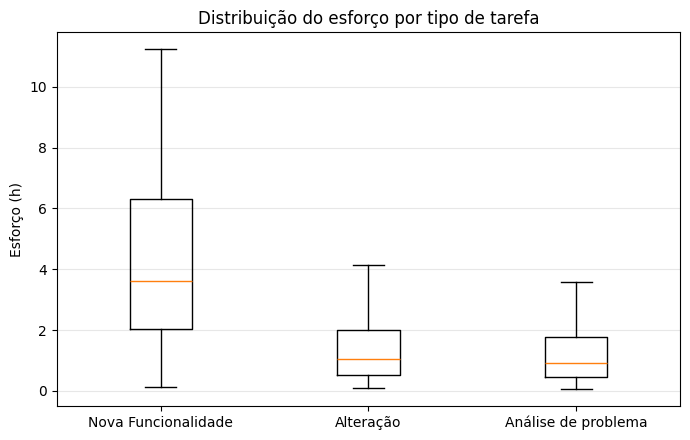

In [ ]:
#Boxplot do esforço pelos três tipos de tarefa mantidos no estudo
TIPOS = ['Nova Funcionalidade', 'Alteração', 'Análise de problema']
dados = [demandas.loc[demandas['tag'] == t, 'esforco_horas'] for t in TIPOS]

fig, eixo = plt.subplots(figsize=(7, 4.5))
eixo.boxplot(dados, tick_labels=TIPOS, showfliers=False)
eixo.set_ylabel('Esforço (h)')
eixo.set_title('Distribuição do esforço por tipo de tarefa')
eixo.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#Teste de Dunn entre os três tipos de tarefa mantidos no estudo
principais = demandas[demandas['tag'].isin(TIPOS)]
dunn = sp.posthoc_dunn(principais, val_col='esforco_horas',
                       group_col='tag', p_adjust='bonferroni')

print('Valor p por par de tipos de tarefa (abaixo de 0,05 indica diferença):\n')
for i, a in enumerate(TIPOS):
    for b in TIPOS[i + 1:]:
        p = dunn.loc[a, b]
        resultado = 'diferem' if p < 0.05 else 'não diferem'
        print(f'{a:<22} x {b:<22} p = {p:.4f}  ->  {resultado}')

Valor p por par de tipos de tarefa (abaixo de 0,05 indica diferença):

Nova Funcionalidade    x Alteração              p = 0.0000  ->  diferem
Nova Funcionalidade    x Análise de problema    p = 0.0000  ->  diferem
Alteração              x Análise de problema    p = 0.7192  ->  não diferem


In [ ]:
#Resumo: quais variáveis separam o esforço?
# Considera apenas categorias com ao menos 5 demandas, para o teste ter sustentação
linhas = []
for coluna in CATEGORICAS_ANALISE:
    grupos = [v.values for _, v in demandas.groupby(coluna)['esforco_horas'] if len(v) >= 5]
    if len(grupos) < 2:
        continue
    h, p = kruskal(*grupos)
    linhas.append({
        'Variável': coluna,
        'Categorias': demandas[coluna].nunique(),
        'Maior categoria (%)': round(demandas[coluna].value_counts(normalize=True).iloc[0] * 100, 1),
        'H': round(h, 2),
        'p': round(p, 4),
    })

print(pd.DataFrame(linhas).sort_values('H', ascending=False).to_string(index=False))

        Variável  Categorias  Maior categoria (%)     H      p
             tag           7                 48.1 73.21 0.0000
     servico_nv1          20                 82.0 20.62 0.0004
categoria_ticket           4                 58.1 17.06 0.0002
         sistema           5                 92.2 16.36 0.0001
        urgencia           5                 88.7 11.70 0.0085
     servico_nv2           7                 88.7 11.13 0.0110
          origem           5                 70.2  2.66 0.2639
     tipo_ticket           2                 94.1  2.18 0.1403


## 3.10. Inspeção individual dos casos extremos

Três blocos: os critérios estatísticos de detecção, um teste de erro de registro e a listagem das dez maiores demandas.

**Por que os limiares não decidem sozinhos.** A regra de Tukey (Q3 + 1,5·IQR) e o escore-z padronizado pressupõem simetria. Aplicados à escala bruta de uma variável log-normal, classificam a cauda natural como anomalia, e removê-la eliminaria justamente as demandas de maior valor orçamentário — as que o sistema mais precisa saber estimar. Na escala logarítmica, onde a distribuição é aproximadamente simétrica, a mesma regra de Tukey sinaliza poucos casos.

**Os três métodos divergem, e a divergência é informativa.** O escore-z padronizado sinaliza menos casos que o escore-z modificado, contrariando a expectativa de que o método robusto seja mais conservador. A razão é o **mascaramento**: média e desvio-padrão são calculados sobre a base já contaminada pelos valores extremos, o que infla o desvio e afasta o limiar de três desvios muito além do razoável — os outliers encobrem uns aos outros. O escore-z modificado, apoiado em mediana e desvio absoluto mediano (MAD), não sofre essa distorção e mantém eficácia em distribuições assimétricas. O menor número de sinalizações do método clássico indica insensibilidade, não ausência de casos extremos.

**O teste que separa erro de demanda grande.** Esforço elevado distribuído em muitas sessões caracteriza trabalho real de longa duração; concentrado em poucas sessões, é o padrão do cronômetro esquecido ligado — caso que não aparece ao ordenar pelo total. A razão entre esforço e número de sessões isola o padrão: média por sessão acima de uma jornada é fisicamente implausível.

**A decisão é por conteúdo.** Nenhum critério remove demandas automaticamente; todos apenas direcionam a inspeção. A listagem das dez maiores permite verificar se categorias, esforço e número de sessões são coerentes entre si.

**Resultado:** nenhuma demanda apresentou média por sessão superior a uma jornada, e os casos revisados se confirmaram legítimos. Permanecem integralmente na base.

In [ ]:
#Casos extremos: critérios de detecção, teste de registro e inspeção
esforco = demandas['esforco_horas']

# Regra de Tukey: pressupõe simetria, que só vale na escala logarítmica
q1, q3 = esforco.quantile([0.25, 0.75])
limite_bruto = q3 + 1.5 * (q3 - q1)
lq1, lq3 = np.log(esforco).quantile([0.25, 0.75])
limite_log = np.exp(lq3 + 1.5 * (lq3 - lq1))

# Escore-z clássico, inflado pelos próprios extremos, e modificado, baseado na mediana
z_classico = (esforco - esforco.mean()) / esforco.std()
mad = (esforco - esforco.median()).abs().median()
z_modificado = 0.6745 * (esforco - esforco.median()) / mad

metodos = [
    ('Tukey, escala bruta',       f'> {limite_bruto:.2f} h', (esforco > limite_bruto).sum()),
    ('Tukey, escala logarítmica', f'> {limite_log:.2f} h',   (esforco > limite_log).sum()),
    ('Escore-z clássico',         '|z| > 3',                 (z_classico.abs() > 3).sum()),
    ('Escore-z modificado',       '|z| > 4',                 (z_modificado.abs() > 4).sum()),
]

print(f'{"Método":<28}{"Limiar":<14}{"Demandas":>9}{"% da base":>11}')
print('-' * 62)
for metodo, limiar, n in metodos:
    print(f'{metodo:<28}{limiar:<14}{n:>9}{n / len(demandas):>11.1%}')

# Esforço alto concentrado em poucas sessões indica cronômetro esquecido ligado
horas_por_sessao = esforco / demandas['qtd_sessoes']
print(f'\nDemandas com média por sessão acima de 8 h: {(horas_por_sessao > 8).sum()}')

print('\nDez maiores demandas:')
maiores = demandas.assign(horas_por_sessao=horas_por_sessao).nlargest(10, 'esforco_horas')
print(maiores[['chamado_mascarado', 'tag', 'esforco_horas', 'qtd_sessoes',
               'horas_por_sessao']].round(2).to_string(index=False))

Método                      Limiar         Demandas  % da base
--------------------------------------------------------------
Tukey, escala bruta         > 6.29 h             37       9.9%
Tukey, escala logarítmica   > 32.79 h             1       0.3%
Escore-z clássico           |z| > 3               9       2.4%
Escore-z modificado         |z| > 4              37       9.9%

Demandas com média por sessão acima de 8 h: 0

Dez maiores demandas:
chamado_mascarado                 tag  esforco_horas  qtd_sessoes  horas_por_sessao
      Chamado_142 Nova Funcionalidade          69.86           56              1.25
      Chamado_220 Nova Funcionalidade          31.80           33              0.96
      Chamado_369           Alteração          27.13           18              1.51
      Chamado_182 Nova Funcionalidade          24.41           37              0.66
      Chamado_295 Nova Funcionalidade          19.57           15              1.30
      Chamado_013 Nova Funcionalidade          1

## 3.11. Confronto entre as duas fontes de tempo

Clockify e Movidesk medem o mesmo trabalho por caminhos independentes: o primeiro soma as sessões de cronômetro apontadas pelo desenvolvedor; o segundo acumula, em `tempo_util_ticket`, o tempo em que o chamado esteve aberto dentro do horário de expediente. Confrontar os dois é uma **validação cruzada da base** — se as duas fontes discordassem por completo, ao menos uma estaria registrando outra coisa que não o esforço da demanda.

Duas medidas de correlação, porque respondem a perguntas diferentes:

- **Pearson** mede associação linear e é sensível à cauda longa que a célula 3.3 documentou: uma única demanda de sessenta horas domina o coeficiente.
- **Spearman** opera sobre postos e responde à pergunta que de fato importa aqui — se as demandas que o Clockify aponta como maiores são também as que o Movidesk registra como mais longas.

**Isto não é um preditor.** `tempo_util_ticket` só existe depois que o chamado é fechado, e no momento de orçar não há valor algum a consultar. A célula está na exploratória porque descreve a base, e o campo permanece fora do modelo — a Parte 7 volta ao assunto com um experimento que mede exatamente o que aconteceria se essa regra fosse quebrada.


355 demandas com as duas medidas disponíveis
Correlação de Pearson:  0.230
Correlação de Spearman: 0.395

Mediana do esforço apontado: 1.25 h
Mediana do tempo útil:       0.96 h
Demandas com tempo útil menor que o esforço: 205 (57.7%)


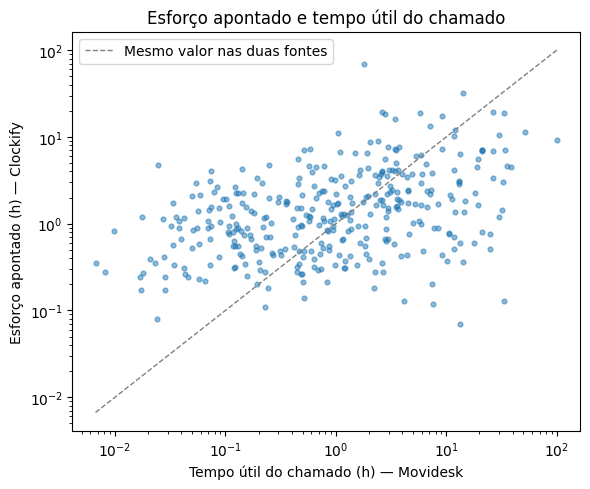

In [ ]:
#Confronto entre o esforço apontado no Clockify e o tempo útil registrado no Movidesk
comparavel = demandas[['esforco_horas', 'tempo_util_ticket']].dropna()
menor = (comparavel['tempo_util_ticket'] < comparavel['esforco_horas'])

print(f'{len(comparavel)} demandas com as duas medidas disponíveis')
print(f"Correlação de Pearson:  {comparavel['esforco_horas'].corr(comparavel['tempo_util_ticket']):.3f}")
print(f"Correlação de Spearman: {comparavel['esforco_horas'].corr(comparavel['tempo_util_ticket'], method='spearman'):.3f}")
print(f"\nMediana do esforço apontado: {comparavel['esforco_horas'].median():.2f} h")
print(f"Mediana do tempo útil:       {comparavel['tempo_util_ticket'].median():.2f} h")
print(f"Demandas com tempo útil menor que o esforço: {menor.sum()} ({menor.mean():.1%})")

plt.figure(figsize=(6, 5))
plt.scatter(comparavel['tempo_util_ticket'], comparavel['esforco_horas'], s=12, alpha=0.5)
limite = [comparavel.min().min(), comparavel.max().max()]
plt.plot(limite, limite, '--', color='gray', lw=1, label='Mesmo valor nas duas fontes')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Tempo útil do chamado (h) — Movidesk')
plt.ylabel('Esforço apontado (h) — Clockify')
plt.title('Esforço apontado e tempo útil do chamado')
plt.legend()
plt.tight_layout()
plt.show()

## 3.12. Associação entre as variáveis categóricas

As seções anteriores caracterizaram cada variável isoladamente — quantas categorias possui, como o esforço se distribui entre elas. Esta examina como as variáveis se relacionam **entre si**, o que determina se o conjunto de preditores carrega tanta informação quanto o número de colunas sugere.

**Por que não a matriz de correlação usual.** O coeficiente de Pearson mede associação linear entre variáveis numéricas contínuas. Aplicá-lo aqui produziria valores sem significado: os códigos das variáveis categóricas são rótulos, não quantidades, e a distância entre `tipo_tarefa = 1` e `tipo_tarefa = 3` não representa grandeza alguma. A medida adequada é o **V de Cramér**, derivado da estatística qui-quadrado de independência e normalizado no intervalo de 0 a 1, em que 0 indica independência entre as variáveis e 1 indica que uma determina completamente a outra.

**O que a redundância significa para a modelagem.** Duas variáveis fortemente associadas ocupam colunas distintas na matriz codificada, mas contribuem com a mesma informação. O modelo ganha graus de liberdade sem ganhar poder discriminativo — condição em que o ajuste passa a incorporar ruído dos dados de treino, com perda de desempenho fora da amostra. O efeito é tanto mais severo quanto menor a razão entre número de observações e número de colunas, aspecto medido diretamente na seção 7.6.

**O que se busca aqui.** Identificar pares em que uma das variáveis pode ser dispensada sem perda, e antecipar quanto do conjunto enriquecido constitui informação efetivamente nova em relação ao conjunto original do Clockify. O limiar de 0,70 adotado na listagem é convencional e serve à leitura: não define regra de exclusão, mas sinaliza os pares que merecem exame.

Esta é uma análise exploratória. O efeito da redundância sobre o desempenho preditivo é medido na Parte 7, sob validação cruzada, e não se deduz da matriz.

In [ ]:
#Associação entre as variáveis categóricas — V de Cramér
from scipy.stats import chi2_contingency
from itertools import combinations

def v_cramer(a, b):
    """Associação entre duas categóricas, de 0 (independentes) a 1 (redundantes)."""
    tabela = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabela)[0]
    n = tabela.values.sum()
    return np.sqrt((chi2 / n) / (min(tabela.shape) - 1))

VARIAVEIS = ['sistema', 'tag', 'cliente', 'categoria_ticket',
             'urgencia', 'tipo_ticket', 'origem', 'servico_nv1', 'servico_nv2',
             'sistema_erp']

matriz = pd.DataFrame(1.0, index=VARIAVEIS, columns=VARIAVEIS)
for a, b in combinations(VARIAVEIS, 2):
    matriz.loc[a, b] = matriz.loc[b, a] = v_cramer(demandas[a], demandas[b])

print(matriz.round(2).to_string())

# Pares redundantes: carregam praticamente a mesma informação
print('\nPares com associação acima de 0,7:')
for a, b in combinations(VARIAVEIS, 2):
    if matriz.loc[a, b] > 0.7:
        print(f'  {a} ↔ {b}: {matriz.loc[a, b]:.2f}')

                  sistema   tag  cliente  categoria_ticket  urgencia  tipo_ticket  origem  servico_nv1  servico_nv2  sistema_erp
sistema              1.00  0.51     0.38              0.08      0.04         0.16    0.07         0.82         0.26         0.71
tag                  0.51  1.00     0.33              0.36      0.09         0.10    0.12         0.50         0.22         0.31
cliente              0.38  0.33     1.00              0.28      0.41         0.36    0.37         0.30         0.34         0.65
categoria_ticket     0.08  0.36     0.28              1.00      0.13         0.07    0.08         0.25         0.14         0.12
urgencia             0.04  0.09     0.41              0.13      1.00         0.27    0.07         0.15         0.07         0.10
tipo_ticket          0.16  0.10     0.36              0.07      0.27         1.00    0.14         0.19         0.17         0.05
origem               0.07  0.12     0.37              0.08      0.07         0.14    1.00        

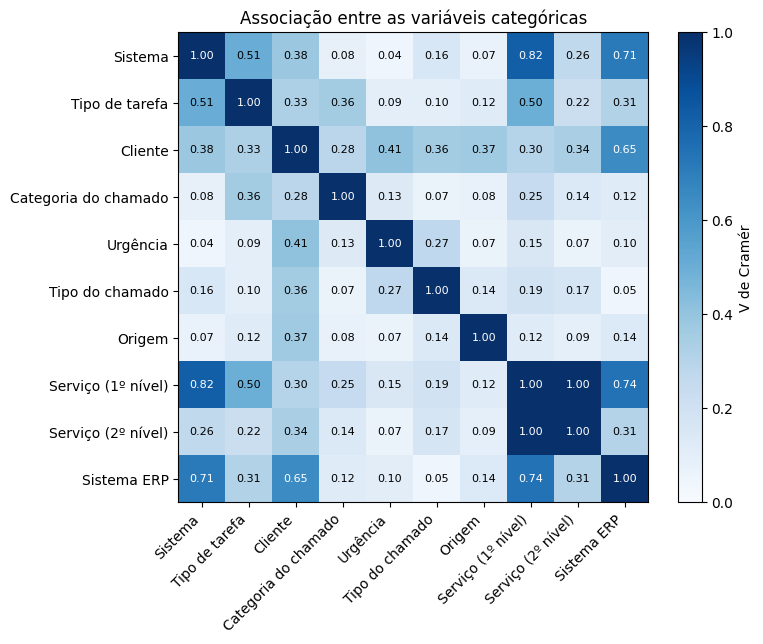

In [ ]:
#Mapa de calor da associação entre as variáveis
fig, eixo = plt.subplots(figsize=(8, 6.5))
imagem = eixo.imshow(matriz.values, cmap='Blues', vmin=0, vmax=1)

# Nomes por extenso nos eixos, os mesmos usados no texto e na Tabela 3
NOMES_LEGIVEIS = {
    'sistema': 'Sistema', 'tag': 'Tipo de tarefa', 'cliente': 'Cliente',
    'categoria_ticket': 'Categoria do chamado', 'urgencia': 'Urgência',
    'tipo_ticket': 'Tipo do chamado', 'origem': 'Origem',
    'servico_nv1': 'Serviço (1º nível)', 'servico_nv2': 'Serviço (2º nível)',
    'sistema_erp': 'Sistema ERP',
}
rotulos = [NOMES_LEGIVEIS[v] for v in VARIAVEIS]
eixo.set_xticks(range(len(VARIAVEIS)), rotulos, rotation=45, ha='right')
eixo.set_yticks(range(len(VARIAVEIS)), rotulos)

for i in range(len(VARIAVEIS)):
    for j in range(len(VARIAVEIS)):
        valor = matriz.iloc[i, j]
        eixo.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=8,
                  color='white' if valor > 0.6 else 'black')

fig.colorbar(imagem, ax=eixo, label='V de Cramér')
eixo.set_title('Associação entre as variáveis categóricas')
plt.tight_layout()
plt.show()

## 3.13. Agrupamento não supervisionado: há estrutura que os preditores não capturam?

As seções anteriores mediram, por diferentes caminhos, o quanto as variáveis disponíveis explicam o esforço. Todas partiram do paradigma supervisionado, em que o alvo é conhecido e se avalia a capacidade dos preditores de reproduzi-lo. Esta seção inverte a abordagem.

**A pergunta é outra.** Ignorando as categorias registradas, as demandas formam agrupamentos naturais quanto ao porte? E, formando, esses agrupamentos coincidem com o que o processo registra? A resposta separa duas hipóteses distintas sobre a limitação diagnosticada: se há estrutura que os atributos não acompanham, o problema é de **ausência de variáveis** — o processo não registra o que determina o esforço; se não há estrutura alguma, o esforço é genuinamente irregular, e nenhum atributo adicional resolveria.

**Por que apenas duas variáveis entram no agrupamento.** O K-means particiona o espaço por distância euclidiana, o que pressupõe escala métrica. Categorias codificadas em colunas binárias não satisfazem essa condição: a distância entre duas categorias não tem significado numérico. O agrupamento usa, portanto, `esforco_horas` e `qtd_sessoes`, as únicas contínuas — e é exatamente isso que torna o confronto posterior informativo, já que os grupos são formados **sem** acesso às categorias que se quer avaliar.

**A padronização por z-score é obrigatória antes do agrupamento.** Sem ela, a variável de maior amplitude domina o cálculo da distância, e os grupos refletiriam a escala de medida em vez da similaridade entre demandas.

**A escolha de k combina dois critérios.** O método do cotovelo observa onde o ganho de inércia — soma das distâncias internas aos centroides — deixa de compensar o acréscimo de grupos. O coeficiente de silhueta mede simultaneamente a coesão interna e a separação externa de cada agrupamento, variando de −1 a 1, e permite escolha menos subjetiva que a inspeção visual do cotovelo.

**O confronto usa o índice de Rand ajustado**, que compara duas partições dos mesmos dados e corrige a concordância esperada por acaso: 0 indica que as partições coincidem apenas ao acaso, 1 indica correspondência perfeita. Valores próximos de zero significam que conhecer a categoria de uma demanda nada informa sobre o grupo a que ela pertence — ou seja, que as categorias registradas e o porte real da demanda são dimensões independentes.

A tabela cruzada complementa o índice: se cada categoria distribui suas demandas pelos grupos em proporções semelhantes, ela não identifica o porte, por mais que o teste de Kruskal-Wallis aponte diferença entre medianas.

 k  inercia  silhueta
 2 4249.654     0.887
 3 1817.592     0.848
 4  810.775     0.725
 5  503.676     0.644
 6  312.993     0.642
 7  201.496     0.613
 8  122.975     0.624

Maior silhueta em k = 2

             demandas  minimo  mediana  maximo
faixa                                         
Menor porte       361    0.05     1.20   13.24
Maior porte        11   16.21    19.34   69.86
Intervalo vazio entre 13.24 h e 16.21 h

As categorias registradas identificam a faixa?
  tag        -> 0.014
  sistema    -> 0.149
  combinados -> 0.023

Distribuição das faixas nos tipos principais (%):
faixa                Maior porte  Menor porte
tag                                          
Alteração                    1.1         98.9
Análise de problema          2.0         98.0
Nova Funcionalidade          8.5         91.5


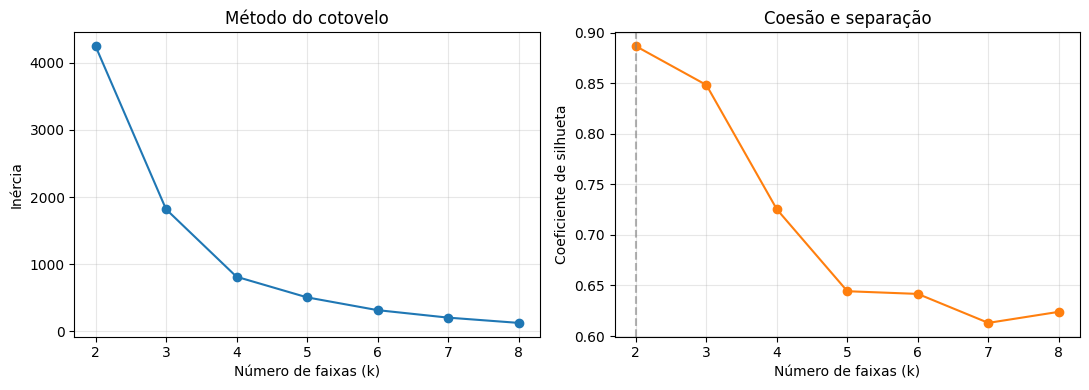

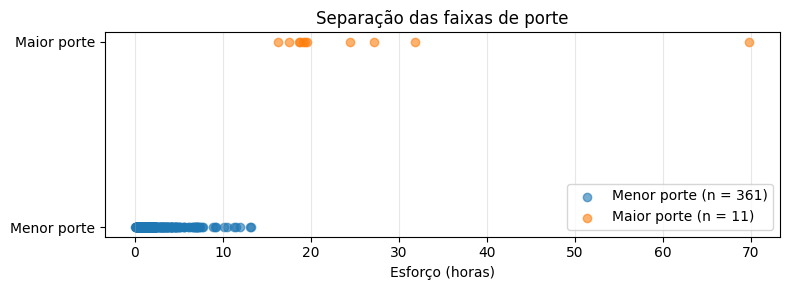

In [ ]:
# Agrupamento das demandas por porte (K-means sobre o esforço)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Só o esforço entra no agrupamento: os grupos se formam sem acesso às categorias
M = demandas[['esforco_horas']].to_numpy()

diagnostico = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(M)
    diagnostico.append({'k': k, 'inercia': km.inertia_,
                        'silhueta': silhouette_score(M, km.labels_)})
diagnostico = pd.DataFrame(diagnostico)
print(diagnostico.round(3).to_string(index=False))

K_ESCOLHIDO = int(diagnostico.loc[diagnostico['silhueta'].idxmax(), 'k'])
print(f'\nMaior silhueta em k = {K_ESCOLHIDO}\n')

kmeans = KMeans(n_clusters=K_ESCOLHIDO, n_init=10, random_state=SEMENTE).fit(M)

# Rótulos do K-means são arbitrários: renumera do menor para o maior centro
ordem = np.argsort(kmeans.cluster_centers_.ravel())
faixa = pd.Series(np.argsort(ordem)[kmeans.labels_], index=demandas.index, name='faixa')
NOMES_FAIXA = ({0: 'Menor porte', 1: 'Maior porte'} if K_ESCOLHIDO == 2
               else {i: f'Faixa {i + 1}' for i in range(K_ESCOLHIDO)})

# Tabela 5
perfil = (demandas.groupby(faixa)['esforco_horas']
          .agg(demandas='size', minimo='min', mediana='median', maximo='max')
          .rename(index=NOMES_FAIXA))
print(perfil.round(2).to_string())
for i in range(K_ESCOLHIDO - 1):
    print(f'Intervalo vazio entre {perfil["maximo"].iloc[i]:.2f} h '
          f'e {perfil["minimo"].iloc[i + 1]:.2f} h')

# Índice de Rand ajustado: 0 = coincidência ao acaso, 1 = partições idênticas
print('\nAs categorias registradas identificam a faixa?')
combinado = demandas['tag'].astype(str) + ' | ' + demandas['sistema'].astype(str)
for nome, rotulos in [('tag', demandas['tag']), ('sistema', demandas['sistema']),
                      ('combinados', combinado)]:
    print(f'  {nome:10} -> {adjusted_rand_score(rotulos, faixa):.3f}')

TIPOS_PRINCIPAIS = ['Alteração', 'Análise de problema', 'Nova Funcionalidade']
principais = demandas['tag'].isin(TIPOS_PRINCIPAIS)
print('\nDistribuição das faixas nos tipos principais (%):')
print((pd.crosstab(demandas.loc[principais, 'tag'], faixa[principais].map(NOMES_FAIXA),
                   normalize='index') * 100).round(1).to_string())

# Figura 18: cotovelo e silhueta
fig, (esq, dir) = plt.subplots(1, 2, figsize=(11, 4))
esq.plot(diagnostico['k'], diagnostico['inercia'], marker='o')
esq.set(xlabel='Número de faixas (k)', ylabel='Inércia', title='Método do cotovelo')
esq.grid(alpha=0.3)
dir.plot(diagnostico['k'], diagnostico['silhueta'], marker='o', color='tab:orange')
dir.axvline(K_ESCOLHIDO, linestyle='--', color='gray', alpha=0.6)
dir.set(xlabel='Número de faixas (k)', ylabel='Coeficiente de silhueta',
        title='Coesão e separação')
dir.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Figura 19: cada demanda no eixo do esforço, colorida pela faixa
fig, eixo = plt.subplots(figsize=(8, 3))
for f in range(K_ESCOLHIDO):
    valores = demandas.loc[faixa == f, 'esforco_horas']
    eixo.scatter(valores, [f] * len(valores), alpha=0.6,
                 label=f'{NOMES_FAIXA[f]} (n = {len(valores)})')
eixo.set_yticks(range(K_ESCOLHIDO), [NOMES_FAIXA[f] for f in range(K_ESCOLHIDO)])
eixo.set_xlabel('Esforço (horas)')
eixo.set_title('Separação das faixas de porte')
eixo.grid(axis='x', alpha=0.3)
eixo.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Parte 4 — Regras de inclusão

Aplicação sequencial dos critérios que definem quais demandas compõem o conjunto de treino. Cada regra tem justificativa de negócio — não estatística — e é registrada individualmente, para compor o quadro de exclusões da metodologia.

## 4.1. Preparação: referência temporal e registro do funil

Três providências antes da primeira regra:

**Releitura da base completa.** O ponto de partida é `demandas.csv`, sem nenhum filtro aplicado — as decisões da Parte 3 são executadas aqui, não antes.

**`FIM_COLETA` fixado no início.** Guarda a data da última sessão registrada, referência para a regra de censura temporal. A ordem importa: se o valor fosse calculado depois dos outros filtros, a janela de corte escorregaria conforme as regras removessem linhas — o limite passaria a depender de quais demandas sobreviveram, e não do período real de coleta. Calcular antes torna a referência estável e o critério reproduzível.

**Função `registrar`.** Cada regra chama esta função com o total antes e depois de sua aplicação. Ela acumula os números na lista `funil` e imprime o efeito imediato.

O registro sistemático não é acessório: a rastreabilidade das exclusões é requisito metodológico. Ao final, `funil` vira a tabela que documenta, no TCC, quantas demandas cada critério removeu e quantas restaram — permitindo ao leitor auditar o caminho da base bruta até o dataset de treino.

In [ ]:
#Le csv e define tipo de dados nas datas
demandas = pd.read_csv('demandas.csv', parse_dates=['data_inicio', 'data_fim'])

# Data da última sessão, fixada antes das regras para servir de referência à censura temporal
FIM_COLETA = demandas['data_fim'].max()

funil = []

def registrar(nome, antes, depois):
    funil.append({'regra': nome, 'antes': antes, 'removidas': antes - depois, 'depois': depois})
    print(f"{nome}: {antes} → {depois} ({antes - depois} removidas)")

print(f"Base inicial: {len(demandas)} demandas | fim da coleta: {FIM_COLETA.date()}")

Base inicial: 372 demandas | fim da coleta: 2026-09-29


## 4.2. Linha de base do processo manual de orçamentação

Antes de remover as demandas com tag `Orçamento`, seu conteúdo é quantificado — porque o dado tem valor próprio para o trabalho.

A tag marca o tempo gasto **lendo a demanda e estimando as horas**: é meta-trabalho sobre o processo de orçamentação, não execução de demanda de BI. Por isso não pode entrar no treino, já que o modelo aprenderia a prever o esforço de estimar, não o de desenvolver.

**O que se mede aqui:** quantas estimativas manuais foram produzidas no período, quantas horas custaram e que percentual representam do esforço total.

**Para que serve:** é a linha de base quantitativa do método atual, insumo direto do **objetivo específico 7** — avaliar se o modelo pode apoiar a orçamentação em comparação com a estimativa manual. O custo do processo manual é uma das dimensões dessa comparação: se o sistema produz estimativas de qualidade equivalente em tempo desprezível, essas horas passam a ser ganho mensurável.

**Ressalva:** são 12 demandas, amostra pequena — a comparação é indicativa, não conclusiva. Cabe registrar como limitação no texto.


In [ ]:
orcamentos = demandas[demandas['tag'] == 'Orçamento']
print(f"{len(orcamentos)} demandas de orçamento manual")
print(f"{orcamentos['esforco_horas'].sum():.2f}h gastas produzindo estimativas manualmente")
print(f"{orcamentos['esforco_horas'].sum() / demandas['esforco_horas'].sum() * 100:.1f}% do esforço total do período")

8 demandas de orçamento manual
6.91h gastas produzindo estimativas manualmente
0.7% do esforço total do período


## 4.3. Regra 1 — Remoção do meta-trabalho de orçamentação

Primeira regra do funil: exclui as demandas com tag `Orçamento`, pelo motivo detalhado na célula anterior — representam o esforço de *estimar* uma demanda, não o de *executá-la*. Mantê-las contaminaria o treino com registros cujo alvo mede outra coisa.

O padrão que se repete nas próximas regras: guarda o total em `antes`, aplica o filtro, renumera o índice e chama `registrar` com uma descrição que já traz a justificativa. O texto passado como nome da regra é o que aparecerá na tabela de exclusões do TCC — por isso é redigido como justificativa, e não como rótulo técnico.


In [ ]:
antes = len(demandas)
demandas = demandas[demandas['tag'] != 'Orçamento'].reset_index(drop=True)
registrar('Fora de escopo: tag Orçamento (meta-trabalho, não execução)', antes, len(demandas))

Fora de escopo: tag Orçamento (meta-trabalho, não execução): 372 → 364 (8 removidas)


## 4.4. Regra 2 — Remoção do produto interno

Exclui as demandas do `Sistema_001` (IBS BI), produto desenvolvido para uso da própria empresa.

**Justificativa:** 100% dessas demandas são registradas sem chamado formal e nunca passam por orçamentação. Como o sistema se destina a apoiar a estimativa de demandas **orçadas a cliente**, esses registros pertencem a um processo distinto — não têm o vínculo com estimativa que o modelo precisa aprender, e sua dinâmica de trabalho (sem prazo negociado, sem escopo fechado) difere da que caracteriza a demanda contratada.

**Distinção importante para o texto:** este é o único caso de trabalho verdadeiramente interno da base. Não confundir com `Cliente_012` (IBS Sistemas), que apesar do nome agrupa os clientes curva C — demandas reais e orçadas, que permanecem no estudo.


In [ ]:
antes = len(demandas)
demandas = demandas[demandas['sistema'] != 'Sistema_001'].reset_index(drop=True)
demandas = demandas[demandas['sistema'] != 'Sistema_004'].reset_index(drop=True)
registrar('Fora de escopo: produto interno (Sistema_001 e 004 — sem chamado formal)', antes, len(demandas))

Fora de escopo: produto interno (Sistema_001 e 004 — sem chamado formal): 364 → 362 (2 removidas)


## 4.5. Regra 3 — Piso mínimo de esforço

Exclui demandas com menos de 0,25 h (15 minutos) de esforço total.

**Justificativa:** tarefas dessa magnitude são ajustes pontuais que na prática nunca passam por orçamentação — o custo de estimá-las supera o de executá-las. Mantê-las no treino ensinaria ao modelo um segmento que não corresponde ao uso pretendido do sistema, além de concentrar massa na faixa mais ruidosa da distribuição, onde pequenas variações de apontamento têm peso relativo grande.

**Origem do limiar:** o valor não é arbitrário — vem do teste de sensibilidade da Parte 3, que mediu o custo de cada corte candidato. O piso de 0,5 h removeria cerca de um quinto da base, perda alta demais para um dataset já pequeno; 0,25 h equilibra a limpeza do ruído com a preservação do volume necessário à divisão treino/teste.

Registrar essa origem no TCC é o que transforma o corte em critério defensável, e não em escolha conveniente.


In [ ]:
antes = len(demandas)
demandas = demandas[demandas['esforco_horas'] >= 0.25].reset_index(drop=True)
registrar('Triviais: esforço < 0,25h (não passam por orçamentação)', antes, len(demandas))

Triviais: esforço < 0,25h (não passam por orçamentação): 362 → 343 (19 removidas)


## 4.6. Regra 4 — Censura temporal

Exclui demandas cuja última sessão ocorreu nos 5 dias finais do período de coleta.

**O problema que resolve:** o `esforco_horas` é a soma do trabalho **já apontado**. Uma demanda que ainda está em andamento no momento da exportação aparece na base com esforço parcial — e entraria no treino como se aquele valor fosse o total. O modelo aprenderia a subestimar sistematicamente.

Quanto mais recente a última sessão, maior a chance de a demanda seguir ativa. A regra descarta essa janela final, aceitando perder alguns registros válidos para evitar contaminar o alvo com valores truncados.

**Por que a referência foi fixada antes:** `FIM_COLETA` foi calculado na primeira célula desta parte, sobre a base intacta. Se fosse calculado aqui, refletiria apenas as demandas sobreviventes às regras anteriores, e a janela deixaria de corresponder ao fim real da coleta.

**Limitação a declarar no texto:** a censura captura o caso "ainda em andamento" pela borda recente, mas não detecta uma demanda antiga que voltará a receber trabalho — reabertura de chamado, por exemplo. Nenhum critério baseado apenas em datas resolve isso; seria necessário o status real do chamado, informação não disponível no export do Clockify.


In [ ]:
antes = len(demandas)
corte = FIM_COLETA - pd.Timedelta(days=5)
demandas = demandas[demandas['data_fim'] <= corte].reset_index(drop=True)
registrar('Censura: demandas possivelmente em andamento (últimos 5 dias)', antes, len(demandas))

Censura: demandas possivelmente em andamento (últimos 5 dias): 343 → 339 (4 removidas)


## 4.7. Regra 5 — Exclusão pontual de projeto interno

Remove o `Chamado_142`, projeto desenvolvido para uso interno da empresa e não orçado a cliente.

**Justificativa:** mesmo motivo da Regra 2 — está fora do universo de demandas que o sistema se propõe a estimar. A diferença é que este caso não é identificável por nenhum atributo da base: o chamado está registrado sob um cliente e um sistema normais, e só o conhecimento do contexto de negócio revela sua natureza.

**Ressalva metodológica a assumir no texto:** esta é a única regra do funil que remove um registro específico em vez de aplicar um critério generalizável. Exclusões nominais são frágeis — não sobrevivem a uma reexportação dos dados (o código mascarado pode mudar) e não podem ser auditadas a partir dos dados publicados. Justifica-se por ser um caso isolado, com motivo documentado e efeito quantificado no funil; a alternativa seria mantê-lo, sabendo que representa um processo distinto do estudado.


In [ ]:
antes = len(demandas)
demandas = demandas[demandas['chamado_mascarado'] != 'Chamado_142'].reset_index(drop=True)
registrar('Fora de escopo: projeto para uso interno da empresa (não orçado a cliente)', antes, len(demandas))

Fora de escopo: projeto para uso interno da empresa (não orçado a cliente): 339 → 338 (1 removidas)


## 4.8. Regra 6 — Frequência mínima por categoria

Última regra do funil: remove demandas cujo valor de `tag` **ou** de `sistema` aparece menos de 5 vezes na base.

**Justificativa:** categorias raras trazem dois problemas. Não há exemplos suficientes para o modelo aprender qualquer padrão associado a elas, e há risco concreto na divisão treino/teste — se todas as ocorrências de uma categoria caírem no conjunto de teste, o modelo encontrará um valor nunca visto no treino, situação que a maioria dos algoritmos não trata bem.

**Escrita como limiar, não como lista.** O critério é o parâmetro `MIN_OCORRENCIAS`, e as categorias a remover são calculadas a partir dele. Diferentemente da regra anterior, isto é generalizável: sobrevive a uma reexportação dos dados e é auditável como critério, não como escolha de nomes. O mesmo limiar vale para as duas colunas — não há argumento para tratar sistema raro como diferente de tag rara.

**Precisa ser a última regra.** É a única do funil sensível à ordem: a contagem é feita sobre quem sobreviveu a todas as regras anteriores. Aplicá-la antes produziria contagens de uma base que ainda continha registros posteriormente descartados, e categorias diferentes seriam classificadas como raras.

**As duas colunas interagem.** Remover sistemas raros altera a contagem das tags, e vice-versa — em tese, a regra deveria ser reaplicada até estabilizar. Nesta base a convergência ocorre em uma única passada, o que foi verificado recontando as duas colunas após a aplicação. Registrado aqui porque a propriedade depende dos dados, não do critério: uma base diferente poderia exigir repetição.

**Resultado:** restam três tags — `Alteração`, `Análise de problema` e `Nova Funcionalidade` — e dois sistemas, correspondentes a Power BI e a relatórios de sistema. O sistema removido tinha uma única demanda no período.

**Consequência para o formulário web:** o cadastro deve oferecer essas categorias em campo de seleção fechado, nunca em texto livre. O modelo só sabe estimar o que viu no treino; permitir entrada livre produziria categorias desconhecidas em produção. Isso vale também para o tipo de projeto — que, nos dados reais, se reduz a duas opções.

In [ ]:
MIN_OCORRENCIAS = 5

for coluna in ['tag', 'sistema']:
  antes = len(demandas)
  contagem = demandas[coluna].value_counts()
  raras = contagem[contagem < MIN_OCORRENCIAS].index

  demandas = demandas[~demandas[coluna].isin(raras)].reset_index(drop=True)

  registrar(f'Categorias raras em {coluna}: menos de {MIN_OCORRENCIAS} ocorrências', antes, len(demandas))

Categorias raras em tag: menos de 5 ocorrências: 338 → 337 (1 removidas)
Categorias raras em sistema: menos de 5 ocorrências: 337 → 336 (1 removidas)


## 4.9. Categorias raras e ausência de chamado nas variáveis do Movidesk

As variáveis vindas do chamado precisam do mesmo tratamento de categorias raras que a regra anterior aplicou a `tag` e `sistema` — mas **não pelo mesmo mecanismo**, e a diferença é deliberada.

**Por que agrupar em vez de remover.** A regra 6 remove demandas cujo `tag` ou `sistema` é raro, e isso é adequado ali: são as variáveis que definem o escopo do estudo. Aplicar remoção também às sete variáveis do Movidesk encolheria a base a cada uma delas, e a Parte 7 perderia o que precisa medir — se as variáveis novas melhoram a estimativa —, porque estaria comparando desempenho sobre conjuntos de demandas diferentes. Uma queda de erro poderia ser efeito de ter descartado os casos difíceis, não de ter aprendido melhor. Agrupando o resíduo em `OUTROS`, o número de demandas permanece o mesmo e a comparação isola o efeito das variáveis.

**Por que os nulos viram categoria, e não imputação.** As demandas sem valor não têm dado faltante: são as que nunca tiveram chamado formal aberto — trabalho registrado direto no Clockify, identificado pelos códigos sintéticos da célula 1.6. Imputar a moda afirmaria que essas demandas têm a categoria mais comum, o que é falso. `SEM_TICKET` diz o que de fato ocorre, e permite que o modelo aprenda se demandas fora do fluxo de chamados têm perfil de esforço distinto — que é, em si, uma hipótese de interesse para o trabalho.

**Posição no notebook.** Depois do funil, e não dentro dele: nenhuma demanda é removida aqui, então isto não é regra de inclusão e não entra no quadro de exclusões. O `MIN_OCORRENCIAS` reutilizado é o mesmo limiar da regra 6 — não há argumento para tratar categoria rara de chamado como diferente de tag rara.


In [ ]:
# Categorias raras das variáveis do Movidesk são agrupadas em OUTROS, sem remover demandas
VARIAVEIS_TICKET = ['categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
                    'servico_nv1', 'servico_nv2', 'sistema_erp']

# Chamados sem sistema ERP informado viram categoria própria, em vez de nulo
demandas['sistema_erp'] = demandas['sistema_erp'].fillna('Não informado')

resumo = []
for coluna in VARIAVEIS_TICKET:
    valores = demandas[coluna]
    if pd.api.types.is_numeric_dtype(valores):   # códigos numéricos viram texto para aceitar OUTROS
        valores = valores.astype('Int64')
    valores = valores.astype(str)

    contagem = valores.value_counts()
    raras = contagem[contagem < MIN_OCORRENCIAS].index
    demandas[coluna] = valores.where(~valores.isin(raras), 'OUTROS')

    resumo.append({'variavel': coluna,
                   'categorias_antes': len(contagem),
                   'agrupadas': len(raras),
                   'categorias_depois': demandas[coluna].nunique(),
                   'demandas_em_outros': int((demandas[coluna] == 'OUTROS').sum())})

print(pd.DataFrame(resumo).to_string(index=False))

assert demandas[VARIAVEIS_TICKET].notna().all().all(), 'Restou nulo nas variáveis do chamado'
print(f'\n{len(demandas)} demandas, nenhuma removida nesta célula')

        variavel  categorias_antes  agrupadas  categorias_depois  demandas_em_outros
categoria_ticket                 4          1                  4                   1
        urgencia                 5          2                  4                   6
     tipo_ticket                 2          0                  2                   0
          origem                 5          2                  4                   2
     servico_nv1                18         13                  6                  19
     servico_nv2                 7          3                  5                   8
     sistema_erp                 3          1                  3                   2

336 demandas, nenhuma removida nesta célula


## 4.10. Quadro de exclusões

Converte a lista `funil` — alimentada por cada chamada da função `registrar` — em um dataframe.

O resultado é a tabela que documenta o funil completo: para cada regra, quantas demandas havia antes, quantas foram removidas e quantas restaram. As linhas aparecem na mesma ordem em que os critérios foram aplicados, o que importa porque a última regra depende do resultado das anteriores.

**Uso no TCC:** este quadro vai direto para o capítulo de metodologia. É o que dá transparência ao percurso da base bruta até o dataset final — permite ao leitor verificar o peso de cada critério e constatar que nenhuma exclusão foi feita sem justificativa registrada. Também torna o efeito de cada regra reavaliável: se um limiar for questionado na banca, a tabela mostra imediatamente o que sua alteração custaria.


In [ ]:
pd.DataFrame(funil)

,regra,antes,removidas,depois
0,"Fora de escopo: tag Orçamento (meta-trabalho, ...",372,8,364
1,Fora de escopo: produto interno (Sistema_001 e...,364,2,362
2,"Triviais: esforço < 0,25h (não passam por orça...",362,19,343
3,Censura: demandas possivelmente em andamento (...,343,4,339
4,Fora de escopo: projeto para uso interno da em...,339,1,338
5,Categorias raras em tag: menos de 5 ocorrências,338,1,337
6,Categorias raras em sistema: menos de 5 ocorrê...,337,1,336


## 4.11. Exportação do dataset filtrado

Grava `demandas_filtradas.csv` — aproximadamente **310 demandas**, resultado final da preparação dos dados.

Este é o conjunto que atende aos critérios de inclusão: demandas de BI executadas para cliente, com esforço registrado de forma confiável e pertencentes a categorias com representação suficiente para o aprendizado.

Encerra-se aqui a resposta ao **objetivo específico 2** — estruturar os dados históricos em formato padronizado.

In [ ]:
demandas.to_csv('demandas_filtradas.csv', index=False)
print(f"{len(demandas)} demandas salvas")

336 demandas salvas


# Parte 5 — Dataset final codificado

Esta parte converte o conjunto filtrado no formato definido em orientação: um dataset com **apenas códigos numéricos**, sem rótulos textuais, no vocabulário `tipo_projeto`, `tipo_tarefa`, `complexidade` e `horas_executadas`.

É a etapa que responde ao **objetivo específico 3** — mapear as variáveis relevantes para a estimativa de esforço — e encerra a fase de Preparação dos Dados do CRISP-DM.

## 5.1. Carga do conjunto filtrado

Lê o `demandas_filtradas.csv` produzido na Parte 4 — 314 demandas — e imprime a contagem e a lista de colunas.

A conferência não é decorativa: as células seguintes dependem de o arquivo ser a saída da versão atual do funil. Um CSV gerado antes da última regra traria categorias já descartadas, e o erro só apareceria adiante, na codificação.

As colunas de data são convertidas na leitura, com `parse_dates`, para que sejam lidas como `datetime` e não como texto.

In [ ]:
demandas = pd.read_csv('demandas_filtradas.csv',
                       parse_dates=['data_inicio', 'data_fim', 'data_criacao_ticket'])
print(f"{len(demandas)} demandas | colunas: {list(demandas.columns)}")


336 demandas | colunas: ['chamado_mascarado', 'cliente', 'sistema', 'tag', 'billable', 'data_inicio', 'data_fim', 'esforco_horas', 'qtd_sessoes', 'categoria_ticket', 'urgencia', 'tipo_ticket', 'origem', 'servico_nv1', 'servico_nv2', 'servico_nv3', 'organizacao', 'responsavel', 'data_criacao_ticket', 'tempo_util_ticket', 'qtd_acoes_ticket', 'sistema_erp']


## 5.2. Tabelas de correspondência

Define os dicionários que traduzem as categorias textuais em códigos numéricos.

**`tipo_tarefa`** mapeia 1:1 nas três tags que sobreviveram ao funil da Parte 4, sem perda nem agrupamento: `Nova Funcionalidade` → 1, `Alteração` → 2, `Análise de problema` → 3.

**`tipo_projeto`** exige reclassificação. A coluna `Project` do Clockify — mascarada como `sistema` — identifica o *sistema ou produto* em que o trabalho foi lançado, não o tipo de projeto. A correspondência foi definida pela natureza técnica da entrega: `Sistema_003` corresponde a trabalho de BI em Power BI, e `Sistema_006` a relatórios desenvolvidos dentro do sistema de gestão.

**Achado da fase de Entendimento dos Dados:** das três categorias de tipo de projeto previstas em orientação — BI, Relatório de Sistema e Dashboard em Python —, apenas duas aparecem no histórico. Dashboard em Python não possui nenhuma demanda no período: trata-se de projeto novo, ainda sem orçamentos a cliente. Não é categoria inexistente, e sim **categoria sem histórico** — o que constitui um exemplo concreto da limitação a declarar no trabalho: o modelo só é aplicável aos tipos de projeto representados nos dados de treino.

Duas consequências registradas como limitação:

- `tipo_projeto` é, na prática, uma variável **binária e desbalanceada** (aproximadamente 89% contra 10%), o que reduz seu poder informativo. Verificar isso é resultado legítimo do mapeamento de variáveis, não falha da coleta.
- O campo `Project` do Clockify não é indicador perfeito: há demandas de Power BI lançadas sob o sistema de gestão — por exemplo, descrições que citam explicitamente "Power BI" ou divergências entre as duas ferramentas. São poucos casos, mas suficientes para registrar a imprecisão da fonte.

**As variáveis vindas do Movidesk são mapeadas por geração, não à mão.** `tipo_projeto` e `tipo_tarefa` merecem dicionário escrito explicitamente porque cada código carrega uma decisão de reclassificação que precisa constar do texto do trabalho. As sete variáveis do chamado são diferentes: seus valores já são categorias fechadas do próprio sistema, sem reclassificação a justificar, e escrevê-las à mão só criaria oportunidade de erro de digitação. A função `mapa_numerico` numera os valores em ordem alfabética — a mesma estratégia determinística de `montar_mapa`, na Parte 1: reexecutar o notebook sobre os mesmos dados produz sempre os mesmos códigos.

**Os atributos derivados** — mês, dia da semana e hora de abertura do chamado, tamanho do assunto em palavras e em caracteres — são calculados na célula seguinte, e não têm mapa: já nascem numéricos. Todos derivam exclusivamente de informação disponível **na abertura** do chamado, e por isso são preditores legítimos.

Os códigos reiniciam em `1` a cada coluna. O espaçamento por ordem de grandeza usado no quadro da orientação era recurso didático, não requisito: com codificação one-hot no pipeline de modelagem, o valor do código é irrelevante, e manter todas as escalas equivalentes evita desequilíbrio de magnitude entre variáveis.

In [ ]:
SISTEMAS_REAIS = {'Power BI': 1, 'WBI': 2}   # ajuste aos nomes reais
MAPA_TIPO_PROJETO = {mapa_sistemas[nome]: codigo
                     for nome, codigo in SISTEMAS_REAIS.items()
                     if nome in mapa_sistemas}

MAPA_TIPO_TAREFA = {
    'Nova Funcionalidade': 1,
    'Alteração':           2,
    'Análise de problema': 3,
}


VARIAVEIS_TICKET = ['categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
                    'servico_nv1', 'servico_nv2', 'sistema_erp']


def mapa_numerico(serie):
    """Um código inteiro por categoria, em ordem alfabética — determinístico entre execuções."""
    return {valor: i + 1 for i, valor in enumerate(sorted(serie.dropna().astype(str).unique()))}


MAPAS_TICKET = {coluna: mapa_numerico(demandas[coluna]) for coluna in VARIAVEIS_TICKET}

for coluna, mapa in MAPAS_TICKET.items():
    print(f'{coluna}: {len(mapa)} códigos')

categoria_ticket: 4 códigos
urgencia: 4 códigos
tipo_ticket: 2 códigos
origem: 4 códigos
servico_nv1: 6 códigos
servico_nv2: 5 códigos
sistema_erp: 3 códigos


## 5.3. Aplicação da codificação

Aplica os dicionários às colunas correspondentes, converte o cliente em código numérico e deriva os atributos temporais e de texto do chamado.

`cliente` já vem mascarado no formato `Cliente_012`; a expressão regular extrai apenas os dígitos, de modo que sobre um inteiro. Além de atender à exigência de dataset puramente numérico, isso reforça o anonimato: some qualquer resíduo textual capaz de sugerir a origem do dado.

**Os `assert` são a verificação da codificação.** O método `map()` não gera erro quando encontra um valor ausente do dicionário — devolve `NaN` silenciosamente. Sem essa checagem, uma categoria não prevista atravessaria toda a etapa e só apareceria como valor vazio no arquivo final, ou pior, seria descartada sem aviso na modelagem.

**Os atributos derivados e o critério que os autoriza.** Mês, dia da semana e hora vêm de `data_criacao_ticket`; o tamanho do assunto, em palavras e em caracteres, é proxy de escopo consagrado na literatura de estimativa de esforço — enunciado longo tende a descrever demanda maior. Todos passam pelo mesmo teste: **existem no momento de orçar?** Sim, os cinco. Nenhum depende de o trabalho ter sido executado. As demandas sem chamado recebem `0` nos atributos temporais, valor que nenhum mês, dia ou hora real assume, funcionando como marcador de ausência coerente com o `SEM_TICKET` da Parte 4.

A escolha é deliberada: falhar de imediato, apontando qual coluna não teve correspondência, em vez de produzir um dataset incompleto que parece correto. Durante a construção desta etapa a verificação de fato interrompeu a execução, ao ser aplicada sobre uma versão do arquivo anterior à última regra do funil — que ainda continha um sistema já descartado.

In [ ]:
for coluna, mapa in [('sistema', MAPA_TIPO_PROJETO), ('tag', MAPA_TIPO_TAREFA),
                     *[(c, m) for c, m in MAPAS_TICKET.items()]]:
    ausentes = set(demandas[coluna].astype(str).unique()) - set(map(str, mapa))
    if ausentes:
        print(f'{coluna}: {ausentes}')

In [ ]:
demandas['tipo_projeto'] = demandas['sistema'].map(MAPA_TIPO_PROJETO)
demandas['tipo_tarefa']  = demandas['tag'].map(MAPA_TIPO_TAREFA)
demandas['cliente_id']   = demandas['cliente'].str.extract(r'(\d+)').astype(int)

for coluna, mapa in MAPAS_TICKET.items():
    demandas[f'{coluna}_cod'] = demandas[coluna].astype(str).map(mapa)

# Atributos conhecidos na abertura do chamado
demandas['mes_criacao']        = demandas['data_criacao_ticket'].dt.month
demandas['dia_semana_criacao'] = demandas['data_criacao_ticket'].dt.dayofweek + 1   # 1 = segunda
demandas['hora_criacao']       = demandas['data_criacao_ticket'].dt.hour             # 0 a 23

# .map() devolve NaN para valor fora do dicionário: a verificação interrompe em vez de seguir
assert demandas['tipo_projeto'].notna().all(), 'Sistema sem correspondência no mapa'
assert demandas['tipo_tarefa'].notna().all(),  'Tag sem correspondência no mapa'

for coluna in MAPAS_TICKET:
    assert demandas[f'{coluna}_cod'].notna().all(), f'{coluna} sem correspondência no mapa'

# Distribuição dos códigos principais, para o texto da seção 4.1.3.3
print(demandas['tipo_projeto'].value_counts().sort_index().to_string())
print(demandas['tipo_tarefa'].value_counts().sort_index().to_string())
print(f"{demandas['cliente_id'].nunique()} clientes distintos")

tipo_projeto
1     21
2    315
tipo_tarefa
1     78
2    171
3     87
28 clientes distintos


## 5.4. Criação do dataset

Montagem do arquivo final, com todas as colunas em formato numérico.

A ordem das colunas não é acidental. As cinco primeiras — `id_demanda`, `cliente_id`, `tipo_projeto`, `tipo_tarefa`, `horas_executadas` — são exatamente as da versão anterior deste dataset, com os mesmos nomes e os mesmos valores. É isso que permite à Parte 7 comparar o conjunto de preditores original com o enriquecido **selecionando colunas do mesmo arquivo**, em vez de ler dois arquivos gerados por caminhos diferentes: qualquer divergência de resultado passa a ser atribuível às variáveis novas, e não a uma diferença silenciosa de preparação.

`tempo_util_ticket` entra no arquivo, mas **não é preditor**. Só existe depois que o chamado é fechado; está aqui unicamente para alimentar o experimento de controle da Parte 7, que mede o que aconteceria se essa fronteira fosse ignorada. Demandas sem chamado recebem `-1`, valor impossível para uma duração, que o marca como ausente sem introduzir nulo no arquivo.

Os três `assert` verificam o que o formato exige: nenhuma coluna textual sobrevivente, identificadores únicos e nenhum valor nulo — este último acrescentado porque as colunas novas passaram por preenchimento de ausências, e um nulo escapando aqui só apareceria como erro na validação cruzada da Parte 6.


In [ ]:
dataset = pd.DataFrame({
    'id_demanda':       demandas['chamado_mascarado'].str.extract(r'(\d+)', expand=False).astype(int),
    'cliente_id':       demandas['cliente_id'],
    'tipo_projeto':     demandas['tipo_projeto'],
    'tipo_tarefa':      demandas['tipo_tarefa'],
    'horas_executadas': demandas['esforco_horas'],
})

# Variáveis do chamado — todas conhecidas no momento de orçar
for coluna in MAPAS_TICKET:
    dataset[coluna] = demandas[f'{coluna}_cod']

for coluna in ['mes_criacao', 'dia_semana_criacao', 'hora_criacao']:
    dataset[coluna] = demandas[coluna]

# Fora do modelo: só existe depois da execução. Fica no arquivo para o controle da Parte 7
dataset['tempo_util_ticket'] = demandas['tempo_util_ticket'].fillna(-1)

assert not (dataset.dtypes == 'object').any(), 'Há coluna textual no dataset final'
assert dataset['id_demanda'].is_unique, 'IDs duplicados'
assert dataset.notna().all().all(), 'Há valor nulo no dataset final'

dataset.to_csv('dataset_final.csv', index=False)
print(f'{len(dataset)} demandas | {dataset.shape[1]} colunas')
print(dataset.dtypes)
dataset.head()


336 demandas | 16 colunas
id_demanda              int64
cliente_id              int64
tipo_projeto            int64
tipo_tarefa             int64
horas_executadas      float64
categoria_ticket        int64
urgencia                int64
tipo_ticket             int64
origem                  int64
servico_nv1             int64
servico_nv2             int64
sistema_erp             int64
mes_criacao             int32
dia_semana_criacao      int32
hora_criacao            int32
tempo_util_ticket     float64
dtype: object


,id_demanda,cliente_id,tipo_projeto,tipo_tarefa,horas_executadas,categoria_ticket,urgencia,tipo_ticket,origem,servico_nv1,servico_nv2,sistema_erp,mes_criacao,dia_semana_criacao,hora_criacao,tempo_util_ticket
0,1,11,2,2,9.26,1,2,2,3,5,5,3,6,5,11,100.541111
1,2,1,2,2,11.54,3,3,2,2,5,5,3,5,3,9,51.160000
2,3,11,2,3,19.08,4,1,2,3,5,5,3,12,2,11,33.644167
3,4,12,2,2,3.04,3,1,2,3,5,5,2,1,3,9,32.513611
4,6,15,2,2,4.64,3,1,2,1,5,5,3,1,5,14,35.258889


In [ ]:
# Atributos conhecidos na abertura do chamado
demandas['mes_criacao']        = demandas['data_criacao_ticket'].dt.month
demandas['dia_semana_criacao'] = demandas['data_criacao_ticket'].dt.dayofweek + 1   # 1 = segunda
demandas['hora_criacao']       = demandas['data_criacao_ticket'].dt.hour             # 0 a 23

# Parte 6 — Motor de estimativa: projeto de teste

Início da fase de **Modelagem** do CRISP-DM. A primeira tarefa não é treinar modelo, e sim
definir *como* os modelos serão comparados — o projeto de teste. Ele é escrito antes de qualquer
resultado, deliberadamente: critério escolhido depois de ver os números deixa de ser critério.

Esta parte monta a estrutura de avaliação completa e a exercita com um único estimador trivial.
Os cinco regressores do referencial entram na Parte 7, sem alterar nada do que está aqui.

## 6.1. Carga do dataset e separação entre preditores e alvo

Releitura do `dataset_final.csv` produzido na Parte 5, mantendo o padrão das etapas anteriores:
cada parte parte do checkpoint em arquivo, não do estado da memória do kernel.

Os preditores são nomeados **explicitamente** em `FEATURES`, em vez de obtidos por remoção da
coluna-alvo. A diferença importa: `id_demanda` é identificador, não variável explicativa, e a
abordagem por remoção o deixaria entrar em `X` sem aviso. Como o identificador foi derivado do
número do chamado, que cresce com o tempo, ele carregaria uma pista temporal espúria — o modelo
aprenderia a associar demandas de número alto a um período específico.

**Dois conjuntos de preditores, declarados juntos.** `FEATURES_V1` são as três variáveis vindas
do Clockify — o conjunto sobre o qual todos os resultados da Parte 7 até a seção 7.5 são
produzidos, mantido intacto para que continuem reproduzíveis linha a linha. `FEATURES_V2`
acrescenta as doze variáveis derivadas do chamado, e é o conjunto que a seção 7.6 confronta com o
primeiro. `X` recebe a união dos dois: o `ColumnTransformer` seleciona por nome, então cada
experimento usa exatamente as colunas que declara, a partir de um único dataframe — o que elimina
a possibilidade de a diferença de resultado vir de uma diferença de preparação.

**`FEATURES_PROIBIDAS` existe para ser excluída.** `tempo_util_ticket` só passa a existir
depois que o chamado é fechado; no momento de orçar não há valor a consultar. Está nomeada aqui,
e não apenas ausente, porque uma variável explicitamente proibida é auditável — o `assert` garante
que ela nunca entrou em `X`, e a seção 7.7 mede o que aconteceria se a regra fosse quebrada.

Os `assert` verificam as premissas de que o restante da parte depende: o identificador fora dos
preditores, o conjunto original ainda reproduzível, nenhuma variável pós-execução em `X`, ausência
de valores nulos e alvo estritamente positivo. A última não é
formalidade: as métricas de erro relativo dividem pelo valor real, e um zero as tornaria
indefinidas. O piso de 0,25 h estabelecido na Regra 3 é o que garante essa condição.

In [ ]:
#
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.metrics import make_scorer

dataset = pd.read_csv('dataset_final.csv')

# Conjunto original: as três variáveis do Clockify
FEATURES_V1 = ['cliente_id', 'tipo_projeto', 'tipo_tarefa']

# Acrescentadas pelo Movidesk — todas conhecidas no momento de orçar
FEATURES_TICKET = ['categoria_ticket', 'urgencia', 'tipo_ticket', 'origem',
                   'servico_nv1', 'servico_nv2',
                   'mes_criacao', 'dia_semana_criacao', 'hora_criacao', 'sistema_erp']

FEATURES_V2 = FEATURES_V1 + FEATURES_TICKET

# Só existem depois da execução: jamais preditores. Nomeadas para poderem ser auditadas,
# e usadas uma única vez, no experimento de controle da seção 7.7
FEATURES_PROIBIDAS = ['tempo_util_ticket']

# Variáveis com ordem e escala próprias — padronizadas, não codificadas em one-hot
NUMERICAS = ['mes_criacao', 'dia_semana_criacao', 'hora_criacao', 'tempo_util_ticket']

# Da Parte 6 até a seção 7.5 vale o conjunto original, para que os resultados já
# publicados sejam reproduzidos; a seção 7.6 é que confronta V1 com V2
FEATURES = FEATURES_V1
ALVO = 'horas_executadas'

X = dataset[FEATURES_V2]   # união dos conjuntos: cada teste seleciona o que declara
y = dataset[ALVO]

assert 'id_demanda' not in X.columns, 'Identificador entrou como preditor'
assert set(FEATURES_V1) <= set(X.columns), 'O conjunto original deixou de ser reproduzível'
assert not set(FEATURES_PROIBIDAS) & set(X.columns), 'Variável pós-execução entrou em X'
assert X.notna().all().all(), 'Há valor nulo entre os preditores'
assert (y > 0).all(), 'Alvo com valor zero ou negativo — métricas relativas ficariam indefinidas'

print(f"{len(X)} demandas | {len(FEATURES_V1)} preditores originais, "
      f"{len(FEATURES_V2)} com os do chamado | alvo: {ALVO}")


336 demandas | 3 preditores originais, 13 com os do chamado | alvo: horas_executadas


In [ ]:
print(dataset['horas_executadas'].max())

31.8


## 6.2. Métricas de avaliação

Seis métricas, em dois grupos com propósitos distintos.

**Erro absoluto** — MAE, RMSE e R². Expressos em horas (as duas primeiras), são diretamente
interpretáveis pelo usuário do sistema: "o modelo erra, em média, 2 horas". O RMSE eleva os erros
ao quadrado antes de somar, o que o torna mais sensível a erros grandes; a distância entre MAE e
RMSE indica, por si só, o quanto o desempenho depende de poucos casos mal estimados.

**Erro relativo** — MMRE, MdMRE e PRED(25). Todas derivam do MRE (*magnitude of relative error*),
`|real − previsto| / real`. Errar 2 horas em uma demanda de 30 horas é aceitável; errar 2 horas em
uma demanda de 1 hora é inaceitável. Como a distribuição do esforço é fortemente assimétrica, as
métricas absolutas seriam dominadas pelas poucas demandas grandes e mascarariam o desempenho na
faixa onde está a maior parte dos casos. O PRED(25) responde à pergunta mais próxima do uso real:
em que proporção das demandas o erro fica dentro de 25%?

**Sobre o sinal.** O scikit-learn assume, em qualquer métrica, que *maior é melhor*. Métricas de
erro são portanto armazenadas negadas — daí o prefixo `neg_` nas nativas e o
`greater_is_better=False` nas escritas aqui. O sinal é revertido apenas na apresentação dos
resultados, na célula 6.4. Ignorar essa convenção produz um ranking invertido que não gera erro
algum e passa despercebido.

In [ ]:
def mre(y_real, y_previsto):
    """Magnitude of Relative Error, elemento a elemento."""
    return np.abs(np.asarray(y_real) - np.asarray(y_previsto)) / np.asarray(y_real)

def mmre(y_real, y_previsto):
    return mre(y_real, y_previsto).mean()

def mdmre(y_real, y_previsto):
    return np.median(mre(y_real, y_previsto))

def pred_25(y_real, y_previsto):
    return (mre(y_real, y_previsto) <= 0.25).mean()

METRICAS = {
    'MAE':    'neg_mean_absolute_error',
    'RMSE':   'neg_root_mean_squared_error',
    'R2':     'r2',
    'MMRE':   make_scorer(mmre,    greater_is_better=False),
    'MdMRE':  make_scorer(mdmre,   greater_is_better=False),
    'PRED25': make_scorer(pred_25, greater_is_better=True),
}

# Métricas cujo valor volta negado pela convenção do scikit-learn
INVERTER_SINAL = {'MAE', 'RMSE', 'MMRE', 'MdMRE'}


## 6.3. Pré-processamento

As variáveis do conjunto original são **categóricas**, apesar de codificadas como inteiros na
Parte 5. O código de
`cliente_id` veio da ordenação alfabética dos nomes reais; `Cliente_025` não é "maior" que
`Cliente_001` em nenhum sentido útil. Usados como números, produziriam uma inclinação sem
significado na Regressão Linear e no SVR, e cortes arbitrários nas árvores.

O `OneHotEncoder` resolve isso convertendo cada categoria em uma coluna binária própria. O mesmo
pré-processamento é aplicado a **todos** os modelos — inclusive aos baseados em árvore, que não
exigiriam. A uniformidade é requisito da comparação: modelos avaliados sobre representações
diferentes dos mesmos dados não são comparáveis entre si.

O `handle_unknown='ignore'` trata categoria não vista no treino gerando uma linha de zeros, em vez
de interromper a execução. A situação é concreta nesta base: sete clientes têm uma única demanda e
estarão ausentes do treino em alguma das partições da validação cruzada. Registrar essa opção como
necessidade — e não como conveniência — é o que expõe, no texto, a consequência de não ter aplicado
a regra de frequência mínima também à variável `cliente`.

**Nem toda variável nova é categórica.** As doze acrescentadas pelo Movidesk se dividem em dois
grupos com tratamentos distintos. Categoria, urgência, tipo, origem e os três níveis de serviço são
categóricas como as anteriores, e vão para o `OneHotEncoder`. Já mês, dia da semana, hora e os dois
tamanhos do assunto têm **ordem e escala próprias**: um assunto de quarenta palavras é maior que um
de vinte, e codificá-lo em one-hot criaria uma coluna binária por comprimento distinto — dezenas de
colunas para trezentas e catorze demandas, cada uma com pouquíssimos exemplos. Vão padronizadas pelo
`StandardScaler`, que a Regressão Linear e o SVR exigem para não deixar a variável de maior
amplitude dominar o ajuste.

**Ressalva a registrar:** mês, dia da semana e hora são grandezas *cíclicas* — dezembro é
adjacente a janeiro, e 23h a 0h —, e tratá-las como numéricas ignora essa circularidade. A
alternativa usual, decompor cada uma em seno e cosseno, foi descartada por acrescentar seis colunas
a um conjunto de dados que já é pequeno para o número de preditores. A simplificação é declarada
aqui como limitação, não omitida.

`preproc_para` gera o pré-processador de um conjunto qualquer de preditores, separando os dois
grupos automaticamente. Como o `ColumnTransformer` descarta o que não seleciona, o mesmo `X` serve a
todos os conjuntos comparados na seção 7.6 — e para `FEATURES_V1` o resultado é idêntico ao
pré-processador anterior, que é o que mantém os resultados já publicados reproduzíveis.

**O pré-processamento fica dentro do `Pipeline`, nunca antes dele.** Ajustar o codificador uma única
vez sobre o dataset completo faria com que o modelo, ao treinar, já soubesse quais categorias
existem no conjunto de teste. É vazamento de dados, ainda que sutil. Dentro do `Pipeline`, o
codificador é reajustado a cada partição, usando apenas os dados de treino daquela iteração.


In [ ]:
def preproc_para(features):
    """Pré-processador de um conjunto de preditores: one-hot nas categóricas, padronização
    nas que têm escala própria. O que não é selecionado é descartado, então o mesmo X
    atende a todos os conjuntos comparados na seção 7.6."""
    categoricas = [c for c in features if c not in NUMERICAS]
    numericas = [c for c in features if c in NUMERICAS]

    etapas = [('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas)]
    if numericas:
        etapas.append(('numericas', StandardScaler(), numericas))

    return ColumnTransformer(transformers=etapas)


preprocessador = preproc_para(FEATURES)


## 6.4. Protocolo de validação e linha de base

**Validação cruzada em 5 partições, e não divisão única treino/teste.** Com 314 demandas, uma
divisão 80/20 deixaria cerca de 63 casos no teste — volume em que trocar a semente aleatória
reordena o ranking dos modelos. O resultado reportado seria ruído. Na validação cruzada, cada
demanda participa do teste exatamente uma vez, e o **desvio-padrão entre as partições** passa a
integrar o resultado: é ele que informa se a diferença entre dois modelos é real ou está dentro da
flutuação esperada.

O `shuffle=True` é deliberado. O dataset está ordenado por `id_demanda`, derivado do número do
chamado, que cresce aproximadamente com o tempo — sem o embaralhamento, as partições seriam
cronológicas por acidente. A divisão temporal é um experimento legítimo, e será conduzida
separadamente para verificar se há deriva no período; o que não pode é acontecer sem intenção.
O `random_state` fixo garante que a mesma partição seja reproduzível.

**A linha de base.** O `DummyRegressor` prevê a mediana global do esforço para toda e qualquer
demanda, ignorando os preditores. Ele responde à pergunta que dá sentido a todas as outras: qual é
o erro de *não modelar nada*? Nenhum resultado dos modelos seguintes é interpretável sem essa
referência — um MAE de 2 horas só é bom ou ruim em comparação com o que se obtém sem modelo algum.

Espera-se um R² próximo de zero, possivelmente negativo. Não é defeito: o R² mede a redução da soma
dos quadrados dos erros em relação à média, e a mediana — escolhida por resistir à assimetria da
distribuição — não minimiza esse critério.

A função `avaliar` encapsula o protocolo inteiro, de modo que acrescentar um modelo à comparação
seja uma única linha. Isso não é economia de digitação: é a garantia de que todos os modelos foram
submetidos exatamente ao mesmo procedimento.


In [ ]:
from sklearn.base import BaseEstimator, RegressorMixin

VALIDACAO = KFold(n_splits=5, shuffle=True, random_state=42)


class MedianaPorGrupo(BaseEstimator, RegressorMixin):
    """Prevê a mediana histórica do grupo. Grupo não visto no treino recai na mediana global."""

    def __init__(self, colunas=None):
        self.colunas = colunas

    def fit(self, X, y):
        dados = pd.DataFrame(X).reset_index(drop=True)
        dados['_alvo'] = np.asarray(y)
        self.medianas_ = dados.groupby(self.colunas, as_index=False)['_alvo'].median()
        self.mediana_global_ = float(np.median(y))
        return self

    def predict(self, X):
        dados = pd.DataFrame(X).reset_index(drop=True)
        previsto = dados.merge(self.medianas_, on=self.colunas, how='left')['_alvo']
        return previsto.fillna(self.mediana_global_).to_numpy()


def montar_pipeline(modelo, preprocessar=True, preproc=None):
    """Encadeia pré-processamento e estimador. Isolado para que avaliação e análise de
    resíduos usem exatamente a mesma montagem."""
    etapas = []
    if preprocessar:
        etapas.append(('preprocessamento', preproc if preproc is not None else preprocessador))
    etapas.append(('modelo', modelo))
    return Pipeline(etapas)


def avaliar(nome, modelo, preprocessar=True, preproc=None):
    """Roda a validação cruzada de um modelo e devolve média ± desvio de cada métrica."""
    resultado = cross_validate(
        montar_pipeline(modelo, preprocessar, preproc),
        X, y, cv=VALIDACAO, scoring=METRICAS,
    )

    linha = {'modelo': nome}
    for metrica in METRICAS:
        valores = resultado[f'test_{metrica}']
        if metrica in INVERTER_SINAL:
            valores = -valores
        linha[metrica] = f"{valores.mean():.3f} ± {valores.std():.3f}"
    return linha


resultados = [
    avaliar('Linha de base — mediana global', DummyRegressor(strategy='median')),
]

pd.DataFrame(resultados)



,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,Linha de base — mediana global,1.913 ± 0.165,3.781 ± 0.582,-0.116 ± 0.051,1.024 ± 0.112,0.652 ± 0.063,0.176 ± 0.030


## 6.5. O que a linha de base está prevendo

A linha de base prevê um único valor para toda demanda. Registrar qual é esse valor torna o
resultado interpretável: sem ele, o MAE de 1,95 h é um número solto.

A comparação entre média e mediana quantifica, em uma linha, a assimetria que o histograma da
Parte 3 mostrou — e explica o R² negativo da célula anterior. Quanto mais a média se afasta da
mediana, mais a distribuição é puxada por poucas demandas grandes, e maior a penalização de prever
a mediana sob um critério quadrático como o R².

A proporção de demandas abaixo da média fecha o argumento: em uma distribuição simétrica seriam
cerca de 50%.


In [ ]:
print(f"Mediana do esforço:  {y.median():.2f} h  ← valor previsto pela linha de base")
print(f"Média do esforço:    {y.mean():.2f} h")
print(f"Razão média/mediana: {y.mean() / y.median():.2f}")
print(f"Demandas abaixo da média: {(y < y.mean()).mean() * 100:.1f}%")


Mediana do esforço:  1.43 h  ← valor previsto pela linha de base
Média do esforço:    2.62 h
Razão média/mediana: 1.83
Demandas abaixo da média: 71.7%


## 6.6. Linhas de base por grupo

A mediana global ignora os preditores. As linhas de base desta célula os usam — mas sem
aprendizado algum: para cada demanda nova, preveem a **mediana histórica do grupo a que ela
pertence**. É o que qualquer pessoa faria com uma tabela dinâmica.

São duas, em escada, para decompor de onde vem a informação:

- **por `tipo_tarefa`** — quanto se ganha sabendo apenas se é nova funcionalidade, alteração ou
  análise de problema;
- **por `cliente_id` × `tipo_tarefa`** — quanto se ganha usando também o cliente.

**Por que esta é a régua que importa.** Com apenas três preditores categóricos, um modelo de
árvore, ao particionar o espaço, converge para prever a média de cada combinação de categorias —
que é exatamente o que estas linhas de base fazem, sem otimização nenhuma. Se o Random Forest não
superar a segunda, o que se demonstra é que os algoritmos de regressão não extraem, dos atributos
disponíveis no histórico, nada além do que uma agregação simples já entrega. Esse resultado é
resposta legítima ao problema de pesquisa, e só é defensável porque a comparação foi montada antes.

**O tratamento do grupo não visto.** Se uma combinação aparece apenas no conjunto de teste de uma
partição, não há mediana histórica para ela, e a previsão recai sobre a mediana global. É o mesmo
problema que o `handle_unknown='ignore'` resolve no codificador, pela mesma causa: categorias com
pouquíssimas ocorrências. Com 26 clientes e 3 tipos de tarefa, o segundo agrupamento tem até 78
células para 314 demandas — média de quatro por célula, várias com uma só.

Esse é justamente o motivo pelo qual o desempenho pode **piorar** em relação à mediana global: uma
mediana calculada sobre uma única demanda é memorização, não estimativa. Se for o caso, o achado é
relevante — indica que a granularidade por cliente é fina demais para o volume de dados
disponível, e antecipa a necessidade de limitar a profundidade das árvores na Parte 7.

**Sobre a estrutura do código.** Estas linhas de base precisam das colunas originais, não da matriz
codificada — elas agrupam por valor de categoria. Por isso a função `avaliar` recebe agora o
parâmetro `preprocessar`, que permite dispensar o `OneHotEncoder`. O protocolo de validação
continua idêntico para todos: mesma partição, mesma semente, mesmas métricas.

In [ ]:
resultados += [
    avaliar('Linha de base — mediana por tipo_tarefa',
            MedianaPorGrupo(colunas=['tipo_tarefa']), preprocessar=False),
    avaliar('Linha de base — mediana por tipo_projeto × tipo_tarefa',
            MedianaPorGrupo(colunas=['tipo_projeto', 'tipo_tarefa']), preprocessar=False),
    avaliar('Linha de base — mediana por cliente × tipo_tarefa',
            MedianaPorGrupo(colunas=['cliente_id', 'tipo_tarefa']), preprocessar=False),
]

pd.DataFrame(resultados)

,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,Linha de base — mediana global,1.913 ± 0.165,3.781 ± 0.582,-0.116 ± 0.051,1.024 ± 0.112,0.652 ± 0.063,0.176 ± 0.030
1,Linha de base — mediana por tipo_tarefa,1.723 ± 0.137,3.540 ± 0.474,0.012 ± 0.106,0.846 ± 0.106,0.564 ± 0.057,0.235 ± 0.017
2,Linha de base — mediana por tipo_projeto × tip...,1.735 ± 0.126,3.500 ± 0.481,0.035 ± 0.114,0.867 ± 0.097,0.560 ± 0.060,0.229 ± 0.014
3,Linha de base — mediana por cliente × tipo_tarefa,1.898 ± 0.151,3.542 ± 0.480,-0.033 ± 0.315,1.119 ± 0.196,0.631 ± 0.070,0.169 ± 0.030


# Parte 7 — Treinamento e comparação dos modelos

Tarefas de **construção** e **avaliação do modelo** do CRISP-DM. Responde aos objetivos
específicos 4 (implementar modelos de regressão) e 5 (comparar seu desempenho por métricas
quantitativas de erro).

Os cinco algoritmos são os definidos no referencial teórico, e todos passam pelo protocolo já
estabelecido na Parte 6 — mesma partição, mesma semente, mesmo pré-processamento, mesmas seis
métricas. A uniformidade é o que torna a comparação válida.

## 7.1. Os cinco regressores e suas premissas

| Modelo | Premissa | Comportamento esperado nestes dados |
|---|---|---|
| Regressão Linear | relação linear entre preditores e alvo, resíduos homocedásticos | com preditores one-hot, equivale a estimar a média de cada categoria; a premissa de homocedasticidade é violada pela assimetria do alvo |
| Árvore de Decisão | nenhuma sobre a forma da relação | tende a sobreajustar isolando combinações raras; daí a restrição de folha mínima |
| Random Forest | idem, com agregação de árvores independentes | a agregação reduz a variância da árvore isolada; é o candidato mais provável ao melhor desempenho |
| SVR | relação capturável no espaço do kernel; **sensível à escala do alvo** | com os parâmetros padrão e alvo em horas (0,25 a 31,8), tende a subajustar |
| Gradient Boosting | idem árvore, com correção sequencial do erro | pode superar o Random Forest, mas é mais suscetível a sobreajuste em base pequena |

**Sobre os hiperparâmetros.** `min_samples_leaf` está fixado nos modelos baseados em árvore por
decisão metodológica, não por busca: a célula 6.6 demonstrou empiricamente que agrupar em células
com uma ou duas demandas degrada o desempenho. Os demais parâmetros permanecem nos valores padrão.

Essa escolha é deliberada e precisa constar no texto. Testar dezenas de configurações contra a
mesma partição usada para reportar o resultado produziria um número otimista — a configuração
selecionada seria a que melhor se ajusta *àquelas cinco partições*, e não a de melhor generalização.
Corrigir isso exigiria validação cruzada aninhada, cujo custo não se justifica com 314 demandas.
Registra-se, portanto, que **não houve busca de hiperparâmetros**, o que é defensável; o contrário,
sem o aninhamento, não seria.

O caso do SVR é registrado desde já como limitação conhecida: os parâmetros padrão pressupõem alvo
em escala próxima da unitária, e o desempenho fraco esperado aqui é consequência disso, não do
algoritmo. A variante logarítmica da célula 7.3 testa exatamente essa hipótese.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

SEMENTE = 42

MODELOS = {
    'Regressão Linear':  LinearRegression(),
    'Árvore de Decisão': DecisionTreeRegressor(min_samples_leaf=10, random_state=SEMENTE),
    'Random Forest':     RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                               random_state=SEMENTE, n_jobs=-1),
    'SVR':               SVR(),
    'Gradient Boosting': GradientBoostingRegressor(min_samples_leaf=5, random_state=SEMENTE),
}


## 7.2. Comparação dos cinco modelos

Execução dos cinco regressores sob o protocolo da Parte 6, apresentados junto às três linhas de
base para leitura direta.

**A referência não é a mediana global.** A célula 6.6 mostrou que a linha de base por
`tipo_tarefa` — MAE de 1,770 h e PRED(25) de 0,236 — supera a mediana global em todas as seis
métricas. É contra ela que os modelos precisam se provar; comparar com a mediana global seria
escolher o adversário mais fraco.

**Expectativa registrada antes da execução**, para ser confrontada com o resultado: espera-se que
os modelos fiquem entre 1,77 e 1,93 de MAE, ou seja, entre a segunda e a terceira linhas de base.
O raciocínio é que, com três preditores categóricos e nenhuma variável contínua, o espaço de
partição possível é pequeno, e qualquer algoritmo tende a convergir para a média das combinações
de categorias — que é o que as linhas de base já fazem sem otimização.

**Critério de leitura, fixado antes dos números:** com desvio entre partições da ordem de ±0,2 h,
diferenças de MAE inferiores a 0,2 h entre dois modelos são consideradas empate e não sustentam
afirmação de superioridade.


In [ ]:
resultados_modelos = [avaliar(nome, modelo) for nome, modelo in MODELOS.items()]

comparacao = pd.DataFrame(resultados + resultados_modelos)
comparacao

,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,Linha de base — mediana global,1.913 ± 0.165,3.781 ± 0.582,-0.116 ± 0.051,1.024 ± 0.112,0.652 ± 0.063,0.176 ± 0.030
1,Linha de base — mediana por tipo_tarefa,1.723 ± 0.137,3.540 ± 0.474,0.012 ± 0.106,0.846 ± 0.106,0.564 ± 0.057,0.235 ± 0.017
2,Linha de base — mediana por tipo_projeto × tip...,1.735 ± 0.126,3.500 ± 0.481,0.035 ± 0.114,0.867 ± 0.097,0.560 ± 0.060,0.229 ± 0.014
3,Linha de base — mediana por cliente × tipo_tarefa,1.898 ± 0.151,3.542 ± 0.480,-0.033 ± 0.315,1.119 ± 0.196,0.631 ± 0.070,0.169 ± 0.030
4,Regressão Linear,2.015 ± 0.113,3.446 ± 0.481,0.058 ± 0.166,1.564 ± 0.194,0.808 ± 0.121,0.185 ± 0.026
5,Árvore de Decisão,1.970 ± 0.106,3.445 ± 0.444,0.064 ± 0.101,1.505 ± 0.190,0.730 ± 0.081,0.190 ± 0.058
6,Random Forest,1.980 ± 0.098,3.452 ± 0.444,0.060 ± 0.107,1.529 ± 0.154,0.747 ± 0.088,0.202 ± 0.039
7,SVR,1.754 ± 0.110,3.495 ± 0.480,0.041 ± 0.067,0.949 ± 0.124,0.585 ± 0.046,0.205 ± 0.036
8,Gradient Boosting,1.923 ± 0.135,3.283 ± 0.485,0.145 ± 0.163,1.511 ± 0.223,0.734 ± 0.107,0.188 ± 0.012


In [ ]:
# Comparação pareada: como todos usam as mesmas partições, a diferença de MAE
# é calculada partição a partição, o que elimina a variação comum entre elas
def mae_por_particao(modelo, preprocessar=True, preproc=None):
    r = cross_validate(montar_pipeline(modelo, preprocessar, preproc), X, y,
                       cv=VALIDACAO, scoring='neg_mean_absolute_error')
    return -r['test_score']

referencia = mae_por_particao(MedianaPorGrupo(colunas=['tipo_tarefa']), preprocessar=False)

linhas = []
for nome, modelo in MODELOS.items():
    diferenca = mae_por_particao(modelo) - referencia   # negativo = modelo melhor que a referência
    linhas.append({'modelo': nome,
                   'diferenca_media': diferenca.mean(),
                   'desvio_diferenca': diferenca.std(),
                   'particoes_melhor': int((diferenca < 0).sum())})

print(pd.DataFrame(linhas).round(3).to_string(index=False))

           modelo  diferenca_media  desvio_diferenca  particoes_melhor
 Regressão Linear            0.292             0.169                 0
Árvore de Decisão            0.247             0.111                 0
    Random Forest            0.258             0.113                 0
              SVR            0.031             0.029                 1
Gradient Boosting            0.201             0.140                 0


## 7.3. Variante com função de perda alinhada à assimetria

A Parte 3 constatou distribuição fortemente assimétrica, compatível com log-normal: média 80% acima da mediana, com a maior parte das demandas abaixo da média. Modelos que minimizam erro quadrático são puxados pela cauda — o esforço de ajustar poucas demandas grandes se paga, na função objetivo, ao custo de superestimar as pequenas, que constituem a maioria da base. A tabela da seção 7.2 exibe essa assinatura: os algoritmos obtêm R² superior ao das linhas de base, mas MMRE e MdMRE piores, o que indica ajuste orientado aos casos grandes em detrimento dos pequenos.

**O tratamento atua sobre a função de perda, não sobre a variável resposta.** O problema não está na escala em que o esforço é medido, e sim no descompasso entre o critério que o modelo otimiza durante o treino e o critério pelo qual é avaliado. Duas perdas corrigem esse descompasso mantendo o alvo em horas:

- **Perda de Poisson** — pressupõe alvo estritamente positivo e variância proporcional à média, condições verificadas nestes dados. Otimiza erro proporcional em vez de absoluto, alinhando o treino ao que MMRE, MdMRE e PRED(25) medem.
- **Perda absoluta** — estima a mediana condicional de cada grupo, em vez da média. Herda da mediana a resistência a valores extremos, pelo mesmo motivo que fundamentou escolhê-la nas linhas de base da Parte 6.

**Por que a transformação logarítmica do alvo foi descartada.** Treinar sobre `log(esforço)` e reverter pela exponencial é a abordagem usual para alvos log-normais, e produz melhora nas métricas relativas. O custo, porém, é um viés sistemático: a exponencial da média dos logaritmos corresponde à **média geométrica**, sempre menor ou igual à aritmética, de modo que a reversão subestima, e o efeito cresce com a dispersão. Corrigi-lo exigiria fatores adicionais (Duan, 1983; Baskerville, 1972), cuja aplicação introduz novas premissas sobre a distribuição dos resíduos. As perdas adotadas aqui alcançam o mesmo objetivo — penalizar erro proporcional — sem transformação intermediária: as previsões saem diretamente em horas, comparáveis linha a linha com as demais da tabela, e livres de viés de retransformação.

**O protocolo permanece idêntico.** Mesma partição, mesma semente, mesmo pré-processamento, mesmas seis métricas. A única diferença em relação à seção 7.2 é o critério minimizado durante o treino, o que torna qualquer diferença de desempenho atribuível a ele.

**Como ler o resultado.** A referência continua sendo a linha de base por `tipo_tarefa`. Espera-se melhora em MMRE, MdMRE e PRED(25), com possível piora em RMSE e R² — perdas robustas abrem mão de ajustar os casos extremos, que são exatamente os que as métricas quadráticas mais recompensam. Essa troca é deliberada e coerente com o objetivo do trabalho: a estimativa precisa ser confiável na faixa onde está a maior parte das demandas, não nos poucos projetos de grande porte.

In [ ]:
# Variantes com perda absoluta: estimam a mediana de cada grupo, com o alvo mantido em horas
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

PERDAS = {
    'GB — perda absoluta':
        GradientBoostingRegressor(loss='absolute_error', min_samples_leaf=5,
                                  random_state=SEMENTE),
    'RF — perda absoluta':
        RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                              criterion='absolute_error',
                              random_state=SEMENTE, n_jobs=-1),
}

resultados_perda = [avaliar(nome, modelo) for nome, modelo in PERDAS.items()]
print(pd.DataFrame(resultados_perda).to_string(index=False))

# Comparação pareada das variantes com a mediana por tipo_tarefa
referencia = mae_por_particao(MedianaPorGrupo(colunas=['tipo_tarefa']), preprocessar=False)
print()
for nome, modelo in PERDAS.items():
    diferenca = mae_por_particao(modelo) - referencia
    print(f'{nome}: {diferenca.mean():.3f} ± {diferenca.std():.3f}, '
          f'menor que a referência em {int((diferenca < 0).sum())} de 5 partições')

             modelo           MAE          RMSE            R2          MMRE         MdMRE        PRED25
GB — perda absoluta 1.749 ± 0.121 3.451 ± 0.540 0.069 ± 0.077 0.903 ± 0.082 0.553 ± 0.043 0.217 ± 0.025
RF — perda absoluta 1.726 ± 0.114 3.459 ± 0.490 0.061 ± 0.078 0.934 ± 0.094 0.571 ± 0.048 0.214 ± 0.035

GB — perda absoluta: 0.026 ± 0.038, menor que a referência em 2 de 5 partições
RF — perda absoluta: 0.004 ± 0.034, menor que a referência em 3 de 5 partições


## 7.4. Variante sem a variável cliente

Experimento controlado que responde ao **objetivo específico 3** com evidência quantitativa em vez
de argumento.

A célula 6.6 indicou que agrupar por cliente piora a previsão: 26 clientes distribuídos em 314
demandas produzem células com uma ou duas observações, e o instável desvio do R² (±0,145, contra
±0,034 do agrupamento apenas por tipo de tarefa) é a assinatura do sobreajuste. Resta verificar se
o mesmo ocorre quando são os algoritmos, e não uma agregação simples, que usam a variável.

A remoção é feita no `ColumnTransformer`, que descarta por padrão as colunas não listadas. Assim, a
única diferença em relação à célula 7.2 é o conjunto de preditores — protocolo, partições e
métricas permanecem idênticos, que é o que caracteriza um experimento controlado.

Se os modelos sem cliente forem melhores, o achado é relevante e vai além do desempenho: **a
variável mais intuitiva para quem orça — quem é o cliente — não contribui para prever o esforço no
volume de dados disponível**, e o formulário web não precisa exigi-la para produzir a estimativa.


In [ ]:
FEATURES_SEM_CLIENTE = ['tipo_projeto', 'tipo_tarefa']

preprocessador_sem_cliente = preproc_para(FEATURES_SEM_CLIENTE)

# Os cinco algoritmos mais a variante de perda absoluta, que a 7.3 mostrou ser a
# mais eficaz sobre as métricas relativas
MODELOS_SEM_CLIENTE = {**MODELOS, **PERDAS}

resultados_sem_cliente = [
    avaliar(f'{nome} — sem cliente', modelo, preproc=preprocessador_sem_cliente)
    for nome, modelo in MODELOS_SEM_CLIENTE.items()
]

pd.DataFrame(resultados_sem_cliente)

,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,Regressão Linear — sem cliente,1.918 ± 0.096,3.369 ± 0.491,0.103 ± 0.139,1.508 ± 0.157,0.804 ± 0.099,0.188 ± 0.033
1,Árvore de Decisão — sem cliente,1.930 ± 0.092,3.387 ± 0.478,0.096 ± 0.112,1.514 ± 0.151,0.838 ± 0.149,0.188 ± 0.040
2,Random Forest — sem cliente,1.928 ± 0.091,3.387 ± 0.481,0.097 ± 0.113,1.518 ± 0.150,0.844 ± 0.152,0.188 ± 0.031
3,SVR — sem cliente,1.704 ± 0.127,3.467 ± 0.497,0.057 ± 0.074,0.864 ± 0.080,0.541 ± 0.045,0.220 ± 0.020
4,Gradient Boosting — sem cliente,1.933 ± 0.086,3.398 ± 0.461,0.089 ± 0.115,1.516 ± 0.134,0.829 ± 0.126,0.194 ± 0.046
5,GB — perda absoluta — sem cliente,1.706 ± 0.123,3.471 ± 0.483,0.054 ± 0.085,0.860 ± 0.088,0.548 ± 0.064,0.229 ± 0.025
6,RF — perda absoluta — sem cliente,1.706 ± 0.125,3.483 ± 0.502,0.048 ± 0.092,0.862 ± 0.089,0.558 ± 0.049,0.226 ± 0.019


In [ ]:
FEATURES_SEM_CLIENTE = ['tipo_projeto', 'tipo_tarefa']

preprocessador_sem_cliente = preproc_para(FEATURES_SEM_CLIENTE)

# Os cinco algoritmos mais as variantes de perda absoluta da 7.3
MODELOS_SEM_CLIENTE = {**MODELOS, **PERDAS}

resultados_sem_cliente = [
    avaliar(f'{nome} — sem cliente', modelo, preproc=preprocessador_sem_cliente)
    for nome, modelo in MODELOS_SEM_CLIENTE.items()
]

# Variante binária: o teste de Dunn (seção 3.9.1) não encontrou diferença entre
# 'Alteração' e 'Análise de problema' (p = 1,000), e os coeficientes da regressão
# têm intervalos de confiança sobrepostos. Fundi-las elimina uma coluna codificada
X = X.assign(tipo_tarefa=(X['tipo_tarefa'] == 1).astype(int))

resultados_sem_cliente += [
    avaliar(f'{nome} — tarefa binária', modelo, preproc=preprocessador_sem_cliente)
    for nome, modelo in MODELOS_SEM_CLIENTE.items()
]

X = dataset[FEATURES_V2]   # restaura da fonte, não de variável guardada
assert X['tipo_tarefa'].nunique() == 3, 'X não foi restaurado'

pd.DataFrame(resultados_sem_cliente)

,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,Regressão Linear — sem cliente,1.918 ± 0.096,3.369 ± 0.491,0.103 ± 0.139,1.508 ± 0.157,0.804 ± 0.099,0.188 ± 0.033
1,Árvore de Decisão — sem cliente,1.930 ± 0.092,3.387 ± 0.478,0.096 ± 0.112,1.514 ± 0.151,0.838 ± 0.149,0.188 ± 0.040
2,Random Forest — sem cliente,1.928 ± 0.091,3.387 ± 0.481,0.097 ± 0.113,1.518 ± 0.150,0.844 ± 0.152,0.188 ± 0.031
3,SVR — sem cliente,1.704 ± 0.127,3.467 ± 0.497,0.057 ± 0.074,0.864 ± 0.080,0.541 ± 0.045,0.220 ± 0.020
4,Gradient Boosting — sem cliente,1.933 ± 0.086,3.398 ± 0.461,0.089 ± 0.115,1.516 ± 0.134,0.829 ± 0.126,0.194 ± 0.046
5,GB — perda absoluta — sem cliente,1.706 ± 0.123,3.471 ± 0.483,0.054 ± 0.085,0.860 ± 0.088,0.548 ± 0.064,0.229 ± 0.025
6,RF — perda absoluta — sem cliente,1.706 ± 0.125,3.483 ± 0.502,0.048 ± 0.092,0.862 ± 0.089,0.558 ± 0.049,0.226 ± 0.019
7,Regressão Linear — tarefa binária,1.916 ± 0.099,3.367 ± 0.492,0.104 ± 0.139,1.508 ± 0.155,0.801 ± 0.108,0.191 ± 0.036
8,Árvore de Decisão — tarefa binária,1.926 ± 0.099,3.385 ± 0.484,0.098 ± 0.115,1.516 ± 0.152,0.831 ± 0.158,0.188 ± 0.039
9,Random Forest — tarefa binária,1.925 ± 0.100,3.384 ± 0.486,0.098 ± 0.116,1.520 ± 0.153,0.834 ± 0.159,0.191 ± 0.035


In [ ]:
# Comparação pareada dos modelos sem cliente com a mediana por tipo_tarefa
referencia = mae_por_particao(MedianaPorGrupo(colunas=['tipo_tarefa']), preprocessar=False)

linhas = []
for nome, modelo in MODELOS_SEM_CLIENTE.items():
    diferenca = mae_por_particao(modelo, preproc=preprocessador_sem_cliente) - referencia
    linhas.append({'modelo': nome,
                   'diferenca_media': diferenca.mean(),
                   'desvio_diferenca': diferenca.std(),
                   'particoes_melhor': int((diferenca < 0).sum())})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

             modelo  diferenca_media  desvio_diferenca  particoes_melhor
   Regressão Linear            0.196             0.081                 0
  Árvore de Decisão            0.208             0.054                 0
      Random Forest            0.206             0.056                 0
                SVR           -0.019             0.025                 4
  Gradient Boosting            0.210             0.076                 0
GB — perda absoluta           -0.017             0.043                 3
RF — perda absoluta           -0.016             0.029                 4


## 7.5. Onde o modelo erra: análise por faixa de esforço

O MAE agregado informa o tamanho médio do erro, mas não **onde** ele ocorre. Esta célula decompõe o
desempenho por faixa de esforço, usando previsões fora da amostra — cada demanda é prevista pelo
modelo treinado na partição em que ela ficou de fora, o que o `cross_val_predict` garante ao usar a
mesma estratégia de particionamento da avaliação.

Três colunas concentram a leitura:

- **`vies_medio`** é o erro com sinal. Diferente do MAE, ele não toma o valor absoluto, então
  positivo significa superestimativa e negativo, subestimativa. É a coluna que revela a regressão
  à média: modelos treinados com erro quadrático tendem a puxar as previsões para o centro,
  superestimando as demandas pequenas e subestimando as grandes.
- **`MdMRE` por faixa** mostra em que segmento a estimativa é proporcionalmente confiável.
- **`demandas`** é a ressalva obrigatória: erro medido sobre poucos casos não sustenta conclusão.

**Consequência direta para o objetivo 6.** Se o erro relativo variar muito entre faixas, apresentar
um número único no formulário será enganoso. O comportamento por faixa é o que fundamenta exibir
uma **faixa de estimativa** em vez de um ponto, e o que define em qual segmento a estimativa
automática pode ser apresentada sem ressalva.


In [ ]:
from sklearn.model_selection import cross_val_predict

MODELO_ANALISADO = 'Random Forest com perda absoluta (modelo final)'

previsto = cross_val_predict(
    montar_pipeline(PERDAS['RF — perda absoluta'],
                    preproc=preproc_para(FEATURES_SEM_CLIENTE)),
    X, y, cv=VALIDACAO)

analise = pd.DataFrame({'real': y, 'previsto': previsto})
analise['erro'] = analise['previsto'] - analise['real']
analise['mre'] = analise['erro'].abs() / analise['real']
analise['faixa'] = pd.cut(
    analise['real'],
    bins=[0.25, 1, 3, 8, np.inf],
    labels=['0,25–1 h', '1–3 h', '3–8 h', 'acima de 8 h'],
    include_lowest=True,
)

resumo = analise.groupby('faixa', observed=True).agg(
    demandas=('real', 'size'),
    esforco_mediano=('real', 'median'),
    previsao_mediana=('previsto', 'median'),
    MAE=('erro', lambda e: e.abs().mean()),
    vies_medio=('erro', 'mean'),
    MdMRE=('mre', 'median'),
).round(3)

print(f"Modelo analisado: {MODELO_ANALISADO}")
resumo


Modelo analisado: Random Forest com perda absoluta (modelo final)


,demandas,esforco_mediano,previsao_mediana,MAE,vies_medio,MdMRE
faixa,,,,,,
"0,25–1 h",133,0.55,1.010,0.619,0.618,0.999
1–3 h,119,1.71,1.010,0.930,-0.119,0.450
3–8 h,66,4.45,3.437,2.310,-2.256,0.484
acima de 8 h,18,13.18,3.025,12.670,-12.670,0.867


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

avaliar('Gradient Boosting — mediana condicional',
        GradientBoostingRegressor(loss='quantile', alpha=0.5,
                                  min_samples_leaf=5, random_state=SEMENTE))


{'modelo': 'Gradient Boosting — mediana condicional',
 'MAE': '1.749 ± 0.121',
 'RMSE': '3.451 ± 0.540',
 'R2': '0.069 ± 0.077',
 'MMRE': '0.903 ± 0.082',
 'MdMRE': '0.553 ± 0.043',
 'PRED25': '0.217 ± 0.025'}

## 7.6. O conjunto de preditores enriquecido

Aqui se responde a pergunta que motivou a segunda fonte de dados: **as variáveis do chamado melhoram a estimativa?**

O protocolo não muda — mesma partição, mesma semente, mesmo pré-processamento, mesmas seis métricas. A única diferença entre as linhas da tabela é o conjunto de colunas selecionado, o que torna a diferença de desempenho atribuível às variáveis, e não ao método.

| Conjunto | Preditores |
|---|---|
| **V1** | cliente, tipo de projeto, tipo de tarefa — o que havia antes |
| **V2** | V1 mais as variáveis do chamado |
| **V2 sem cliente** | V2 sem `cliente_id` |

O terceiro conjunto separa duas hipóteses. A seção 7.4 indicou que `cliente_id` prejudica; com as variáveis novas, o problema pode se agravar ou se dissolver — se elas capturarem o que o cliente vinha capturando por procuração, removê-lo passa a custar nada.

**Dois diagnósticos precedem os resultados, e ambos medem o mesmo risco por ângulos distintos.**

O primeiro é a **dimensionalidade**: cada variável categórica gera uma coluna binária por categoria, e a razão entre número de demandas e número de colunas indica quantos exemplos sustentam cada parâmetro. Se ela cai demais, os modelos ganham graus de liberdade para ajustar ruído do treino, e uma melhora aparente seria sobreajuste.

O segundo é o **VIF** (fator de inflação de variância), que quantifica quanto de cada coluna já é explicado pelas demais. Calculado como `1/(1 − R²)` de uma regressão auxiliar, ele vale 1 quando não há redundância; acima de 5 indica atenção, acima de 10, multicolinearidade severa. Enquanto a dimensionalidade conta quantos parâmetros existem, o VIF mede quantos são supérfluos — e é a verificação direta, sobre a matriz efetivamente submetida aos modelos, da redundância que a seção 3.12 detectou entre as variáveis pelo V de Cramér.

O cálculo exige codificação com **categoria de referência**. Na codificação do pipeline, que mantém todas as categorias, as colunas de uma mesma variável somam a unidade, tornando qualquer uma delas perfeitamente previsível pelas demais — o VIF diverge para todas por propriedade do encoding, não por redundância entre preditores. Descartando uma categoria de cada variável, o diagnóstico volta a ser interpretável.

Cabe registrar que a multicolinearidade afeta modelos que estimam coeficientes, como a Regressão Linear, e é indiferente a modelos baseados em árvores, que não realizam inversão matricial. O VIF entra aqui como diagnóstico da matriz, não como critério de seleção de variáveis.

**A referência continua sendo a linha de base por `tipo_tarefa`**, e não a mediana global, pelo motivo registrado na seção 7.2: comparar com o adversário mais fraco não demonstra nada.

In [ ]:
#Comparação dos conjuntos de preditores, sob o protocolo já estabelecido na Parte 6
import warnings
from sklearn.preprocessing import OneHotEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor

CONJUNTOS = {
    'V1 — só Clockify':   FEATURES_V1,
    'V2 — com o chamado': FEATURES_V2,
    'V2 sem cliente':     [c for c in FEATURES_V2 if c != 'cliente_id'],
}

MODELOS_COMPARACAO = {**MODELOS, **PERDAS}

def vif_do_conjunto(features, rotulo, referencia=True):
    """VIF por coluna codificada.

    Com referencia=True, o one-hot descarta a primeira categoria de cada variável.
    Sem esse descarte, as dummies de uma mesma variável somam a unidade e o VIF
    diverge — propriedade da codificação, não redundância entre preditores.
    """
    categoricas = [c for c in features if c not in NUMERICAS]
    numericas = [c for c in features if c in NUMERICAS]

    encoder = OneHotEncoder(drop='first' if referencia else None, sparse_output=False)
    M = encoder.fit_transform(X[categoricas])
    nomes = list(encoder.get_feature_names_out(categoricas))

    if numericas:
        M = np.hstack([M, X[numericas].to_numpy(dtype=float)])
        nomes += numericas

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # matriz singular sem categoria de referência
        valores = [variance_inflation_factor(M, i) for i in range(M.shape[1])]

    return pd.DataFrame({'variavel': nomes, 'VIF': valores, 'conjunto': rotulo})


# --------------------------------------------------------------------------
# Diagnóstico: dimensionalidade e multicolinearidade de cada conjunto
# --------------------------------------------------------------------------
vifs = pd.concat([vif_do_conjunto(f, r) for r, f in CONJUNTOS.items()])

for rotulo, features in CONJUNTOS.items():
    # Demandas por coluna e VIF são as duas faces do mesmo risco: o primeiro mede
    # quantos parâmetros a matriz tem, o segundo quanto deles é redundante
    colunas = preproc_para(features).fit(X).transform(X).shape[1]
    vif_conjunto = vifs[vifs['conjunto'] == rotulo]['VIF']

    print(f'{rotulo}: {len(features)} variáveis -> {colunas} colunas codificadas '
          f'({len(X) / colunas:.1f} demandas por coluna) | '
          f'VIF mediano {vif_conjunto.median():.2f}, '
          f'{(vif_conjunto > 10).sum()} colunas acima de 10')

print('\nMaiores VIF — conjunto enriquecido:')
print(vifs[vifs['conjunto'] == 'V2 — com o chamado']
      .nlargest(8, 'VIF')[['variavel', 'VIF']].round(2).to_string(index=False))

# --------------------------------------------------------------------------
# Desempenho sob validação cruzada
# --------------------------------------------------------------------------
comparacao_conjuntos = []

for rotulo, features in CONJUNTOS.items():
    for nome, modelo in MODELOS_COMPARACAO.items():
        linha = avaliar(nome, modelo, preproc=preproc_para(features))
        comparacao_conjuntos.append({'conjunto': rotulo, **linha})

comparacao_conjuntos = pd.DataFrame(comparacao_conjuntos)

print()
comparacao_conjuntos

V1 — só Clockify: 3 variáveis -> 33 colunas codificadas (10.2 demandas por coluna) | VIF mediano 1.27, 0 colunas acima de 10
V2 — com o chamado: 13 variáveis -> 64 colunas codificadas (5.2 demandas por coluna) | VIF mediano 2.08, 9 colunas acima de 10
V2 sem cliente: 12 variáveis -> 36 colunas codificadas (9.3 demandas por coluna) | VIF mediano 2.73, 7 colunas acima de 10

Maiores VIF — conjunto enriquecido:
     variavel          VIF
servico_nv1_2 1.000800e+15
servico_nv2_4 1.000800e+15
servico_nv1_5 4.814000e+01
servico_nv2_5 4.127000e+01
sistema_erp_2 3.551000e+01
sistema_erp_3 3.019000e+01
servico_nv1_3 1.646000e+01
     origem_3 1.342000e+01



,conjunto,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,V1 — só Clockify,Regressão Linear,2.015 ± 0.113,3.446 ± 0.481,0.058 ± 0.166,1.564 ± 0.194,0.808 ± 0.121,0.185 ± 0.026
1,V1 — só Clockify,Árvore de Decisão,1.970 ± 0.106,3.445 ± 0.444,0.064 ± 0.101,1.505 ± 0.190,0.730 ± 0.081,0.190 ± 0.058
2,V1 — só Clockify,Random Forest,1.980 ± 0.098,3.452 ± 0.444,0.060 ± 0.107,1.529 ± 0.154,0.747 ± 0.088,0.202 ± 0.039
3,V1 — só Clockify,SVR,1.754 ± 0.110,3.495 ± 0.480,0.041 ± 0.067,0.949 ± 0.124,0.585 ± 0.046,0.205 ± 0.036
4,V1 — só Clockify,Gradient Boosting,1.923 ± 0.135,3.283 ± 0.485,0.145 ± 0.163,1.511 ± 0.223,0.734 ± 0.107,0.188 ± 0.012
5,V1 — só Clockify,GB — perda absoluta,1.749 ± 0.121,3.451 ± 0.540,0.069 ± 0.077,0.903 ± 0.082,0.553 ± 0.043,0.217 ± 0.025
6,V1 — só Clockify,RF — perda absoluta,1.726 ± 0.114,3.459 ± 0.490,0.061 ± 0.078,0.934 ± 0.094,0.571 ± 0.048,0.214 ± 0.035
7,V2 — com o chamado,Regressão Linear,2.382 ± 0.439,4.088 ± 0.739,-0.384 ± 0.580,1.836 ± 0.485,0.898 ± 0.139,0.164 ± 0.061
8,V2 — com o chamado,Árvore de Decisão,2.072 ± 0.132,3.594 ± 0.432,-0.021 ± 0.118,1.513 ± 0.218,0.697 ± 0.121,0.187 ± 0.045
9,V2 — com o chamado,Random Forest,2.062 ± 0.138,3.548 ± 0.423,0.004 ± 0.115,1.592 ± 0.279,0.808 ± 0.155,0.161 ± 0.038


In [ ]:
#A mesma tabela lida por métrica, com a linha de base como régua
print('Régua — linha de base por tipo_tarefa:')
print(pd.DataFrame(resultados).set_index('modelo').loc[
    ['Linha de base — mediana por tipo_tarefa'], ['MAE', 'MdMRE', 'PRED25']])

for metrica in ['MAE', 'MdMRE', 'PRED25']:
    print(f'\n{metrica} por conjunto de preditores:')
    print(comparacao_conjuntos.pivot(index='modelo', columns='conjunto', values=metrica))


Régua — linha de base por tipo_tarefa:
                                                   MAE          MdMRE  \
modelo                                                                  
Linha de base — mediana por tipo_tarefa  1.723 ± 0.137  0.564 ± 0.057   

                                                PRED25  
modelo                                                  
Linha de base — mediana por tipo_tarefa  0.235 ± 0.017  

MAE por conjunto de preditores:
conjunto            V1 — só Clockify V2 sem cliente V2 — com o chamado
modelo                                                                
GB — perda absoluta    1.749 ± 0.121  1.726 ± 0.166      1.730 ± 0.170
Gradient Boosting      1.923 ± 0.135  2.267 ± 0.148      2.374 ± 0.165
RF — perda absoluta    1.726 ± 0.114  1.817 ± 0.120      1.804 ± 0.115
Random Forest          1.980 ± 0.098  2.088 ± 0.153      2.062 ± 0.138
Regressão Linear       2.015 ± 0.113  2.246 ± 0.413      2.382 ± 0.439
SVR                    1.754 ± 0.110  1.

In [ ]:
#Teste do sistema ERP vinculado ao chamado
from sklearn.ensemble import RandomForestRegressor

# Redundância com o produto de BI: WBI e Power BI se integram aos dois ERPs,
# então as duas variáveis não deveriam carregar a mesma informação
print(pd.crosstab(dataset['tipo_projeto'], dataset['sistema_erp']), '\n')

RF_FINAL = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                 criterion='absolute_error',
                                 random_state=SEMENTE, n_jobs=-1)

CONJUNTOS_ERP = {
    'tipo_projeto + tipo_tarefa (atual)':       ['tipo_projeto', 'tipo_tarefa'],
    'tipo_projeto + tipo_tarefa + sistema_erp': ['tipo_projeto', 'tipo_tarefa', 'sistema_erp'],
    'tipo_tarefa + sistema_erp':                ['tipo_tarefa', 'sistema_erp'],
    'sistema_erp sozinho':                      ['sistema_erp'],
}

resultado_erp = [avaliar(nome, RF_FINAL, preproc=preproc_para(colunas))
                 for nome, colunas in CONJUNTOS_ERP.items()]
print(pd.DataFrame(resultado_erp).to_string(index=False))

# Comparação pareada de cada conjunto com o conjunto atual
atual = mae_por_particao(RF_FINAL, preproc=preproc_para(['tipo_projeto', 'tipo_tarefa']))
print()
for nome, colunas in list(CONJUNTOS_ERP.items())[1:]:
    diferenca = mae_por_particao(RF_FINAL, preproc=preproc_para(colunas)) - atual
    print(f'{nome}: {diferenca.mean():.3f} ± {diferenca.std():.3f}, '
          f'menor que o atual em {int((diferenca < 0).sum())} de 5 partições')

sistema_erp   1   2    3
tipo_projeto            
1             0   2   19
2             2  66  247 

                                  modelo           MAE          RMSE             R2          MMRE         MdMRE        PRED25
      tipo_projeto + tipo_tarefa (atual) 1.706 ± 0.125 3.483 ± 0.502  0.048 ± 0.092 0.862 ± 0.089 0.558 ± 0.049 0.226 ± 0.019
tipo_projeto + tipo_tarefa + sistema_erp 1.714 ± 0.135 3.473 ± 0.490  0.052 ± 0.092 0.872 ± 0.087 0.538 ± 0.058 0.223 ± 0.016
               tipo_tarefa + sistema_erp 1.732 ± 0.147 3.532 ± 0.475  0.018 ± 0.104 0.870 ± 0.107 0.560 ± 0.066 0.223 ± 0.029
                     sistema_erp sozinho 1.877 ± 0.165 3.761 ± 0.580 -0.104 ± 0.041 0.986 ± 0.131 0.619 ± 0.057 0.179 ± 0.056

tipo_projeto + tipo_tarefa + sistema_erp: 0.008 ± 0.018, menor que o atual em 3 de 5 partições
tipo_tarefa + sistema_erp: 0.026 ± 0.039, menor que o atual em 1 de 5 partições
sistema_erp sozinho: 0.171 ± 0.108, menor que o atual em 0 de 5 partições


## 7.7. Controle de vazamento: por que os campos pós-execução ficaram de fora

Esta seção existe para tornar visível uma decisão que, sem ela, seria apenas uma afirmação no
texto: a de que campos gerados **depois** da execução não podem ser preditores.

`tempo_util_ticket` é o tempo em que o chamado permaneceu aberto dentro do expediente. A seção 3.11
mostrou que ele se correlaciona com o esforço apontado — é natural que se correlacione, já que
ambos medem o mesmo trabalho. A tentação de usá-lo é direta e as métricas recompensam.

**Mas o Movidesk só o preenche quando o chamado é fechado.** No instante em que a estimativa é
necessária — cliente pedindo prazo, chamado recém-aberto —, esse campo está vazio. Um modelo que
depende dele não erra: ele simplesmente não tem o que responder. As métricas excelentes que produz
descrevem um cenário que nunca ocorre em produção.

A célula abaixo é o **único ponto do notebook** em que uma variável pós-execução entra em `X`. A
substituição é explícita e revertida logo em seguida, para que nenhuma célula posterior herde o
conjunto contaminado por engano.

**Como ler o resultado.** A queda de MAE e o salto de PRED(25) em relação à seção 7.6 são a medida
do vazamento — quanto de desempenho aparente se ganharia rompendo a fronteira. Quanto maior a
diferença, mais forte o argumento de que a fronteira precisava existir: é a evidência de que a
exclusão custou desempenho de vitrine e comprou validade.


In [ ]:
#CONTROLE — não é resultado do trabalho: mede o efeito de romper a fronteira pré/pós-execução
# Base V1, o conjunto adotado após a seção 7.6, para que a única diferença seja a variável proibida
X = dataset[FEATURES_V2]
assert not set(FEATURES_PROIBIDAS) & set(X.columns), 'X ainda contaminado'
print(f'X restaurado: {list(X.columns)}')

FEATURES_VAZAMENTO = FEATURES_V1 + FEATURES_PROIBIDAS

_X_legitimo = X                          # guarda o X válido para restaurar em seguida
X = dataset[FEATURES_VAZAMENTO]          # avaliar() lê X do escopo global

controle_vazamento = [
    avaliar(f'{nome} — COM vazamento', modelo,
            preproc=preproc_para(FEATURES_VAZAMENTO))
    for nome, modelo in MODELOS.items()
]

X = _X_legitimo                          # nenhuma célula posterior herda o X contaminado
assert not set(FEATURES_PROIBIDAS) & set(X.columns), 'X ficou contaminado após o controle'

print('Referência — mesmos modelos sem a variável proibida (seção 7.2):')
print(pd.DataFrame(resultados_modelos).set_index('modelo')[['MAE', 'MdMRE', 'PRED25']].to_string())
print('\nCom a variável pós-execução:')

pd.DataFrame(controle_vazamento)

X restaurado: ['cliente_id', 'tipo_projeto', 'tipo_tarefa', 'categoria_ticket', 'urgencia', 'tipo_ticket', 'origem', 'servico_nv1', 'servico_nv2', 'mes_criacao', 'dia_semana_criacao', 'hora_criacao', 'sistema_erp']
Referência — mesmos modelos sem a variável proibida (seção 7.2):
                             MAE          MdMRE         PRED25
modelo                                                        
Regressão Linear   2.015 ± 0.113  0.808 ± 0.121  0.185 ± 0.026
Árvore de Decisão  1.970 ± 0.106  0.730 ± 0.081  0.190 ± 0.058
Random Forest      1.980 ± 0.098  0.747 ± 0.088  0.202 ± 0.039
SVR                1.754 ± 0.110  0.585 ± 0.046  0.205 ± 0.036
Gradient Boosting  1.923 ± 0.135  0.734 ± 0.107  0.188 ± 0.012

Com a variável pós-execução:


,modelo,MAE,RMSE,R2,MMRE,MdMRE,PRED25
0,Regressão Linear — COM vazamento,1.901 ± 0.222,3.286 ± 0.604,0.148 ± 0.184,1.444 ± 0.155,0.752 ± 0.141,0.211 ± 0.073
1,Árvore de Decisão — COM vazamento,2.133 ± 0.269,3.640 ± 0.581,-0.040 ± 0.148,1.579 ± 0.179,0.697 ± 0.059,0.182 ± 0.046
2,Random Forest — COM vazamento,1.974 ± 0.278,3.406 ± 0.710,0.097 ± 0.168,1.487 ± 0.171,0.675 ± 0.115,0.196 ± 0.006
3,SVR — COM vazamento,1.743 ± 0.182,3.432 ± 0.549,0.081 ± 0.063,0.938 ± 0.136,0.577 ± 0.036,0.187 ± 0.022
4,Gradient Boosting — COM vazamento,2.026 ± 0.243,3.490 ± 0.616,0.044 ± 0.150,1.492 ± 0.260,0.705 ± 0.095,0.208 ± 0.024


## 7.8. Formulação alternativa: classificar o porte em vez de estimar o valor

As seções anteriores avaliaram a estimativa como problema de regressão, e os resultados delimitaram seu alcance: PRED(25) em torno de 20%, faixa de predição com amplitude mediana de dez vezes, e cobertura nula acima de 8 h. Esta seção examina se uma formulação menos exigente do problema produz resultado utilizável.

**A pergunta muda.** Em vez de "quantas horas esta demanda consumirá", pergunta-se "esta demanda é de grande porte?". A resposta não orçaria a demanda, mas resolveria a falha mais grave identificada na seção 8.3 — demandas que virão a consumir treze horas recebem previsão próxima de duas e meia, sem qualquer sinalização que permita ao operador identificar o caso. Um classificador que acertasse essa distinção transformaria o sistema de estimador em triador.

**O limiar não é arbitrário.** O corte em 8 h provém do agrupamento não supervisionado da seção 3.13, que identificou duas faixas naturais com coeficiente de silhueta de 0,826 e uma lacuna sem observações entre 7,72 h e 8,82 h. A classe a prever corresponde, portanto, a uma estrutura presente nos dados, e não a uma divisão imposta.

**O desbalanceamento condiciona todo o procedimento.** A classe de grande porte reúne 18 das 320 demandas. Um classificador que previsse sempre "pequena" alcançaria acurácia de 94% sem identificar um único caso relevante — razão pela qual a acurácia é, neste contexto, métrica enganosa. Duas medidas tratam o problema: `class_weight='balanced'` pondera cada classe pelo inverso de sua frequência durante o treino, e a validação cruzada é estratificada, garantindo que cada partição contenha exemplos das duas classes.

**As métricas relevantes são precisão e recall.** O recall indica que proporção das demandas grandes o sistema consegue sinalizar; a precisão, que proporção das sinalizações corresponde de fato a demandas grandes. O equilíbrio entre as duas depende do uso pretendido: como a sinalização apenas encaminharia a demanda para avaliação manual, o custo de um falso positivo é baixo, e o recall tem prioridade. A ROC-AUC complementa por avaliar a capacidade de ordenação independentemente do limiar de decisão adotado.

In [ ]:
#Formulação alternativa: classificar o porte em vez de estimar o valor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             precision_recall_fscore_support)

dataset = pd.read_csv('dataset_final.csv')
y = dataset['horas_executadas']
FEATURES_FINAIS = ['tipo_projeto', 'tipo_tarefa']
X_final = dataset[FEATURES_FINAIS]

# O limiar vem do agrupamento não supervisionado da seção 3.13, que separou as
# demandas em duas faixas naturais com coeficiente de silhueta de 0,826 --
# não é corte arbitrário, e sim estrutura identificada nos próprios dados
LIMIAR_PORTE = 8.0

y_classe = (y >= LIMIAR_PORTE).astype(int)

print(f'Demandas de grande porte (>= {LIMIAR_PORTE} h): {y_classe.sum()} de '
      f'{len(y_classe)} ({y_classe.mean():.1%})')
print(f'Desbalanceamento: {(1 - y_classe.mean()) / y_classe.mean():.1f} demandas '
      f'pequenas para cada grande\n')

# Estratificação obrigatória: com 18 casos positivos, uma partição aleatória
# pode deixar folds sem nenhum exemplo da classe minoritária
VALIDACAO_ESTRATIFICADA = StratifiedKFold(n_splits=5, shuffle=True,
                                          random_state=SEMENTE)

# class_weight='balanced' pondera cada classe pelo inverso de sua frequência.
# Sem isso, prever sempre "pequena" já alcançaria 94% de acurácia -- alto
# desempenho aparente e utilidade nula
CLASSIFICADORES = {
    'Regressão Logística': LogisticRegression(class_weight='balanced',
                                              max_iter=1000, random_state=SEMENTE),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight='balanced',
                                            random_state=SEMENTE, n_jobs=-1),
}

resultados_classe = []

for nome, classificador in CLASSIFICADORES.items():
    pipeline = montar_pipeline(classificador, preproc=preprocessador_sem_cliente)

    previsto = cross_val_predict(pipeline, X_final, y_classe,
                                 cv=VALIDACAO_ESTRATIFICADA)
    proba = cross_val_predict(pipeline, X_final, y_classe,
                              cv=VALIDACAO_ESTRATIFICADA, method='predict_proba')[:, 1]

    precisao, recall, f1, _ = precision_recall_fscore_support(
        y_classe, previsto, average='binary', zero_division=0)

    resultados_classe.append({
        'modelo': nome,
        'acuracia': (previsto == y_classe).mean(),
        'precisao': precisao,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc_score(y_classe, proba),
        'sinalizadas': int(previsto.sum()),
    })

    print(f'--- {nome} ---')
    print('Matriz de confusão (linhas: real, colunas: previsto):')
    print(pd.DataFrame(confusion_matrix(y_classe, previsto),
                       index=['pequena (real)', 'grande (real)'],
                       columns=['pequena (prev)', 'grande (prev)']).to_string())
    print()

# Linha de base: prever sempre a classe majoritária
print('Linha de base — prever sempre "pequena":')
print(f'  acuracia {1 - y_classe.mean():.3f} | recall 0.000 | f1 0.000\n')

pd.DataFrame(resultados_classe).round(3)

Demandas de grande porte (>= 8.0 h): 18 de 336 (5.4%)
Desbalanceamento: 17.7 demandas pequenas para cada grande

--- Regressão Logística ---
Matriz de confusão (linhas: real, colunas: previsto):
                pequena (prev)  grande (prev)
pequena (real)             193            125
grande (real)                8             10

--- Random Forest ---
Matriz de confusão (linhas: real, colunas: previsto):
                pequena (prev)  grande (prev)
pequena (real)             193            125
grande (real)                8             10

Linha de base — prever sempre "pequena":
  acuracia 0.946 | recall 0.000 | f1 0.000



,modelo,acuracia,precisao,recall,f1,roc_auc,sinalizadas
0,Regressão Logística,0.604,0.074,0.556,0.131,0.602,135
1,Random Forest,0.604,0.074,0.556,0.131,0.576,135


## 7.9. Inferência sobre a regressão linear múltipla

As seções anteriores avaliaram a regressão linear pelo desempenho preditivo, sob validação cruzada. Esta a examina como modelo estatístico: quais coeficientes são significativos, e se os pressupostos que validam a inferência são atendidos por estes dados.

**A codificação difere da adotada no pipeline.** O `OneHotEncoder` utilizado na modelagem mantém todas as categorias de cada variável, o que faz suas colunas somarem a unidade e produz dependência linear exata — a condição que levou o VIF a divergir na seção 7.6. Para estimação por mínimos quadrados ordinários, isso torna os coeficientes não identificáveis individualmente: existem infinitas combinações que produzem as mesmas previsões. A codificação com `drop_first` descarta uma categoria de cada variável, que passa a funcionar como referência, e os coeficientes restantes exprimem o efeito de pertencer a cada categoria **em relação a ela**.

**O que o sumário permite examinar.** Os coeficientes indicam a variação esperada no esforço associada a cada categoria, mantidas as demais constantes. Os p-valores testam, para cada um, a hipótese nula de coeficiente igual a zero. O teste F avalia o modelo como um todo, e o R² ajustado penaliza a inclusão de preditores que não contribuem — diferentemente do R² simples, que nunca decresce com o acréscimo de variáveis.

**Os pressupostos do estimador OLS são verificados formalmente.** A literatura da técnica condiciona a validade da inferência a cinco condições: linearidade nos parâmetros, independência dos resíduos, homocedasticidade, normalidade dos resíduos e ausência de multicolinearidade. A célula aplica o teste de Shapiro-Wilk à normalidade, o de Breusch-Pagan à homocedasticidade e a estatística de Durbin-Watson à independência; a multicolinearidade já fora examinada pelo VIF na seção 7.6.

**A verificação tem finalidade específica neste trabalho.** Os testes não são formalidade: seu resultado fundamenta as escolhas metodológicas adotadas desde a Parte 3. A distribuição do esforço é assimétrica e sua dispersão cresce com a magnitude, condições que contrariam diretamente os pressupostos de normalidade e homocedasticidade. Confirmá-lo por teste formal, e não apenas por inspeção gráfica, justifica quantitativamente a preferência por modelos não paramétricos e por função de perda robusta, discutida na seção 7.3.

In [ ]:
#Inferência sobre a regressão linear múltipla: coeficientes e pressupostos
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import shapiro

# drop_first elimina a colinearidade perfeita entre dummies da mesma variável,
# condição necessária para que os coeficientes sejam identificáveis
X_ols = pd.get_dummies(dataset[FEATURES_SEM_CLIENTE].astype(str),
                       drop_first=True, dtype=int)
modelo_ols = sm.OLS(y, sm.add_constant(X_ols)).fit()

print(modelo_ols.summary(title='Regressão linear múltipla — esforço em horas'))

# Verificação dos pressupostos do estimador OLS
residuos = modelo_ols.resid

print('\n--- Pressupostos ---')
_, p_shapiro = shapiro(residuos)
print(f'Normalidade dos resíduos (Shapiro-Wilk): p = {p_shapiro:.6f} '
      f'-> {"atendido" if p_shapiro > 0.05 else "VIOLADO"}')

_, p_bp, _, _ = het_breuschpagan(residuos, modelo_ols.model.exog)
print(f'Homocedasticidade (Breusch-Pagan):       p = {p_bp:.6f} '
      f'-> {"atendido" if p_bp > 0.05 else "VIOLADO"}')

dw = durbin_watson(residuos)
print(f'Independência dos resíduos (Durbin-Watson): {dw:.3f} '
      f'-> {"atendido" if 1.5 < dw < 2.5 else "VERIFICAR"}')
print('Ausência de multicolinearidade: verificada pelo VIF na seção 7.6')

                 Regressão linear múltipla — esforço em horas                 
Dep. Variable:       horas_executadas   R-squared:                       0.154
Model:                            OLS   Adj. R-squared:                  0.147
Method:                 Least Squares   F-statistic:                     20.19
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           4.81e-12
Time:                        15:05:36   Log-Likelihood:                -882.63
No. Observations:                 336   AIC:                             1773.
Df Residuals:                     332   BIC:                             1789.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              7.6452      0.815      9.

# Parte 8 — Motor de estimativa: modelo final e faixa de previsão

Última tarefa da fase de **Modelagem** do CRISP-DM e transição para a **Implantação**. As Partes 6 e 7 compararam alternativas sob validação cruzada; esta Parte produz o artefato que responde ao **objetivo específico 6** — um estimador operacional, capaz de receber os atributos de uma demanda e devolver uma previsão de esforço.

A entrega não é um valor pontual. A seção 7.5 mostrou que o erro relativo varia de 39% a 238% conforme a faixa de esforço, e a 7.4 registrou que as previsões reproduzem menos de um terço da dispersão observada. Apresentar um número único ocultaria essa incerteza e induziria confiança que os dados não sustentam. A saída é, portanto, uma **faixa de estimativa**, calibrada empiricamente nas seções seguintes.

## 8.1. Treinamento do modelo final

**O algoritmo adotado é o Random Forest**, com os preditores `tipo_projeto` e `tipo_tarefa`. A escolha considera dois resultados da Parte 7. A seção 7.4 demonstrou que a remoção de `cliente_id` melhora todas as métricas em todos os modelos avaliados, e a 7.6 que o acréscimo das variáveis do chamado degrada o desempenho por sobreajuste dimensional — 5,3 demandas por coluna codificada, contra 10,0 do conjunto original. O conjunto mínimo é também o de melhor desempenho.

Quanto ao algoritmo, nenhuma diferença de MAE entre os modelos avaliados superou o limiar de empate de 0,2 h fixado na seção 7.2. Na ausência de superioridade estatística, a escolha recorre a critérios declarados: a agregação de árvores independentes reduz a variância do estimador isolado, o desempenho é pouco sensível à parametrização — relevante porque não houve busca de hiperparâmetros —, e o algoritmo tem histórico consolidado de aplicação em estimativa de esforço de software.

**O treino usa a base completa**, sem partição. A validação cruzada da Parte 7 já cumpriu sua função, que era estimar o desempenho fora da amostra; reter dados agora apenas produziria um modelo pior. As métricas reportadas no trabalho continuam sendo as da validação cruzada — e não devem ser recalculadas sobre este modelo, o que mediria a capacidade de reproduzir os próprios dados de treino.

**O pipeline é o mesmo objeto usado em toda a avaliação.** Pré-processamento e estimador seguem encadeados, de modo que a codificação aplicada a uma demanda nova é idêntica à aplicada no treino. É o que garante que o artefato desta seção corresponda ao que foi medido nas anteriores.

A célula registra ainda a amplitude das previsões sobre o próprio treino. O valor máximo delimita, na prática, o teto do que o sistema é capaz de estimar — informação necessária à seção 8.5.

In [ ]:
#Modelo final: treinado sobre a base completa, pronto para uso
FEATURES_FINAIS = ['tipo_projeto', 'tipo_tarefa']

modelo_final = montar_pipeline(
    RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                          criterion='absolute_error',
                          random_state=SEMENTE, n_jobs=-1),
    preproc=preproc_para(FEATURES_FINAIS))

X_final = dataset[FEATURES_FINAIS]
modelo_final.fit(X_final, y)

# Amplitude das previsões possíveis: com dois preditores categóricos, o modelo
# emite um valor por combinação existente
combinacoes = X_final.drop_duplicates().sort_values(FEATURES_FINAIS)
combinacoes['previsao'] = modelo_final.predict(combinacoes).round(2)
combinacoes['demandas'] = [
    ((X_final['tipo_projeto'] == p) & (X_final['tipo_tarefa'] == t)).sum()
    for p, t in zip(combinacoes['tipo_projeto'], combinacoes['tipo_tarefa'])
]

print(f'Modelo treinado sobre {len(X_final)} demandas | preditores: {FEATURES_FINAIS}')
print(f'Previsões possíveis: de {combinacoes["previsao"].min():.2f} a '
      f'{combinacoes["previsao"].max():.2f} h\n')

print(combinacoes.to_string(index=False))

import joblib
joblib.dump(modelo_final, 'modelo_final.joblib')

Modelo treinado sobre 336 demandas | preditores: ['tipo_projeto', 'tipo_tarefa']
Previsões possíveis: de 0.96 a 3.60 h

 tipo_projeto  tipo_tarefa  previsao  demandas
            1            1      3.60         4
            1            2      3.17        12
            1            3      2.88         5
            2            1      3.60        74
            2            2      1.01       159
            2            3      0.96        82


['modelo_final.joblib']

In [ ]:
# Comparação pareada do modelo final com as linhas de base
modelo_avaliado = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                        criterion='absolute_error',
                                        random_state=SEMENTE, n_jobs=-1)
mae_final = mae_por_particao(modelo_avaliado, preproc=preproc_para(FEATURES_FINAIS))

LINHAS_DE_BASE = {
    'mediana global': DummyRegressor(strategy='median'),
    'mediana por tipo_tarefa': MedianaPorGrupo(colunas=['tipo_tarefa']),
    'mediana por tipo_projeto × tipo_tarefa': MedianaPorGrupo(colunas=['tipo_projeto', 'tipo_tarefa']),
}

for rotulo, linha_de_base in LINHAS_DE_BASE.items():
    diferenca = mae_final - mae_por_particao(linha_de_base, preprocessar=False)
    print(f'{rotulo}: {diferenca.mean():.3f} ± {diferenca.std():.3f}, '
          f'modelo final melhor em {int((diferenca < 0).sum())} de 5 partições')

mediana global: -0.207 ± 0.107, modelo final melhor em 5 de 5 partições
mediana por tipo_tarefa: -0.016 ± 0.029, modelo final melhor em 4 de 5 partições
mediana por tipo_projeto × tipo_tarefa: -0.029 ± 0.045, modelo final melhor em 3 de 5 partições


## 8.2. Calibração da faixa de estimativa

A previsão pontual não é apresentável sozinha. Esta seção calcula, a partir dos dados, quanto o valor real costuma se afastar dela.

**Por que não o intervalo de confiança da média.** A célula contrasta três medidas sobre os mesmos dados. O IC de 95% da média fica entre 2,24 h e 3,06 h — correto para estimar a média populacional, inútil para prever uma demanda, já que metade delas consome menos de 1,43 h. Aplicada à predição individual, sem o divisor amostral, a mesma fórmula produz limite inferior de −4,63 h: impossível para uma grandeza positiva, e consequência de impor simetria a uma distribuição assimétrica. O que se constrói aqui é um **intervalo de predição**, não de confiança.

**A faixa é multiplicativa, não aditiva.** O erro relativo varia de 39% a 238% conforme o tamanho da demanda (seção 7.5), o que inviabiliza margem fixa em horas: ±1,5 h seria irrelevante em uma demanda de 10 h e absurda em uma de 0,5 h. A grandeza calibrada é a **razão entre o valor real e o previsto**, que mantém o limite inferior sempre positivo.

**Os resíduos vêm de fora da amostra.** A razão é calculada sobre as previsões do `cross_val_predict`, em que cada demanda é estimada pelo modelo treinado sem ela. Calibrar sobre o treino produziria faixa artificialmente estreita, que falharia em produção.

**A segmentação é pelo valor previsto, não pelo real.** No momento de estimar, o valor real é justamente o que se desconhece. O segmento precisa ser determinável a partir da entrada, e o único valor disponível é a previsão.

**Os limites são os percentis 10 e 90 da razão em cada segmento**, o que define cobertura nominal de 80%. O percentil dispensa os pressupostos de simetria e normalidade que a Parte 3 demonstrou não valerem aqui — daí os fatores resultarem assimétricos, refletindo que uma demanda pode exceder a previsão em proporção maior do que pode reduzi-la. A cobertura efetiva é verificada na seção 8.3.

**Ressalva.** Percentis sobre poucas observações são instáveis. A coluna de contagem permanece no resultado e fundamenta a decisão da seção 8.4 sobre quando apresentar a estimativa sem ressalva.

In [ ]:
# Intervalo de confiança da média (aula 02) versus intervalo de predição
media, desvio, n = y.mean(), y.std(), len(y)
ic_inf = media - 1.96 * desvio / np.sqrt(n)
ic_sup = media + 1.96 * desvio / np.sqrt(n)

print(f'Média {media:.2f} h | mediana {y.median():.2f} h | desvio {desvio:.2f} h | n = {n}')
print(f'IC 95% da média:      {ic_inf:6.2f} – {ic_sup:6.2f} h  '
      f'(amplitude {ic_sup - ic_inf:.2f} h)')
print(f'Predição normal 95%:  {media - 1.96 * desvio:6.2f} – {media + 1.96 * desvio:6.2f} h  '
      f'(limite inferior negativo)\n')

#Calibração da faixa: percentis da razão real/previsto, fora da amostra
COBERTURA = (0.10, 0.90)   # percentis que delimitam a faixa — cobertura nominal de 80%

previsto_cv = cross_val_predict(modelo_final, X_final, y, cv=VALIDACAO)

calibracao = pd.DataFrame({'real': y.values, 'previsto': previsto_cv})
calibracao['razao'] = calibracao['real'] / calibracao['previsto']

# Segmentação pelo valor PREVISTO: é o único disponível no momento de estimar.
# Os cortes acompanham a separação natural das previsões possíveis (seção 8.1)
calibracao['segmento'] = pd.cut(
    calibracao['previsto'],
    bins=[0, 2, np.inf],
    labels=['previsão até 2 h', 'previsão acima de 2 h'],
)

MULTIPLICADORES = calibracao.groupby('segmento', observed=True)['razao'].agg(
    demandas='size',
    fator_min=lambda r: r.quantile(COBERTURA[0]),
    fator_max=lambda r: r.quantile(COBERTURA[1]),
    razao_mediana='median',
).round(3)

print(f'Cobertura nominal: {(COBERTURA[1] - COBERTURA[0]) * 100:.0f}%')
print(f'Razão real/previsto na base: mediana {calibracao["razao"].median():.2f}, '
      f'percentis {COBERTURA[0]:.0%}–{COBERTURA[1]:.0%} '
      f'{calibracao["razao"].quantile(COBERTURA[0]):.2f}–'
      f'{calibracao["razao"].quantile(COBERTURA[1]):.2f}\n')

MULTIPLICADORES

Média 2.62 h | mediana 1.43 h | desvio 3.64 h | n = 336
IC 95% da média:        2.23 –   3.01 h  (amplitude 0.78 h)
Predição normal 95%:   -4.53 –   9.76 h  (limite inferior negativo)

Cobertura nominal: 80%
Razão real/previsto na base: mediana 0.99, percentis 10%–90% 0.33–3.43



,demandas,fator_min,fator_max,razao_mediana
segmento,,,,
previsão até 2 h,241,0.34,3.485,0.983
previsão acima de 2 h,95,0.29,2.896,1.042


## 8.3. Verificação da cobertura

A seção anterior definiu os multiplicadores a partir dos percentis 10 e 90 da razão observada, o que estabelece uma cobertura **nominal** de 80%. Esta seção verifica a cobertura **efetiva**: em que proporção das demandas o valor real de fato cai dentro da faixa construída.

**Por que a verificação não é redundante.** Os percentis foram calculados sobre o conjunto inteiro de cada segmento, e aplicá-los de volta ao mesmo conjunto tende a reproduzir a cobertura nominal por construção. A verificação tem valor onde a construção não garante nada: na decomposição por segmento e por faixa de esforço real. Uma cobertura global de 80% é compatível com 95% em um segmento e 60% em outro — e é essa distribuição, não a média, que determina se a faixa pode ser apresentada ao usuário.

**Cobertura sozinha não qualifica a faixa.** Ampliar os limites eleva a cobertura indefinidamente: uma faixa de zero ao infinito acerta sempre e não informa nada. A métrica que acompanha é a **largura relativa** — a razão entre limite superior e inferior —, que expressa a amplitude da incerteza comunicada. As duas se leem juntas: cobertura próxima da nominal indica faixa bem calibrada; largura elevada indica que a calibração correta ainda assim comunica pouca precisão, o que é consequência do poder explicativo dos preditores medido na seção 3.9, e não da forma de apresentação.

**A decomposição por faixa de esforço real reaparece aqui** com propósito distinto do que teve na seção 7.5. Lá, servia ao diagnóstico do erro; aqui, identifica em que segmentos a faixa falha em conter o valor observado. É a evidência que fundamenta as restrições de uso declaradas na seção 8.5.

In [ ]:
#Cobertura efetiva: a faixa contém o valor real na proporção esperada?
fator_min = calibracao['segmento'].map(MULTIPLICADORES['fator_min']).astype(float)
fator_max = calibracao['segmento'].map(MULTIPLICADORES['fator_max']).astype(float)

calibracao['limite_inf'] = calibracao['previsto'] * fator_min
calibracao['limite_sup'] = calibracao['previsto'] * fator_max

calibracao['dentro'] = (calibracao['real'] >= calibracao['limite_inf']) & \
                       (calibracao['real'] <= calibracao['limite_sup'])
calibracao['largura'] = calibracao['limite_sup'] / calibracao['limite_inf']

print(f'Cobertura nominal: {(COBERTURA[1] - COBERTURA[0]) * 100:.0f}%')
print(f'Cobertura efetiva: {calibracao["dentro"].mean():.1%}')
print(f'Largura mediana da faixa: {calibracao["largura"].median():.1f}x\n')

print('Por segmento de previsão:')
print(calibracao.groupby('segmento', observed=True).agg(
    demandas=('dentro', 'size'),
    cobertura=('dentro', 'mean'),
    largura=('largura', 'median'),
    faixa_mediana_inf=('limite_inf', 'median'),
    faixa_mediana_sup=('limite_sup', 'median'),
).round(3).to_string())

print('\nPor faixa de esforço real — onde a faixa falha:')
calibracao['faixa_real'] = pd.cut(
    calibracao['real'], bins=[0.25, 1, 3, 8, np.inf],
    labels=['0,25–1 h', '1–3 h', '3–8 h', 'acima de 8 h'], include_lowest=True)

calibracao.groupby('faixa_real', observed=True).agg(
    demandas=('dentro', 'size'),
    cobertura=('dentro', 'mean'),
    esforco_mediano=('real', 'median'),
    previsao_mediana=('previsto', 'median'),
).round(3)

Cobertura nominal: 80%
Cobertura efetiva: 79.5%
Largura mediana da faixa: 10.2x

Por segmento de previsão:
                       demandas  cobertura  largura  faixa_mediana_inf  faixa_mediana_sup
segmento                                                                                 
previsão até 2 h            241      0.797   10.250              0.339              3.479
previsão acima de 2 h        95      0.789    9.986              0.999              9.980

Por faixa de esforço real — onde a faixa falha:


,demandas,cobertura,esforco_mediano,previsao_mediana
faixa_real,,,,
"0,25–1 h",133,0.737,0.55,1.010
1–3 h,119,1.000,1.71,1.010
3–8 h,66,0.758,4.45,3.437
acima de 8 h,18,0.000,13.18,3.025


## 8.4. Estimativa operacional

Esta é a célula que responde ao **objetivo específico 6**. Recebe os dois atributos conhecidos no momento de orçar — tipo de projeto e tipo de tarefa — e devolve a faixa de esforço esperada, com as ressalvas que as seções anteriores fundamentaram.

**A saída principal é a faixa, não o valor central.** O valor central aparece por ser a previsão do modelo, mas a seção 8.3 mostrou que sua utilidade é limitada: a largura mediana da faixa é de 10,1 vezes, o que significa que a informação entregue é a ordem de grandeza da demanda, não seu valor preciso. Apresentar o valor central isoladamente sugeriria precisão inexistente.

**As ressalvas são condicionais e derivam de resultados verificados.** A primeira dispara quando a combinação informada tem menos de dez demandas históricas, situação registrada na seção 8.1 em três das seis combinações possíveis. A segunda, quando o limite superior alcança a região acima de 8 h, em que a seção 8.3 registrou cobertura nula. A terceira sinaliza previsões acima de 3 h, associadas a combinações de menor representação. Na ausência de ressalvas, a estimativa está na faixa de melhor desempenho aferido.

**O que o sistema não faz.** Não identifica demandas de grande porte. Uma demanda que virá a consumir 13 h recebe previsão próxima de 2,5 h, indistinguível de uma demanda pequena — e nenhuma informação disponível no momento de orçar permite ao modelo diferenciá-las. A estimativa automática pressupõe, portanto, triagem humana prévia dos casos de escopo evidentemente amplo.

In [ ]:
modelo_final = joblib.load('modelo_final.joblib')

#ESTIMATIVA — edite os valores abaixo e execute a célula
# ---------------------------------------------------------------------------
TIPO_PROJETO = 2   # 1 = BI (Power BI)  |  2 = Relatório de Sistema
TIPO_TAREFA  = 1  # 1 = Nova Funcionalidade  |  2 = Alteração  |  3 = Análise de problema
# ---------------------------------------------------------------------------

NOMES_PROJETO = {1: 'BI (Power BI)', 2: 'Relatório de Sistema'}
NOMES_TAREFA = {1: 'Nova Funcionalidade', 2: 'Alteração', 3: 'Análise de problema'}
BASE_POR_COMBINACAO = combinacoes.set_index(FEATURES_FINAIS)['demandas'].to_dict()
MIN_BASE_CONFIAVEL = 10

entrada = pd.DataFrame([{'tipo_projeto': TIPO_PROJETO, 'tipo_tarefa': TIPO_TAREFA}])
previsao = float(modelo_final.predict(entrada)[0])

# O segmento é determinado pela própria previsão, único valor disponível ao estimar
segmento = 'previsão até 3 h' if previsao <= 3 else 'previsão acima de 3 h'
limite_inf = previsao * MULTIPLICADORES.loc[segmento, 'fator_min']
limite_sup = previsao * MULTIPLICADORES.loc[segmento, 'fator_max']

base = BASE_POR_COMBINACAO.get((TIPO_PROJETO, TIPO_TAREFA), 0)

print('=' * 62)
print(f'  Tipo de projeto: {NOMES_PROJETO[TIPO_PROJETO]}')
print(f'  Tipo de tarefa:  {NOMES_TAREFA[TIPO_TAREFA]}')
print('-' * 62)
print(f'  ESTIMATIVA:      entre {limite_inf:.1f} h e {limite_sup:.1f} h')
print(f'  Valor central:   {previsao:.1f} h')
print('-' * 62)
print(f'  Base histórica:  {base} demandas semelhantes')
print(f'  Confiança:       {(COBERTURA[1] - COBERTURA[0]):.0%} das demandas dentro da faixa')
print('=' * 62)

# Ressalvas: condições verificadas nas seções 8.1 e 8.3 que restringem o uso
ressalvas = []

if base < MIN_BASE_CONFIAVEL:
    ressalvas.append(f'Base histórica reduzida ({base} demandas). A previsão para esta '
                     f'combinação apoia-se em poucos casos.')
if limite_sup >= 8:
    ressalvas.append('A faixa alcança o intervalo acima de 8 h, em que a seção 8.3 '
                     'registrou cobertura nula.')
if previsao > 3:
    ressalvas.append('Previsões acima de 3 h caem no segmento em que a cobertura '
                     'aferida foi de 76% na faixa de 3–8 h, abaixo dos 80% nominais.')

if ressalvas:
    print('\n  RESSALVAS:')
    for i, texto in enumerate(ressalvas, 1):
        print(f'  {i}. {texto}')
else:
    print('\n  Estimativa na faixa de melhor desempenho do modelo '
          '(cobertura de 100% na seção 8.3).')


KeyError: 'previsão acima de 3 h'

## 8.5. Limitações e condições de uso

O artefato das seções anteriores é operacional, mas seu alcance é delimitado pelos dados que o produziram. Esta seção reúne as restrições verificadas ao longo do trabalho, em ordem de relevância para quem for utilizá-lo.

**O teto de previsão é estrutural.** As previsões possíveis situam-se entre 1,6 h e 5,1 h (seção 8.1), enquanto o histórico contém demandas de até 31,8 h. Nas 18 demandas acima de 8 h, a faixa de estimativa não conteve o valor real em nenhum caso (seção 8.3). Mais grave que o erro é sua invisibilidade: uma demanda de 13 h recebe previsão próxima de 2,5 h, indistinguível de uma demanda pequena, sem que nenhum sinal permita ao usuário identificar a situação. O uso do sistema pressupõe, portanto, triagem humana prévia dos casos de escopo evidentemente amplo.

**A precisão é de ordem de grandeza.** A largura mediana da faixa é de 10,1 vezes. A estimativa distingue demandas de aproximadamente 2 h de demandas de aproximadamente 5 h, mas não sustenta orçamentação de precisão. A limitação não decorre da escolha de algoritmo ou de parametrização: a seção 3.9 mediu que tipo de tarefa e sistema explicam 13,5% da variação do esforço, e a seção 7.2 confirmou que nenhum dos cinco algoritmos avaliados supera uma agregação simples por tipo de tarefa. O que restringe a precisão é a informação registrada no processo atual.

**Metade das combinações possui base insuficiente.** Das seis combinações de tipo de projeto e tipo de tarefa, três contam com 4 a 12 demandas históricas (seção 8.1). Nessas, as previsões situam-se todas entre 4,19 h e 5,10 h, sem discriminação aparente entre tipos de tarefa. A célula de estimativa sinaliza a condição, mas ela não é corrigível sem ampliação da base.

**O escopo é restrito ao histórico.** O modelo aplica-se a demandas de BI e relatórios formalizadas via sistema de chamados. Demandas não formalizadas foram excluídas na seção 1.4, por não disporem dos atributos de entrada. A categoria "Dashboard em Python", prevista em orientação, não possui nenhuma ocorrência no período e está fora do alcance do modelo.

**A classificação da tarefa é responsabilidade do usuário.** O preditor mais informativo é o tipo de tarefa, atribuído no apontamento, isto é, durante ou após a execução. Em produção, a classificação é informada antes do trabalho começar, e eventual divergência entre a categoria informada e a que seria atribuída ao final compromete a estimativa.

**Encaminhamentos.** Três direções ampliariam o alcance do sistema, em ordem de retorno esperado: registrar atributos de escopo no momento da abertura do chamado — número de telas, de indicadores, de fontes de dados envolvidas —, ausentes do processo atual e provavelmente responsáveis por boa parte dos 86,5% de variação não explicada; ampliar a base das combinações sub-representadas; e formalizar via chamado as demandas hoje repassadas sem documentação, que representaram 28,2% do esforço do período.